# Router classification ablation: CE strength, delayed onset and classification first

Test whether the previous performance loss is explained by overly strong or early time-of-day
supervision. Every MoE has three experts, spatial top-1 routing, identical initial weights, and the
same balancing loss. All arms see the same images, order, augmentations, mask priorities, and update budget.

| Arm | Peak regime-CE coefficient | Schedule |
|---|---:|---|
| Dense baseline | 0 | Ordinary dense MLPs |
| Self-routing control | 0 | No regime loss |
| Immediate CE | 0.001, 0.01, 0.1 | Active from update 1 |
| Delayed CE | 0.01, 0.1 | Off for 500 updates; linear ramp over the next 250 |
| CE first → self-routing | 0.001, 0.01, 0.1 | Full CE for 500 updates; fade to zero by update 750; CE off thereafter |

The extension compares **30 model results**: 21 completed controls copied unchanged and **9 newly
trained CE-first models**, with three seeds and 3,282 optimizer updates per model
on all 70,000 training stills. Training includes daytime, dawn/dusk, night and unknown-regime images;
unknown labels and CLS are excluded from CE. Labels are weak whole-image supervision for spatial tokens.

**Evaluation:** linear scene probe, frozen cosine kNN, fixed-mask RGB reconstruction, RankMe, final-block
CKA, expert utilization entropy and activation frequency. **Mechanism checks:** actual CE/reconstruction
gradient norm ratios and cosine alignment, CE/balancing alignment, selected noisy gate weights, and
weighted MLP activation RMS. Scalar loss magnitudes alone are not used to claim gradient dominance.

Set `reuse_controls_from_run=None` to train every arm from scratch in a fresh output folder.

The dense and MoE parameter counts differ. All MoE arms are parameter-matched. A delayed schedule has
less cumulative CE weight than its immediate counterpart; report that dose rather than attributing
every difference solely to timing. The query panel is reused to compare these ablations; selecting a
winner on it requires independent confirmation before making a generalization claim. Higher RankMe,
lower CKA, or more distinct expert usage alone is not a downstream performance improvement.

The original comparison notebook, checkpoints and videos are not modified. An exact float32 input cache
avoids repeatedly decoding the dataset; training augmentation remains live and paired. Checkpoints
support mid-pass resume, and observations beyond the saved weights are discarded on resume.

**CE-first extension:** All weights stay trainable; the same AdamW optimizer and its state continue
through release. After update 750 only reconstruction and the stock balancing loss guide routing.
Turning CE off does not reset expert weights or guarantee that regime specialization disappears.
The early schedule receives less cumulative CE supervision, so this tests a complete schedule,
not timing independently of total supervision dose. The completed original run is preserved.


In [1]:
import hashlib
import json
import math
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir()), None)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from inside the cafl4ds repository.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import copy
import shutil
from collections.abc import Iterator
from concurrent.futures import ThreadPoolExecutor
from contextlib import contextmanager
from functools import partial
from time import perf_counter, sleep

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from IPython.display import display as show
from PIL import Image
from scipy.stats import t as student_t
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import functional as TF

from cafl4ds.jsonio import dumps_valid
from cafl4ds.measurements import linear_cka, rankme
from cafl4ds.models.vit import MoEViTEncoder, TinyViTEncoder, patchify
from cafl4ds.ssl.factory import build_mae
from cafl4ds.ssl.mae import MAELoss

torch.set_num_threads(4)

Change settings below before a fresh run. The defaults are the full experiment. Small caps are only
for execution checks and are recorded in the protocol; they must not be reported as a full ablation.
Set `resume_run_dir` to the same experiment folder to continue saved weights safely.


## Dataset and train/support/test split — edit here

All split settings and construction code live in this notebook. Set `bdd_root` to your extracted BDD
directory if automatic local discovery does not find it. The notebook reads images and original BDD
attributes directly; it does not import train/test membership from a previous notebook.

- `split_mode="official"` keeps the full official training split and divides official validation
  clips using **support_fraction:test_fraction**. `train_fraction` is unused in this mode.
- `split_mode="random"` combines official train/val and assigns clips using **train_fraction,
  support_fraction, test_fraction**, which must be positive and sum to 1. For example, 0.8/0.1/0.1.
- Support images fit the linear/kNN readouts; test (`query`) images measure performance.
- Set both evaluation caps to `None` to use the full allocated support/test panels. Fractions apply
  before label filtering, sparse-stratum rounding and caps; actual counts are printed and saved.
- Splits are seeded, stratified and disjoint by **clip ID**. Known video clips are excluded first.
  Training seeds and model arms share the same split when these settings match.

Use a fresh run when changing the split. A warm-start/frozen checkpoint must have trained on disjoint
clips; those notebooks check this explicitly. Saved plots below describe their original completed
runs until you rerun the affected cells with the edited settings.


In [ ]:
# Edit the dataset and split here; no pre-generated CSVs or external configuration are needed.
bdd_root = None  # Set a local path here if automatic dataset discovery cannot find your BDD extraction.
split_mode = "official"  # "official": keep BDD train/val; "random": split the combined image pool.
train_fraction = 0.80  # Used by random mode; official mode retains all official training images.
support_fraction = 0.10  # Labeled support fits the frozen linear/kNN readouts.
test_fraction = 0.10  # Held-out test images are called query in the existing evaluation code.
split_seed = 13  # Use the same value in each notebook for paired comparisons.
split_stratify_by = ("scene", "regime")  # Add "weather", or use () for unstratified splitting.
support_per_scene = 32  # Optional cap AFTER splitting; None uses every eligible support image.
query_per_scene_regime = 64  # Optional cap AFTER splitting; None uses every eligible test image.
extra_excluded_clip_ids = []  # Additional video/sequence IDs to reserve from all still-image partitions.
video_exclusion_manifests = [
    "outputs/bdd-illumination/selected_videos.json",
    "outputs/bdd-day-dusk-night/matched_sources.json",
    "outputs/bdd-video-subset/video_manifest.json",
]

In [ ]:
# Split construction is embedded here; this notebook does not import an external split/config script.
import csv as split_csv
import hashlib as split_hashlib
import json as split_json
import math as split_math
from collections import defaultdict as split_defaultdict


def valid_bdd_root(path: Path) -> bool:
    """Recognize the extracted BDD still-image layout without requiring a previous experiment."""
    return all((path / "images/100k" / name).is_dir() for name in ["train", "val"])


def resolve_bdd_root(configured: str | Path | None) -> Path:
    """Use the notebook's path or discover a local dataset; saved CSVs supply path hints only."""
    if configured is not None:
        candidate = Path(configured).expanduser()
        candidate = candidate if candidate.is_absolute() else repo_root / candidate
        if not valid_bdd_root(candidate):
            raise FileNotFoundError(f"Expected images/100k/train and val below bdd_root={candidate}.")
        return candidate.resolve()
    candidates = [repo_root / name for name in ["data/bdd100k", "data", "bdd100k", "datasets/bdd100k"]]
    for family in ["moe-stills-to-video", "moe-router-comparison", "moe-router-illumination-comparison"]:
        for filename in ["ssl_train.csv", "train.csv"]:
            for manifest in sorted((repo_root / "outputs" / family).glob(f"*/{filename}"), reverse=True):
                with manifest.open(newline="", encoding="utf-8") as stream:
                    first = next(split_csv.DictReader(stream), None)
                if first and first.get("path"):
                    candidates.extend(Path(first["path"]).parents)
    for candidate in candidates:
        if valid_bdd_root(candidate):
            return candidate.resolve()
    raise FileNotFoundError("Set bdd_root in this notebook to your extracted BDD image/label directory.")


def read_bdd_attributes(folder: Path, split: str) -> dict:
    """Read combined or per-image official attributes directly from the configured dataset."""
    combined = folder / "labels" / f"bdd100k_labels_images_{split}.json"
    individual = folder / "labels/100k" / split
    if combined.is_file():
        items = split_json.loads(combined.read_text(encoding="utf-8"))
    elif individual.is_dir():
        items = [split_json.loads(p.read_text(encoding="utf-8")) for p in sorted(individual.glob("*.json"))]
    else:
        raise FileNotFoundError(f"Missing BDD attributes: {combined} or {individual}")
    return {Path(item["name"]).stem: item.get("attributes", {}) for item in items}


def read_bdd_stills(folder: Path) -> list[dict]:
    """Read paths and attributes, without decoding images or loading a saved split."""
    rows = []
    for split in ["train", "val"]:
        attributes = read_bdd_attributes(folder, split)
        for path in sorted((folder / "images/100k" / split).iterdir()):
            if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            attrs = attributes.get(path.stem, {})
            rows.append(
                {
                    "path": str(path),
                    "clip_id": path.stem,
                    "split": split,
                    "scene": attrs.get("scene") or "undefined",
                    "regime": attrs.get("timeofday") or "unknown",
                    "weather": attrs.get("weather") or "undefined",
                }
            )
    return rows


def reserved_video_ids() -> set[str]:
    """Exclude every configured evaluation-video clip before assigning still-image partitions."""
    result = set(extra_excluded_clip_ids)
    for relative in video_exclusion_manifests:
        path = repo_root / relative
        if path.is_file():
            entries = split_json.loads(path.read_text(encoding="utf-8"))
            result.update(str(row["clip_id"]) for row in entries)
    return result


def split_counts(size: int, fractions: list[float]) -> list[int]:
    """Use largest-remainder rounding; retain each partition in sufficiently large strata."""
    expected = [size * fraction for fraction in fractions]
    counts = [split_math.floor(value) for value in expected]
    order = sorted(range(len(counts)), key=lambda i: (expected[i] - counts[i], fractions[i]), reverse=True)
    for index in order[: size - sum(counts)]:
        counts[index] += 1
    if size >= len(counts):
        for index, count in enumerate(counts):
            if count == 0:
                donor = max(range(len(counts)), key=lambda i: counts[i] - expected[i])
                if counts[donor] <= 1:
                    donor = max(range(len(counts)), key=lambda i: counts[i])
                counts[donor] -= 1
                counts[index] += 1
    return counts


def partition_clips(rows: list[dict], names: list[str], fractions: list[float]) -> dict:
    """Assign entire clips using stable seeded ordering within the requested metadata strata."""
    clips = split_defaultdict(list)
    for row in rows:
        clips[str(row["clip_id"])].append(row)
    strata = split_defaultdict(list)
    for clip_id, members in clips.items():
        keys = {tuple(str(row.get(key, "unknown")) for key in split_stratify_by) for row in members}
        if len(keys) != 1:
            raise ValueError(f"Conflicting stratification attributes within clip {clip_id}.")
        strata[next(iter(keys))].append(clip_id)
    partitions = {name: [] for name in names}
    for key in sorted(strata):
        ordered = sorted(
            strata[key], key=lambda clip: split_hashlib.sha256(f"{split_seed}|{clip}".encode()).hexdigest()
        )
        counts = split_counts(len(ordered), fractions)
        start = 0
        for name, count in zip(names, counts, strict=True):
            partitions[name].extend(row for clip in ordered[start : start + count] for row in clips[clip])
            start += count
    return partitions


def cap_split_groups(rows: list[dict], keys: tuple[str, ...], cap: int | None) -> list[dict]:
    """Apply optional per-group evaluation caps after splitting, retaining whole clips."""
    if cap is None:
        return rows
    if not isinstance(cap, int) or isinstance(cap, bool) or cap < 1:
        raise ValueError("Evaluation caps must be positive integers or None.")
    groups = split_defaultdict(dict)
    for row in rows:
        key = tuple(row[name] for name in keys)
        groups[key].setdefault(row["clip_id"], []).append(row)
    return [row for key in sorted(groups) for members in list(groups[key].values())[:cap] for row in members]


def validate_split_settings() -> list[float]:
    """Validate fractions and stratification before reading any dataset metadata."""
    fractions = [train_fraction, support_fraction, test_fraction]
    if any(not split_math.isfinite(value) or value <= 0 for value in fractions):
        raise ValueError("train_fraction, support_fraction and test_fraction must be finite and positive.")
    if not split_math.isclose(sum(fractions), 1.0, abs_tol=1e-9):
        raise ValueError("train_fraction + support_fraction + test_fraction must equal 1.")
    if split_mode not in {"official", "random"}:
        raise ValueError('split_mode must be "official" or "random".')
    if not set(split_stratify_by).issubset({"scene", "regime", "weather"}):
        raise ValueError("Stratification may use scene, regime, and/or weather; () gives unstratified splitting.")
    return fractions


def build_notebook_splits(extra_video_ids: set[str] | None = None) -> tuple[dict, list[str], dict]:
    """Build train/support/test directly from BDD metadata using only this notebook's settings."""
    fractions = validate_split_settings()
    excluded = reserved_video_ids() | set(extra_video_ids or ())
    all_rows = read_bdd_stills(dataset_root)
    rows = [row for row in all_rows if row["clip_id"] not in excluded]
    if split_mode == "official":
        train = [row for row in rows if row["split"] == "train"]
        evaluation = [row for row in rows if row["split"] == "val"]
        ratio = support_fraction / (support_fraction + test_fraction)
        parts = {"train": train, **partition_clips(evaluation, ["support", "query"], [ratio, 1 - ratio])}
    else:
        parts = partition_clips(rows, ["train", "support", "query"], fractions)
    for name in ["support", "query"]:
        parts[name] = [
            row
            for row in parts[name]
            if row["scene"] not in {"undefined", ""} and row["regime"] in {"daytime", "dawn/dusk", "night"}
        ]
    parts["support"] = cap_split_groups(parts["support"], ("scene",), support_per_scene)
    parts["query"] = cap_split_groups(parts["query"], ("scene", "regime"), query_per_scene_regime)
    scenes = sorted({row["scene"] for row in parts["support"]} & {row["scene"] for row in parts["query"]})
    for name in ["support", "query"]:
        parts[name] = [row for row in parts[name] if row["scene"] in scenes]
    if any(not part for part in parts.values()) or len(scenes) < 2:
        raise ValueError("Split is empty or has fewer than two shared scene classes; increase data/fractions or caps.")
    ids = {name: {row["clip_id"] for row in part} for name, part in parts.items()}
    if ids["train"] & (ids["support"] | ids["query"]) or ids["support"] & ids["query"]:
        raise ValueError("Clip overlap between train/support/test; check duplicate BDD source identifiers.")
    contract = {
        "version": "notebook-bdd-clip-split-v1",
        "dataset_root": str(dataset_root),
        "mode": split_mode,
        "train_fraction": train_fraction,
        "support_fraction": support_fraction,
        "test_fraction": test_fraction,
        "seed": split_seed,
        "stratify_by": list(split_stratify_by),
        "support_per_scene": support_per_scene,
        "query_per_scene_regime": query_per_scene_regime,
        "excluded_video_ids_sha256": split_hashlib.sha256("\n".join(sorted(excluded)).encode()).hexdigest(),
    }
    print("Split built in this notebook:", {name: len(part) for name, part in parts.items()})
    if split_mode == "official":
        print(
            "Official train retained; official val divided by support_fraction:test_fraction; train_fraction is unused."
        )
    print("Fractions apply before unknown-label filtering, sparse-stratum rounding and evaluation caps.")
    return parts, scenes, contract


def guard_notebook_split(folder: Path, contract: dict) -> None:
    """Reject edited split settings before overwriting manifests in an existing run."""
    path = folder / "split_settings.json"
    if path.exists() and split_json.loads(path.read_text()) != contract:
        raise ValueError("Split settings changed. Choose a fresh run directory before regenerating its partitions.")
    path.write_text(split_json.dumps(contract, indent=2), encoding="utf-8")


def find_stills_checkpoint(configured: str | Path | None) -> Path:
    """Find an existing model for notebooks that explicitly perform warm-start or frozen evaluation."""
    candidates = (
        [Path(configured).expanduser()]
        if configured
        else sorted((repo_root / "outputs/moe-stills-to-video").glob("*/checkpoint.pt"), reverse=True)
    )
    for candidate in candidates:
        resolved = candidate if candidate.is_absolute() else repo_root / candidate
        folder = resolved.parent if resolved.is_file() else resolved
        if all((folder / name).is_file() for name in ["checkpoint.pt", "config.json", "ssl_train.csv"]):
            return folder.resolve()
    raise FileNotFoundError("Set checkpoint_run_dir in this notebook to a trained stills-to-video model run.")


def check_pretrained_split(folder: Path, parts: dict) -> None:
    """A warm-start/frozen checkpoint must never have pretrained on the new evaluation clips."""
    with (folder / "ssl_train.csv").open(newline="", encoding="utf-8") as stream:
        trained = {row["clip_id"] for row in split_csv.DictReader(stream)}
    overlap = trained & {row["clip_id"] for name in ["support", "query"] for row in parts[name]}
    overlap |= trained & reserved_video_ids()
    if overlap:
        raise ValueError(
            f"The selected checkpoint trained on {len(overlap)} new support/test clips. "
            "Train moe_stills_to_video with these same split settings first, then select that checkpoint_run_dir."
        )


dataset_root = resolve_bdd_root(bdd_root)

In [ ]:
source_run = dataset_root
seeds = [13, 42, 101]
epochs = 3
batch_size = 64
learning_rate = 1e-4
weight_decay = 1e-4
balance_weight = 0.01
gradient_clip = 1.0
training_log_every_steps = 25
evaluate_every_steps = 250
gradient_every_steps = 250
checkpoint_every_steps = 500
delay_steps = 500
ramp_steps = 250
early_supervised_steps = 500
early_fade_steps = 250
max_train_images = None
max_query_images = None
max_steps_per_epoch = None
cka_images = 512
reconstruction_masks = 3
knn_k = 20
cache_workers = 4
prefer_cuda = True
resume_run_dir = None
reuse_controls_from_run = None  # Explicitly opt in only for matching split/settings.
common_dense_checkpoint = None

img_size, patch_size = 64, 8
embed_dim, depth, num_heads = 96, 4, 3
moe_blocks = (2, 3)
analysis_block = max(moe_blocks)
regime_names = ["daytime", "dawn/dusk", "night"]
regime_to_id = {name: i for i, name in enumerate(regime_names)}
num_experts, top_k = 3, 1
router_noise_std = 1.0
mask_ratio = 0.75
device = torch.device("cuda" if prefer_cuda and torch.cuda.is_available() else "cpu")
arms = [
    {"name": "dense", "kind": "dense", "ce_weight": 0.0, "delay": 0, "ramp": 0},
    *[
        {"name": name, "kind": "moe", "ce_weight": weight, "delay": 0, "ramp": 0}
        for name, weight in [("ce_0", 0.0), ("ce_0p001", 0.001), ("ce_0p01", 0.01), ("ce_0p1", 0.1)]
    ],
    *[
        {"name": name, "kind": "moe", "ce_weight": weight, "delay": delay_steps, "ramp": ramp_steps}
        for name, weight in [("ce_0p01_delayed", 0.01), ("ce_0p1_delayed", 0.1)]
    ],
    *[
        {
            "name": name,
            "kind": "moe",
            "ce_weight": weight,
            "delay": 0,
            "ramp": 0,
            "supervised_steps": early_supervised_steps,
            "fade_steps": early_fade_steps,
        }
        for name, weight in [("ce_0p001_early", 0.001), ("ce_0p01_early", 0.01), ("ce_0p1_early", 0.1)]
    ],
]
arm_names = [arm["name"] for arm in arms]
run_dir = (
    Path(resume_run_dir)
    if resume_run_dir
    else (repo_root / "outputs/moe-router-ce-ablation" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
)
run_dir.mkdir(parents=True, exist_ok=True)
if not seeds or len(set(seeds)) != len(seeds) or min(epochs, batch_size, cache_workers) < 1:
    raise ValueError("Use unique seeds and positive epochs, batch size and cache workers.")
if min(training_log_every_steps, evaluate_every_steps, gradient_every_steps, checkpoint_every_steps) < 1:
    raise ValueError("Logging, evaluation, gradient and checkpoint intervals must be positive.")
if min(delay_steps, ramp_steps) < 0 or top_k != 1 or num_experts != 3:
    raise ValueError("Use nonnegative schedule durations and the saved three-expert top-1 protocol.")
print(f"{len(arms) * len(seeds)} paired model results; device={device}; output={run_dir}")

In [4]:
def preprocess_rgb(rgb: np.ndarray) -> torch.Tensor:
    """RGB uint8 → float [0,1], resized with antialiasing to the model's square input."""
    tensor = TF.to_tensor(rgb)
    return TF.resize(tensor, [img_size, img_size], antialias=True)

In [ ]:
split_parts, scene_names, split_contract = build_notebook_splits(set())
guard_notebook_split(run_dir, split_contract)
frames = {name: pd.DataFrame(rows) for name, rows in split_parts.items()}
for name, cap in [("train", max_train_images), ("query", max_query_images)]:
    if cap is not None:
        groups = list(frames[name].groupby("regime", dropna=False))
        frames[name] = (
            pd.concat([part.sample(frac=1, random_state=0).head(max(1, cap // len(groups))) for _, part in groups])
            .head(cap)
            .reset_index(drop=True)
        )
ids = {name: set(frame["clip_id"]) for name, frame in frames.items()}
if ids["train"] & (ids["support"] | ids["query"]) or ids["support"] & ids["query"]:
    raise ValueError("Training, support and query clips must be disjoint.")
scene_to_id = {name: i for i, name in enumerate(scene_names)}
class_counts = np.array([(frames["train"]["regime"] == name).sum() for name in regime_names])
if (class_counts == 0).any():
    raise ValueError("All three regime classes must be present in training.")
class_weights = torch.tensor(class_counts.sum() / (num_experts * class_counts), dtype=torch.float32, device=device)
records = {name: frame.to_dict("records") for name, frame in frames.items()}
steps_per_epoch = math.ceil(len(records["train"]) / batch_size)
if max_steps_per_epoch is not None:
    steps_per_epoch = min(steps_per_epoch, max_steps_per_epoch)
total_updates = epochs * steps_per_epoch
if steps_per_epoch < 1 or any(arm["delay"] >= total_updates for arm in arms if arm["delay"]):
    raise ValueError("Training must reach beyond the supervision delay; adjust pilot settings explicitly.")
for name, frame in frames.items():
    frame.to_csv(run_dir / f"{name}.csv", index=False)
protocol = {
    "split_settings": split_contract,
    "source_run": str(source_run),
    "seeds": seeds,
    "epochs": epochs,
    "batch_size": batch_size,
    "learning_rate": learning_rate,
    "weight_decay": weight_decay,
    "balance_weight": balance_weight,
    "gradient_clip": gradient_clip,
    "arms": arms,
    "total_updates": total_updates,
    "img_size": img_size,
    "patch_size": patch_size,
    "embed_dim": embed_dim,
    "depth": depth,
    "num_heads": num_heads,
    "moe_blocks": list(moe_blocks),
    "num_experts": num_experts,
    "top_k": top_k,
    "router_noise_std": router_noise_std,
    "mask_ratio": mask_ratio,
    "max_train_images": max_train_images,
    "max_query_images": max_query_images,
    "max_steps_per_epoch": max_steps_per_epoch,
    "cka_images": cka_images,
    "reconstruction_masks": reconstruction_masks,
    "knn_k": knn_k,
    "evaluation_interval": evaluate_every_steps,
    "gradient_interval": gradient_every_steps,
    "training_log_interval": training_log_every_steps,
    "checkpoint_interval": checkpoint_every_steps,
    "class_weights": class_weights.cpu().tolist(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "device": str(device),
    "data_ids": {
        name: hashlib.sha256("\n".join(frame["clip_id"]).encode()).hexdigest() for name, frame in frames.items()
    },
}
if reuse_controls_from_run is not None:
    parent_protocol_record = json.loads((Path(reuse_controls_from_run) / "protocol.json").read_text())
    protocol["reused_controls"] = {
        "run": str(reuse_controls_from_run),
        "protocol_hash": parent_protocol_record["protocol_hash"],
    }
if any(
    spec.get("supervised_steps", 0) + spec.get("fade_steps", 0) >= total_updates
    for spec in arms
    if "supervised_steps" in spec
):
    raise ValueError("CE-first training must leave updates for unsupervised self-routing.")
protocol_hash = hashlib.sha256(dumps_valid(protocol).encode()).hexdigest()
protocol_path = run_dir / "protocol.json"
if protocol_path.exists() and json.loads(protocol_path.read_text())["protocol_hash"] != protocol_hash:
    raise ValueError("The saved run protocol differs; use a fresh run folder.")
protocol_path.write_text(dumps_valid({"protocol_hash": protocol_hash, "protocol": protocol}), encoding="utf-8")
fixed_masks = torch.rand(
    reconstruction_masks, (img_size // patch_size) ** 2, generator=torch.Generator().manual_seed(7701)
)
torch.save(fixed_masks, run_dir / "evaluation_masks.pt")

# Cache the exact float32 preprocessing once. This is not a quantized/resized JPEG cache.
cache_paths = list(dict.fromkeys(row["path"] for part in records.values() for row in part))
cache_contract = {
    "version": "rgb-float32-antialiased-resize-v1",
    "shape": [len(cache_paths), 3, img_size, img_size],
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "images": [
        {"path": path, "size": Path(path).stat().st_size, "mtime_ns": Path(path).stat().st_mtime_ns}
        for path in cache_paths
    ],
}
cache_key = hashlib.sha256(dumps_valid(cache_contract).encode()).hexdigest()[:16]
cache_dir = repo_root / "outputs/moe-router-ce-ablation/input_cache" / cache_key
cache_dir.mkdir(parents=True, exist_ok=True)
cache_path = cache_dir / "images.npy"
cache_manifest_path = cache_dir / "manifest.json"
cache_index = {path: i for i, path in enumerate(cache_paths)}


def decode_cache_image(path: str) -> np.ndarray:
    """Run exactly the original image decoder and float32 preprocessing, without augmentation."""
    with Image.open(path) as image:
        rgb = np.array(image.convert("RGB"))
    return preprocess_rgb(rgb).numpy()


if cache_manifest_path.exists():
    cache_manifest = json.loads(cache_manifest_path.read_text(encoding="utf-8"))
    if cache_manifest["contract"] != cache_contract or not cache_path.exists():
        raise ValueError("Input-cache metadata does not match the current image panel.")
    print(f"Reusing exact preprocessing cache: {cache_dir}")
else:
    required_bytes = len(cache_paths) * 3 * img_size * img_size * 4
    if shutil.disk_usage(cache_dir).free < required_bytes * 1.1:
        raise OSError("Not enough disk space for the exact float32 preprocessing cache.")
    cache_threads = torch.get_num_threads()
    temporary = cache_dir / "images.partial.npy"
    try:
        torch.set_num_threads(1)
        cache_writer = np.lib.format.open_memmap(
            temporary, mode="w+", dtype=np.float32, shape=tuple(cache_contract["shape"])
        )
        with ThreadPoolExecutor(max_workers=cache_workers) as pool:
            # Small chunks bound decoded-image buffers while preserving deterministic path order.
            for cache_start in range(0, len(cache_paths), 256):
                for cache_offset, cache_image in enumerate(
                    pool.map(decode_cache_image, cache_paths[cache_start : cache_start + 256])
                ):
                    cache_writer[cache_start + cache_offset] = cache_image
                if cache_start % 2048 == 0:
                    print(
                        f"Exact input cache: {min(cache_start + 256, len(cache_paths))}/{len(cache_paths)} images",
                        flush=True,
                    )
        cache_writer.flush()
        del cache_writer
        temporary.replace(cache_path)
    finally:
        torch.set_num_threads(cache_threads)
    cache_manifest = {"contract": cache_contract, "bytes": cache_path.stat().st_size}
    cache_manifest_path.write_text(dumps_valid(cache_manifest), encoding="utf-8")
image_cache = np.load(cache_path, mmap_mode="r")
if image_cache.dtype != np.float32 or list(image_cache.shape) != cache_contract["shape"]:
    raise ValueError("Cached tensor shape/dtype mismatch.")
for cache_i in np.linspace(0, len(cache_paths) - 1, min(12, len(cache_paths)), dtype=int):
    if not np.array_equal(image_cache[cache_i], decode_cache_image(cache_paths[cache_i])):
        raise ValueError("Cached preprocessing differs from direct preprocessing.")
(run_dir / "input_cache.json").write_text(
    dumps_valid(
        {
            "path": str(cache_path),
            "key": cache_key,
            "validated_pixels": "exact float32 equality on a fixed spread of images",
        }
    ),
    encoding="utf-8",
)
print(
    f"Paired budget: {total_updates} updates/model; "
    f"panel sizes: { {name: len(part) for name, part in records.items()} }"
)


class ComparisonDataset(Dataset):
    """Read the exact cached input tensor while keeping scene and regime targets separate."""

    def __init__(self, rows: list[dict[str, Any]]) -> None:
        """Store the ordered panel metadata."""
        self.rows = rows

    def __len__(self) -> int:
        """Count images in this fixed panel."""
        return len(self.rows)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int, int]:
        """Copy one cached image before batch augmentation; unknown regimes have no CE target."""
        row = self.rows[index]
        image = torch.from_numpy(np.array(image_cache[cache_index[row["path"]]], copy=True))
        return image, scene_to_id.get(row["scene"], -100), regime_to_id.get(row["regime"], -100)


def loader(rows: list[dict[str, Any]], seed: int, epoch: int = 0, shuffle: bool = False) -> DataLoader:
    """Replay the same sample order for each paired arm, independent of previous RNG consumption."""
    return DataLoader(
        ComparisonDataset(rows),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed + epoch * 1009),
        pin_memory=device.type == "cuda",
    )

In [6]:
reused_arm_names = set()
reused_control_rows = {}
if reuse_controls_from_run is not None:
    reuse_controls_from_run = Path(reuse_controls_from_run)
    if reuse_controls_from_run.resolve() == run_dir.resolve():
        raise ValueError("Use a separate output folder for the CE-first extension.")
    parent_record = json.loads((reuse_controls_from_run / "protocol.json").read_text())
    parent_protocol = parent_record["protocol"]
    for key, value in parent_protocol.items():
        if key != "arms" and protocol.get(key) != value:
            raise ValueError(f"Cannot reuse controls with a changed paired protocol: {key}")
    parent_specs = {spec["name"]: spec for spec in parent_protocol["arms"]}
    reused_arm_names = set(parent_specs)
    for spec in arms:
        if spec["name"] in reused_arm_names and spec != parent_specs[spec["name"]]:
            raise ValueError("A reused arm's training schedule/configuration changed.")
    if not reused_arm_names.issubset(arm_names):
        raise ValueError("Keep every original arm when extending the completed comparison.")
    if not torch.equal(fixed_masks, torch.load(reuse_controls_from_run / "evaluation_masks.pt", weights_only=True)):
        raise ValueError("Reconstruction masks differ from the completed control run.")
    for split in ["train", "support", "query"]:
        parent_frame = pd.read_csv(reuse_controls_from_run / f"{split}.csv")
        if not parent_frame.equals(frames[split]):
            raise ValueError("Input panels/order differ from the completed controls.")
    checkpoint_hashes = {}
    for seed in seeds:
        for arm in sorted(reused_arm_names):
            source_folder = reuse_controls_from_run / f"seed_{seed}" / arm
            destination = run_dir / f"seed_{seed}" / arm
            if not destination.exists():
                shutil.copytree(source_folder, destination)
            source_checkpoint = source_folder / "checkpoint_last.pt"
            destination_checkpoint = destination / "checkpoint_last.pt"
            digest = hashlib.sha256(source_checkpoint.read_bytes()).hexdigest()
            if hashlib.sha256(destination_checkpoint.read_bytes()).hexdigest() != digest:
                raise ValueError("A reused control checkpoint differs from its source.")
            checkpoint_hashes[f"{seed}/{arm}"] = digest
            saved = torch.load(source_checkpoint, map_location="cpu", weights_only=True)
            if (saved["global_step"], saved["seed"], saved["arm"], saved["protocol_hash"]) != (
                total_updates,
                seed,
                parent_specs[arm],
                parent_record["protocol_hash"],
            ):
                raise ValueError("Expected completed, compatible source checkpoints.")
            del saved
    for filename in [
        "external_metrics_by_step.csv",
        "expert_cka.csv",
        "expert_utilization_entropy.csv",
        "expert_activation_frequency.csv",
        "initialization.csv",
        "training_steps.csv",
        "gradient_diagnostics.csv",
    ]:
        destination = run_dir / filename
        if not destination.exists():
            shutil.copy2(reuse_controls_from_run / filename, destination)
        reused_control_rows[filename] = pd.read_csv(reuse_controls_from_run / filename)
    reuse_manifest = {
        "source_run": str(reuse_controls_from_run),
        "source_protocol_hash": parent_record["protocol_hash"],
        "extension_protocol_hash": protocol_hash,
        "arms": sorted(reused_arm_names),
        "checkpoint_sha256": checkpoint_hashes,
        "note": "Controls copied unchanged with original checkpoint provenance. Only CE-first arms train here.",
    }
    (run_dir / "reused_controls.json").write_text(dumps_valid(reuse_manifest), encoding="utf-8")
    print(
        f"Reusing {len(reused_arm_names) * len(seeds)} completed models unchanged; "
        f"training {(len(arms) - len(reused_arm_names)) * len(seeds)} new CE-first models.",
        flush=True,
    )

Reusing 21 completed models unchanged; training 9 new CE-first models.


In [7]:
def initialize_arms(seed: int) -> dict[str, torch.nn.Module]:
    """Copy one dense initialization into common weights and every expert; clone the two MoEs exactly."""
    torch.manual_seed(seed)
    encoder_config = {
        "img_size": img_size,
        "patch_size": patch_size,
        "embed_dim": embed_dim,
        "depth": depth,
        "num_heads": num_heads,
        "mlp_ratio": 2.0,
    }
    mae_config = {
        "mask_ratio": mask_ratio,
        "decoder_dim": 64,
        "decoder_depth": 2,
        "decoder_heads": 4,
        "norm_pix_loss": False,
    }
    dense = build_mae(TinyViTEncoder(**encoder_config), aux_weight=0.0, **mae_config)
    if common_dense_checkpoint is not None:
        state = torch.load(Path(common_dense_checkpoint), map_location="cpu", weights_only=True)
        dense.load_state_dict(state.get("method", state), strict=True)
    moe = build_mae(
        MoEViTEncoder(
            **encoder_config,
            num_experts=num_experts,
            top_k=top_k,
            moe_blocks=moe_blocks,
            routing_level="token",
            router_noise_std=router_noise_std,
        ),
        aux_weight=balance_weight,
        **mae_config,
    )
    source = dense.state_dict()
    destination = moe.state_dict()
    for name in destination:
        if name in source and source[name].shape == destination[name].shape:
            destination[name] = source[name].clone()
    for block in moe_blocks:
        for expert in range(num_experts):
            for suffix, value in dense.encoder.blocks[block].mlp.state_dict().items():
                scale = num_experts if suffix.startswith("fc2.") else 1
                destination[f"encoder.blocks.{block}.mlp.experts.{expert}.{suffix}"] = value.clone() * scale
    moe.load_state_dict(destination)
    for block in moe_blocks:
        torch.nn.init.normal_(moe.encoder.blocks[block].mlp.router.weight, std=0.001)
        torch.nn.init.zeros_(moe.encoder.blocks[block].mlp.router.bias)
    result = {"dense": dense, "self_moe": moe, "class_moe": copy.deepcopy(moe)}
    if not all(torch.equal(v, result["class_moe"].state_dict()[k]) for k, v in moe.state_dict().items()):
        raise RuntimeError("MoE initialization pairing failed.")
    return result


@contextmanager
def router_logits(model: torch.nn.Module) -> Iterator[dict[int, torch.Tensor]]:
    """Capture differentiable logits from the actual training forward, before noisy top-k dispatch."""
    captured = {}

    def record(block: int, _module: torch.nn.Module, _args: tuple, output: torch.Tensor) -> None:
        """Retain raw logits in this call's graph."""
        captured[block] = output

    handles = [model.encoder.blocks[b].mlp.router.register_forward_hook(partial(record, b)) for b in moe_blocks]
    try:
        yield captured
    finally:
        for handle in handles:
            handle.remove()


def regime_ce(logits: dict[int, torch.Tensor], targets: torch.Tensor) -> torch.Tensor:
    """Supervise visible spatial-token gates with their image's weak regime label; ignore CLS/unknowns."""
    valid = targets >= 0
    if not valid.any():
        return sum(value.sum() * 0 for value in logits.values())
    losses = []
    for values in logits.values():
        spatial = values[valid, 1:, :]
        labels = targets[valid, None].expand(-1, spatial.shape[1]).reshape(-1)
        losses.append(F.cross_entropy(spatial.reshape(-1, num_experts), labels, weight=class_weights))
    return torch.stack(losses).mean()

All measurements use optimizer steps. Gradient diagnostics use the **same forward graph and batch**
as the training loss, before the corresponding update. `autograd.grad` does not populate optimizer
gradient buffers. The actual update still uses RGB reconstruction + stock balancing + scheduled CE,
with the same clipping rule in every arm. The noisy selected gate statistic observes the actual
training dispatch, while the auxiliary CE uses clean differentiable router logits.


In [8]:
@torch.no_grad()
def masked_mse(model: torch.nn.Module, images: torch.Tensor) -> torch.Tensor:
    """Use identical unaugmented full-frame RGB targets and fixed mask templates across arms."""
    target = patchify(images, patch_size)
    values = []
    for mask in fixed_masks:
        result = model.encoder.forward_with_aux(
            images, mask_ratio=mask_ratio, mask_noise=mask[None].expand(len(images), -1).to(images.device)
        )
        prediction = model.decoder(result.tokens, result.ids_restore)
        error = (prediction - target).square().mean(-1)
        values.append((error * result.mask).sum(-1) / result.mask.sum(-1).clamp_min(1))
    return torch.stack(values).mean(0)


@torch.no_grad()
def embeddings(
    model: torch.nn.Module, rows: list[dict[str, Any]], seed: int
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Encode rows in fixed order, without fitting or updating the encoder."""
    model.eval()
    features, labels, errors = [], [], []
    for cpu_images, scenes, _regimes in loader(rows, seed):
        images = cpu_images.to(device)
        features.append(model.encode(images).cpu().numpy())
        labels.append(scenes.numpy())
        errors.append(masked_mse(model, images).cpu().numpy())
    return np.concatenate(features), np.concatenate(labels), np.concatenate(errors)


def external_evaluation(
    model: torch.nn.Module, arm: str, seed: int, stage: str
) -> tuple[list[dict[str, Any]], dict[str, Any]]:
    """Fit only frozen-feature readouts; score the exact same query clips in every arm."""
    support, y_support, _ = embeddings(model, records["support"], seed)
    query, y_query, errors = embeddings(model, records["query"], seed)
    linear = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=seed))
    knn = KNeighborsClassifier(n_neighbors=min(knn_k, len(support)), metric="cosine", weights="distance")
    linear.fit(support, y_support)
    knn.fit(support, y_support)
    guesses = {"linear": linear.predict(query), "knn": knn.predict(query)}
    rows = []
    regimes = np.array([row["regime"] for row in records["query"]])
    for regime in ["all", *regime_names]:
        selected = np.arange(len(query)) if regime == "all" else np.flatnonzero(regimes == regime)
        if not len(selected):
            continue
        features = query[selected]
        effective_rank = rankme(torch.tensor(features))
        row = {
            "arm": arm,
            "seed": seed,
            "stage": stage,
            "regime": regime,
            "images": len(selected),
            "masked_rgb_mse": float(errors[selected].mean()),
            "rankme": effective_rank,
            "rankme_normalized": effective_rank / min(features.shape),
        }
        for name, prediction in guesses.items():
            row[f"{name}_accuracy"] = accuracy_score(y_query[selected], prediction[selected])
            row[f"{name}_macro_f1"] = f1_score(
                y_query[selected], prediction[selected], average="macro", zero_division=0
            )
        rows.append(row)
    return rows, {"linear": linear, "knn": knn, "query_features": query}


def safe_cka(x: np.ndarray, y: np.ndarray) -> float:
    """Treat constant/fewer-than-two-sample representations as undefined, not evidence of diversity."""
    if len(x) < 2 or np.square(x - x.mean(0)).sum() < 1e-12 or np.square(y - y.mean(0)).sum() < 1e-12:
        return float("nan")
    return linear_cka(torch.tensor(x, dtype=torch.float64), torch.tensor(y, dtype=torch.float64))


@torch.no_grad()
def internal_evaluation(model: torch.nn.Module, arm: str, seed: int) -> dict[str, Any]:
    """Read final-layer load and common-input expert representations on fixed, ordered probe images."""
    model.eval()
    rows = records["query"][:cka_images]
    layer = model.encoder.blocks[analysis_block].mlp
    captured = {}

    def save_input(_module: torch.nn.Module, args: tuple) -> None:
        """Capture the normalized actual hidden input to this block's MLP."""
        captured["tokens"] = args[0].detach()

    handle = layer.register_forward_pre_hook(save_input)
    representations = [[] for _ in range(1 if arm == "dense" else num_experts)]
    hard_counts, image_counts, probabilities = [], [], []
    try:
        for cpu_images, _scenes, _regimes in loader(rows, seed):
            images = cpu_images.to(device)
            if arm == "dense":
                model.encoder(images)
            else:
                routing = model.encoder.routing(images)[analysis_block][:, 1:, :]
                picked = F.one_hot(routing.topk(top_k, -1).indices, num_experts).sum(-2)
                hard_counts.append(picked.sum(1).cpu().numpy())
                image_counts.append(picked.any(1).cpu().numpy())
                probabilities.append(routing.mean(1).cpu().numpy())
            tokens = captured.pop("tokens")[:, 1:, :]
            if arm == "dense":
                representations[0].append(layer(tokens).mean(1).cpu().numpy())
            else:
                for expert, mlp in enumerate(layer.experts):
                    representations[expert].append(mlp(tokens).mean(1).cpu().numpy())
    finally:
        handle.remove()
    result = {
        "representations": [np.concatenate(values) for values in representations],
        "clip_ids": [row["clip_id"] for row in rows],
        "utilization": [],
        "entropy": [],
    }
    if arm == "dense":
        return result
    counts = np.concatenate(hard_counts)
    active = np.concatenate(image_counts)
    soft = np.concatenate(probabilities)
    names = np.array([row["regime"] for row in rows])
    for regime in ["all", *regime_names]:
        indices = np.arange(len(rows)) if regime == "all" else np.flatnonzero(names == regime)
        if not len(indices):
            continue
        aggregate = counts[indices].sum(0)
        share = aggregate / aggregate.sum()
        nonzero = share[share > 0]
        entropy = float(-(nonzero * np.log(nonzero)).sum())
        result["entropy"].append(
            {
                "arm": arm,
                "seed": seed,
                "block": analysis_block,
                "regime": regime,
                "images": len(indices),
                "entropy_nats": entropy,
                "entropy_normalized": entropy / np.log(num_experts),
            }
        )
        for expert in range(num_experts):
            result["utilization"].append(
                {
                    "arm": arm,
                    "seed": seed,
                    "block": analysis_block,
                    "regime": regime,
                    "expert": expert,
                    "selected_tokens": int(aggregate[expert]),
                    "total_selected_tokens": int(aggregate.sum()),
                    "token_activation_frequency": float(share[expert]),
                    "image_activation_frequency": float(active[indices, expert].mean()),
                    "mean_probability": float(soft[indices, expert].mean()),
                }
            )
    return result

In [9]:
def atomic_replace(source: Path, target: Path) -> None:
    """Keep atomic checkpoints while tolerating short Windows scanner locks on recently written files."""
    for attempt in range(8):
        try:
            source.replace(target)
            return
        except PermissionError:
            if attempt == 7:
                raise
            sleep(0.05 * 2 ** min(attempt, 4))


def ce_coefficient(spec: dict[str, Any], update: int) -> float:
    """Apply constant, delayed-onset, or early-only CE, without resetting any model/optimizer state."""
    if "supervised_steps" in spec:
        if update <= spec["supervised_steps"]:
            return float(spec["ce_weight"])
        remaining = (
            max(0.0, 1 - (update - spec["supervised_steps"]) / spec["fade_steps"]) if spec["fade_steps"] else 0.0
        )
        return float(spec["ce_weight"] * remaining)
    if update <= spec["delay"] or spec["ce_weight"] == 0:
        return 0.0
    fraction = min(1.0, (update - spec["delay"]) / spec["ramp"]) if spec["ramp"] else 1.0
    return float(spec["ce_weight"] * fraction)


def append_rows(path: Path, rows: list[dict[str, Any]]) -> None:
    """Append observations using a stable header, without writing partial JSON reports."""
    if rows:
        pd.DataFrame(rows).to_csv(path, mode="a", header=not path.exists(), index=False)


def write_status(**values: object) -> None:
    """Atomically publish progress in this experiment's own output folder."""
    status = {
        "run_dir": str(run_dir),
        "models": len(arms) * len(seeds),
        "updates_per_model": total_updates,
        "completed_models": globals().get("completed_models", 0),
        "utc": datetime.now(timezone.utc).isoformat(),
        **values,
    }
    temporary = run_dir / "status.partial.json"
    temporary.write_text(dumps_valid(status), encoding="utf-8")
    atomic_replace(temporary, run_dir / "status.json")


@contextmanager
def training_readouts(model: torch.nn.Module) -> Iterator[dict[str, float]]:
    """Observe the actual noisy training gate and weighted MLP output, without another forward or RNG draw."""
    values = {}

    def capture(_module: torch.nn.Module, inputs: tuple, output: Any) -> None:  # noqa: ANN401
        """Read detached statistics while leaving the training graph untouched."""
        features = output.features if hasattr(output, "features") else output
        values["mlp_output_rms"] = float(features[:, 1:].detach().square().mean().sqrt())
        values["mlp_input_rms"] = float(inputs[0][:, 1:].detach().square().mean().sqrt())
        probabilities = getattr(output, "routing_probs", None)
        values["selected_gate_mean"] = (
            float(probabilities[:, 1:].detach().max(-1).values.mean()) if probabilities is not None else float("nan")
        )

    handle = model.encoder.blocks[analysis_block].mlp.register_forward_hook(capture)
    try:
        yield values
    finally:
        handle.remove()


def gradient_diagnostics(
    model: torch.nn.Module,
    losses: MAELoss,
    ce: torch.Tensor,
    coefficient: float,
    spec: dict[str, Any],
    seed: int,
    update: int,
) -> list[dict[str, Any]]:  # noqa: ANN401
    """Measure task/CE/balance gradients on the same training graph; never accumulate parameter .grad buffers."""
    if spec["kind"] == "dense":
        return []
    named = [
        (name, parameter)
        for name, parameter in model.named_parameters()
        if name.startswith("encoder.") and parameter.requires_grad
    ]
    parameters = [parameter for _, parameter in named]
    reconstruction = torch.autograd.grad(losses.reconstruction, parameters, retain_graph=True, allow_unused=True)
    supervision = torch.autograd.grad(ce, parameters, retain_graph=True, allow_unused=True)
    balancing = torch.autograd.grad(losses.auxiliary, parameters, retain_graph=True, allow_unused=True)
    groups = {
        "router": [i for i, (name, _) in enumerate(named) if ".mlp.router." in name],
        "shared_encoder": [
            i for i, (name, _) in enumerate(named) if ".mlp.router." not in name and ".mlp.experts." not in name
        ],
        "encoder_all": list(range(len(named))),
    }
    rows = []
    for group, indices in groups.items():
        vectors = [
            torch.cat(
                [
                    gradient[i].detach().reshape(-1)
                    if gradient[i] is not None
                    else torch.zeros_like(parameters[i]).reshape(-1)
                    for i in indices
                ]
            )
            for gradient in [reconstruction, supervision, balancing]
        ]
        task, auxiliary, balance = vectors
        task_norm, ce_norm, balance_norm = (float(vector.norm()) for vector in vectors)
        cosine = (
            float(torch.dot(task, auxiliary)) / (task_norm * ce_norm) if task_norm * ce_norm > 1e-12 else float("nan")
        )
        balance_cosine = (
            float(torch.dot(balance, auxiliary)) / (balance_norm * ce_norm)
            if balance_norm * ce_norm > 1e-12
            else float("nan")
        )
        rows.append(
            {
                "arm": spec["name"],
                "seed": seed,
                "global_step": update,
                "weights_step": update - 1,
                "group": group,
                "ce_coefficient": coefficient,
                "reconstruction_grad_norm": task_norm,
                "ce_grad_norm": ce_norm,
                "weighted_ce_grad_norm": coefficient * ce_norm,
                "weighted_ce_to_reconstruction": coefficient * ce_norm / task_norm
                if task_norm > 1e-12
                else float("nan"),
                "ce_vs_reconstruction_cosine": cosine,
                "balance_grad_norm": balance_norm,
                "weighted_balance_grad_norm": balance_weight * balance_norm,
                "ce_vs_balance_cosine": balance_cosine,
            }
        )
    return rows


def evaluate_checkpoint(model: torch.nn.Module, spec: dict[str, Any], seed: int, update: int) -> list[dict[str, Any]]:
    """Fit frozen scene readouts on fixed support images and record actual measured update checkpoints."""
    rows, _ = external_evaluation(
        model, spec["name"], seed, "initial" if update == 0 else "final" if update == total_updates else "step"
    )
    measured = [
        {
            **row,
            "global_step": update,
            "final_ce_weight": spec["ce_weight"],
            "delay_steps": spec["delay"],
            "ramp_steps": spec["ramp"],
            "supervised_steps": spec.get("supervised_steps", 0),
            "fade_steps": spec.get("fade_steps", 0),
            "ce_at_checkpoint": ce_coefficient(spec, max(1, update)),
        }
        for row in rows
    ]
    path = run_dir / "external_metrics_by_step.csv"
    frame = (
        pd.concat([pd.read_csv(path), pd.DataFrame(measured)], ignore_index=True)
        if path.exists()
        else pd.DataFrame(measured)
    )
    frame.drop_duplicates(["arm", "seed", "regime", "global_step"], keep="last").to_csv(path, index=False)
    return measured


def save_ablation_checkpoint(
    model: torch.nn.Module,
    optimizer: torch.optim.Optimizer,
    folder: Path,
    spec: dict,
    seed: int,
    update: int,
    seen: int,
) -> None:  # noqa: ANN401
    """Atomically save optimizer and weights for exact mid-pass replay with the per-update RNG rule."""
    path = folder / "checkpoint_last.pt"
    temporary = folder / "checkpoint_last.partial.pt"
    torch.save(
        {
            "method": {k: v.detach().cpu() for k, v in model.state_dict().items()},
            "optimizer": optimizer.state_dict(),
            "global_step": update,
            "images_seen": seen,
            "seed": seed,
            "arm": spec,
            "protocol_hash": protocol_hash,
        },
        temporary,
    )
    atomic_replace(temporary, path)


def train_ablation(  # noqa: C901 - keep paired update, diagnostic and checkpoint lifecycles in one scope.
    model: torch.nn.Module, spec: dict[str, Any], seed: int
) -> torch.nn.Module:
    """Run a matched update budget, with only the regime CE coefficient/schedule changed across MoE arms."""
    folder = run_dir / f"seed_{seed}" / spec["name"]
    folder.mkdir(parents=True, exist_ok=True)
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    update, seen = 0, 0
    path = folder / "checkpoint_last.pt"
    if path.exists():
        saved = torch.load(path, map_location="cpu", weights_only=True)
        if saved["protocol_hash"] != protocol_hash or saved["seed"] != seed or saved["arm"] != spec:
            raise ValueError("Checkpoint protocol, arm or seed mismatch.")
        model.load_state_dict(saved["method"])
        optimizer.load_state_dict(saved["optimizer"])
        update, seen = saved["global_step"], saved["images_seen"]
    for filename in ["training_steps.csv", "gradient_diagnostics.csv", "pairing_fingerprints.csv"]:
        log_path = folder / filename
        if log_path.exists():
            history = pd.read_csv(log_path)
            history.loc[history["global_step"] <= update].to_csv(log_path, index=False)
    metrics_path = run_dir / "external_metrics_by_step.csv"
    if metrics_path.exists():
        measured = pd.read_csv(metrics_path)
        discard = measured["arm"].eq(spec["name"]) & measured["seed"].eq(seed) & measured["global_step"].gt(update)
        measured.loc[~discard].to_csv(metrics_path, index=False)
    if update == total_updates:
        return model.eval()
    start_epoch, skip_batches = divmod(update, steps_per_epoch)
    window = {}
    window_images, window_updates = 0, 0
    started = perf_counter()
    for epoch in range(start_epoch, epochs):
        model.train()
        for step, (cpu_images, _scenes, cpu_regimes) in enumerate(loader(records["train"], seed, epoch, True)):
            if step >= steps_per_epoch:
                break
            if epoch == start_epoch and step < skip_batches:
                continue
            images, targets = cpu_images.to(device), cpu_regimes.to(device)
            step_seed = seed * 1000003 + epoch * 10007 + step
            torch.manual_seed(step_seed)
            views = model.augment(images)
            priorities = torch.rand(len(images), model.encoder.num_patches, device=device)
            next_update = update + 1
            diagnostic_step = (
                next_update == 1 or next_update % gradient_every_steps == 0 or next_update == total_updates
            )
            if diagnostic_step or step == 0:
                fingerprint = hashlib.sha256(
                    views.detach().cpu().numpy().tobytes() + priorities.cpu().numpy().tobytes()
                ).hexdigest()
                append_rows(folder / "pairing_fingerprints.csv", [{"global_step": next_update, "sha256": fingerprint}])
            torch.manual_seed(step_seed + 70000001)
            optimizer.zero_grad(set_to_none=True)
            coefficient = ce_coefficient(spec, next_update)
            with training_readouts(model) as readouts:
                if spec["kind"] == "moe":
                    with router_logits(model) as logits:
                        losses = model.loss_components(views, augmented=True, mask_noise=priorities)
                    ce = regime_ce(logits, targets)
                else:
                    losses = model.loss_components(views, augmented=True, mask_noise=priorities)
                    ce = images.new_zeros(())
            loss = losses.total + coefficient * ce
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Nonfinite loss: {spec['name']}, seed {seed}, update {next_update}")
            if diagnostic_step:
                append_rows(
                    folder / "gradient_diagnostics.csv",
                    gradient_diagnostics(model, losses, ce, coefficient, spec, seed, next_update),
                )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), gradient_clip, error_if_nonfinite=True)
            optimizer.step()
            update = next_update
            seen += len(images)
            measurements = {
                "total": float(loss.detach()),
                "reconstruction": float(losses.reconstruction.detach()),
                "balancing": float(losses.auxiliary.detach()),
                "regime_ce": float(ce.detach()),
                "weighted_ce": coefficient * float(ce.detach()),
                "ce_coefficient": coefficient,
                **readouts,
            }
            for name, value in measurements.items():
                window[name] = window.get(name, 0.0) + value * len(images)
            window_images += len(images)
            window_updates += 1
            boundary = step + 1 == steps_per_epoch
            flush = update % training_log_every_steps == 0 or update % checkpoint_every_steps == 0 or boundary
            if flush:
                row = {
                    "arm": spec["name"],
                    "seed": seed,
                    "global_step": update,
                    "images_seen": seen,
                    "window_start_step": update - window_updates + 1,
                    "window_updates": window_updates,
                    "window_images": window_images,
                    **{name: value / window_images for name, value in window.items()},
                }
                append_rows(folder / "training_steps.csv", [row])
                write_status(
                    state="training",
                    seed=seed,
                    arm=spec["name"],
                    global_step=update,
                    images_seen=seen,
                    reconstruction=row["reconstruction"],
                    coefficient=coefficient,
                )
                if update % 100 == 0 or boundary:
                    print(
                        f"seed {seed} | {spec['name']} | update {update}/{total_updates} | "
                        f"RGB {row['reconstruction']:.5f} | CE weight {coefficient:g}",
                        flush=True,
                    )
                window, window_images, window_updates = {}, 0, 0
            if update % evaluate_every_steps == 0:
                evaluate_checkpoint(model, spec, seed, update)
                model.train()
            if update % checkpoint_every_steps == 0 or boundary:
                save_ablation_checkpoint(model, optimizer, folder, spec, seed, update, seen)
    if update != total_updates:
        raise RuntimeError("The actual optimizer update count differs from the planned paired budget.")
    (folder / "training_summary.json").write_text(
        dumps_valid(
            {
                "arm": spec,
                "seed": seed,
                "updates": update,
                "images": seen,
                "wall_seconds_including_evaluation": perf_counter() - started,
                "integrated_ce_weight": sum(ce_coefficient(spec, i) for i in range(1, total_updates + 1)),
            }
        ),
        encoding="utf-8",
    )
    return model.eval()

Run the paired models. The CE-first models train from the exact same initialization and paired examples as the
completed controls. Compatible controls are copied unchanged with recorded provenance; they are
not retrained or represented as new runs. Frozen evaluation and diagnostic overhead are shared across the arms. Each completed model
is checkpointed, then evaluated on the same ordered expert panel. Initialization hashes and
augmentation/mask fingerprints must agree across all MoE arms (and views/masks also match dense).

Progress and actual measurements are saved continuously under the new run directory, including
`status.json`, `external_metrics_by_step.csv`, and per-arm training/gradient CSVs.


In [10]:
all_cka = reused_control_rows.get("expert_cka.csv", pd.DataFrame()).to_dict("records")
all_entropy = reused_control_rows.get("expert_utilization_entropy.csv", pd.DataFrame()).to_dict("records")
all_utilization = reused_control_rows.get("expert_activation_frequency.csv", pd.DataFrame()).to_dict("records")
initialization_rows = reused_control_rows.get("initialization.csv", pd.DataFrame()).to_dict("records")
completed_models = 0
write_status(state="starting", completed_models=completed_models)
for seed in seeds:
    templates = initialize_arms(seed)
    dense_template, moe_template = templates["dense"], templates["self_moe"]
    del templates
    dense_features = None
    fingerprints = {}
    for spec in arms:
        arm = spec["name"]
        if arm in reused_arm_names:
            folder = run_dir / f"seed_{seed}" / arm
            fingerprints[arm] = (
                pd.read_csv(folder / "pairing_fingerprints.csv").set_index("global_step")["sha256"].to_dict()
            )
            if spec["kind"] == "dense":
                with np.load(folder / "expert_probe_features.npz") as saved_features:
                    dense_features = saved_features["expert_0"].copy()
            completed_models += 1
            write_status(
                state="control_reused", seed=seed, arm=arm, global_step=total_updates, completed_models=completed_models
            )
            print(f"CONTROL REUSED {completed_models}/{len(arms) * len(seeds)}: seed {seed}, {arm}", flush=True)
            continue
        model = copy.deepcopy(dense_template if spec["kind"] == "dense" else moe_template).to(device)
        state_digest = hashlib.sha256()
        for key, value in model.state_dict().items():
            state_digest.update(key.encode())
            state_digest.update(value.detach().cpu().numpy().tobytes())
        initialization_rows.append(
            {
                "seed": seed,
                "arm": arm,
                "kind": spec["kind"],
                "state_sha256": state_digest.hexdigest(),
                "parameters": sum(parameter.numel() for parameter in model.parameters()),
            }
        )
        pd.DataFrame(initialization_rows).to_csv(run_dir / "initialization.csv", index=False)
        evaluate_checkpoint(model, spec, seed, 0)
        model = train_ablation(model, spec, seed)
        evaluate_checkpoint(model, spec, seed, total_updates)
        internal = internal_evaluation(model, arm, seed)
        if spec["kind"] == "dense":
            dense_features = internal["representations"][0]
        else:
            if dense_features is None:
                raise RuntimeError("Run the paired dense baseline before the MoE arms.")
            experts = internal["representations"]
            for i, features in enumerate(experts):
                all_cka.append(
                    {
                        "seed": seed,
                        "arm": arm,
                        "kind": "expert_to_dense",
                        "expert_i": i,
                        "expert_j": -1,
                        "cka": safe_cka(features, dense_features),
                    }
                )
                for j, other in enumerate(experts):
                    all_cka.append(
                        {
                            "seed": seed,
                            "arm": arm,
                            "kind": "within_arm",
                            "expert_i": i,
                            "expert_j": j,
                            "cka": safe_cka(features, other),
                        }
                    )
        all_entropy.extend(internal["entropy"])
        all_utilization.extend(internal["utilization"])
        folder = run_dir / f"seed_{seed}" / arm
        np.savez_compressed(
            folder / "expert_probe_features.npz",
            **{f"expert_{i}": features for i, features in enumerate(internal["representations"])},
        )
        (folder / "expert_probe_clip_ids.json").write_text(dumps_valid(internal["clip_ids"]), encoding="utf-8")
        fingerprints[arm] = (
            pd.read_csv(folder / "pairing_fingerprints.csv").set_index("global_step")["sha256"].to_dict()
        )
        model.cpu()
        del model
        pd.DataFrame(all_cka).to_csv(run_dir / "expert_cka.csv", index=False)
        pd.DataFrame(all_entropy).to_csv(run_dir / "expert_utilization_entropy.csv", index=False)
        pd.DataFrame(all_utilization).to_csv(run_dir / "expert_activation_frequency.csv", index=False)
        completed_models += 1
        write_status(
            state="model_complete", seed=seed, arm=arm, global_step=total_updates, completed_models=completed_models
        )
        print(f"MODEL COMPLETE {completed_models}/{len(arms) * len(seeds)}: seed {seed}, {arm}", flush=True)
    if any(values != fingerprints["ce_0"] for values in fingerprints.values()):
        raise RuntimeError("Augmentation/mask fingerprints differ between paired arms.")
    initial = pd.DataFrame(initialization_rows)
    hashes = initial.loc[(initial["seed"] == seed) & (initial["kind"] == "moe"), "state_sha256"]
    if hashes.nunique() != 1:
        raise RuntimeError("MoE arms were not initialized identically.")
    del dense_template, moe_template
metrics = pd.read_csv(run_dir / "external_metrics_by_step.csv")
training = pd.concat([pd.read_csv(path) for path in run_dir.glob("seed_*/*/training_steps.csv")], ignore_index=True)
gradient_files = list(run_dir.glob("seed_*/*/gradient_diagnostics.csv"))
gradients = pd.concat([pd.read_csv(path) for path in gradient_files], ignore_index=True)
training.to_csv(run_dir / "training_steps.csv", index=False)
gradients.to_csv(run_dir / "gradient_diagnostics.csv", index=False)
write_status(state="training_complete", completed_models=completed_models)
show(metrics.loc[(metrics["global_step"] == total_updates) & (metrics["regime"] == "all")])

CONTROL REUSED 1/30: seed 13, dense


CONTROL REUSED 2/30: seed 13, ce_0


CONTROL REUSED 3/30: seed 13, ce_0p001


CONTROL REUSED 4/30: seed 13, ce_0p01


CONTROL REUSED 5/30: seed 13, ce_0p1


CONTROL REUSED 6/30: seed 13, ce_0p01_delayed


... (336 outputs left out)

seed 101 | ce_0p1_early | update 3200/3282 | RGB 0.02177 | CE weight 0


seed 101 | ce_0p1_early | update 3282/3282 | RGB 0.02126 | CE weight 0


MODEL COMPLETE 30/30: seed 101, ce_0p1_early


,arm,seed,stage,regime,images,masked_rgb_mse,rankme,rankme_normalized,linear_accuracy,linear_macro_f1,knn_accuracy,knn_macro_f1,global_step,final_ce_weight,delay_steps,ramp_steps,supervised_steps,fade_steps,ce_at_checkpoint
56,dense,13,final,all,605,0.021616,18.920700,0.197091,0.358678,0.236092,0.370248,0.325975,3282,0.000,0,0,NaN,NaN,NaN
116,ce_0,13,final,all,605,0.021661,19.343576,0.201496,0.355372,0.231076,0.365289,0.280085,3282,0.000,0,0,NaN,NaN,NaN
176,ce_0p001,13,final,all,605,0.021875,20.220919,0.210635,0.345455,0.224402,0.370248,0.277770,3282,0.001,0,0,NaN,NaN,NaN
236,ce_0p01,13,final,all,605,0.022679,20.614614,0.214736,0.355372,0.262028,0.357025,0.278140,3282,0.010,0,0,NaN,NaN,NaN
296,ce_0p1,13,final,all,605,0.029759,14.721365,0.153348,0.325620,0.267519,0.333884,0.246791,3282,0.100,0,0,NaN,NaN,NaN
356,ce_0p01_delayed,13,final,all,605,0.022615,21.378664,0.222694,0.352066,0.222277,0.350413,0.274916,3282,0.010,500,250,NaN,NaN,NaN
416,ce_0p1_delayed,13,final,all,605,0.029297,16.341192,0.170221,0.340496,0.263583,0.322314,0.232354,3282,0.100,500,250,NaN,NaN,NaN
476,dense,42,final,all,605,0.021805,21.974236,0.228898,0.348760,0.226190,0.363636,0.286797,3282,0.000,0,0,NaN,NaN,NaN
536,ce_0,42,final,all,605,0.022131,21.982239,0.228982,0.365289,0.234443,0.368595,0.289015,3282,0.000,0,0,NaN,NaN,NaN
596,ce_0p001,42,final,all,605,0.021772,22.666050,0.236105,0.352066,0.256653,0.370248,0.289704,3282,0.001,0,0,NaN,NaN,NaN


The plots compare actual measured checkpoints, with separate units for accuracy, RGB MSE and RankMe.
Accuracy differences are percentage points; RGB and rank differences retain their units. Error bands
and endpoint bars describe seed variability. Paired 95% t intervals are also saved, but three seeds
provide limited evidence. A single seed has no estimated interval.

For the gradient plots, a weighted CE/reconstruction norm ratio above 1 indicates a larger CE gradient
on that parameter group. Negative cosine indicates opposing directions on that batch. These are
mechanism diagnostics; the paired endpoint comparisons determine whether weaker/delayed CE actually helps.


linear_accuracy           knn_accuracy            \
                           mean       std         mean       std   
arm                                                                
ce_0                   0.351515  0.016054     0.365840  0.002525   
ce_0p001               0.343251  0.010099     0.370248  0.000000   
ce_0p001_early         0.351515  0.006258     0.359780  0.010754   
ce_0p01                0.341598  0.017204     0.354270  0.006258   
ce_0p01_delayed        0.344353  0.006680     0.348209  0.005313   
ce_0p01_early          0.338843  0.020040     0.366391  0.002525   
ce_0p1                 0.334986  0.008482     0.333333  0.007453   
ce_0p1_delayed         0.336088  0.005050     0.321212  0.005050   
ce_0p1_early           0.331129  0.007453     0.355372  0.015149   
dense                  0.348760  0.009917     0.366391  0.003441   

                masked_rgb_mse               rankme            
                          mean       std       mean       std  
arm                                                            
ce_0                  0.021916  0.000237  20.548183  1.334211  
ce_0p001              0.021885  0.000118  21.006957  1.437475  
ce_0p001_early        0.021874  0.000205  20.762568  1.743583  
ce_0p01               0.022660  0.000142  22.386228  1.724572  
ce_0p01_delayed       0.022445  0.000351  21.878918  0.473140  
ce_0p01_early         0.021969  0.000217  21.261655  2.696648  
ce_0p1                0.030042  0.000291  15.215153  1.114958  
ce_0p1_delayed        0.029776  0.000510  16.985825  0.598254  
ce_0p1_early          0.023782  0.000547  20.775262  0.613632  
dense                 0.021774  0.000145  20.312720  1.544503

,regime,arm,baseline,metric,seeds,mean_delta,seed_sd,ci95_low,ci95_high
4,all,ce_0p001,ce_0,knn_accuracy,3,0.440771,0.252484,-0.186432,1.067975
5,all,ce_0p001,ce_0,linear_accuracy,3,-0.826446,0.595959,-2.306890,0.653998
6,all,ce_0p001,ce_0,masked_rgb_mse,3,-0.000031,0.000295,-0.000763,0.000700
7,all,ce_0p001,ce_0,rankme,3,0.458775,0.565715,-0.946539,1.864088
12,all,ce_0p001_early,ce_0,knn_accuracy,3,-0.606061,1.009934,-3.114876,1.902755
13,all,ce_0p001_early,ce_0,linear_accuracy,3,0.000000,1.145158,-2.844729,2.844729
14,all,ce_0p001_early,ce_0,masked_rgb_mse,3,-0.000042,0.000080,-0.000241,0.000157
15,all,ce_0p001_early,ce_0,rankme,3,0.214385,0.428661,-0.850468,1.279239
24,all,ce_0p01,ce_0,knn_accuracy,3,-1.157025,0.874629,-3.329723,1.015673
25,all,ce_0p01,ce_0,linear_accuracy,3,-0.991736,2.938246,-8.290743,6.307272


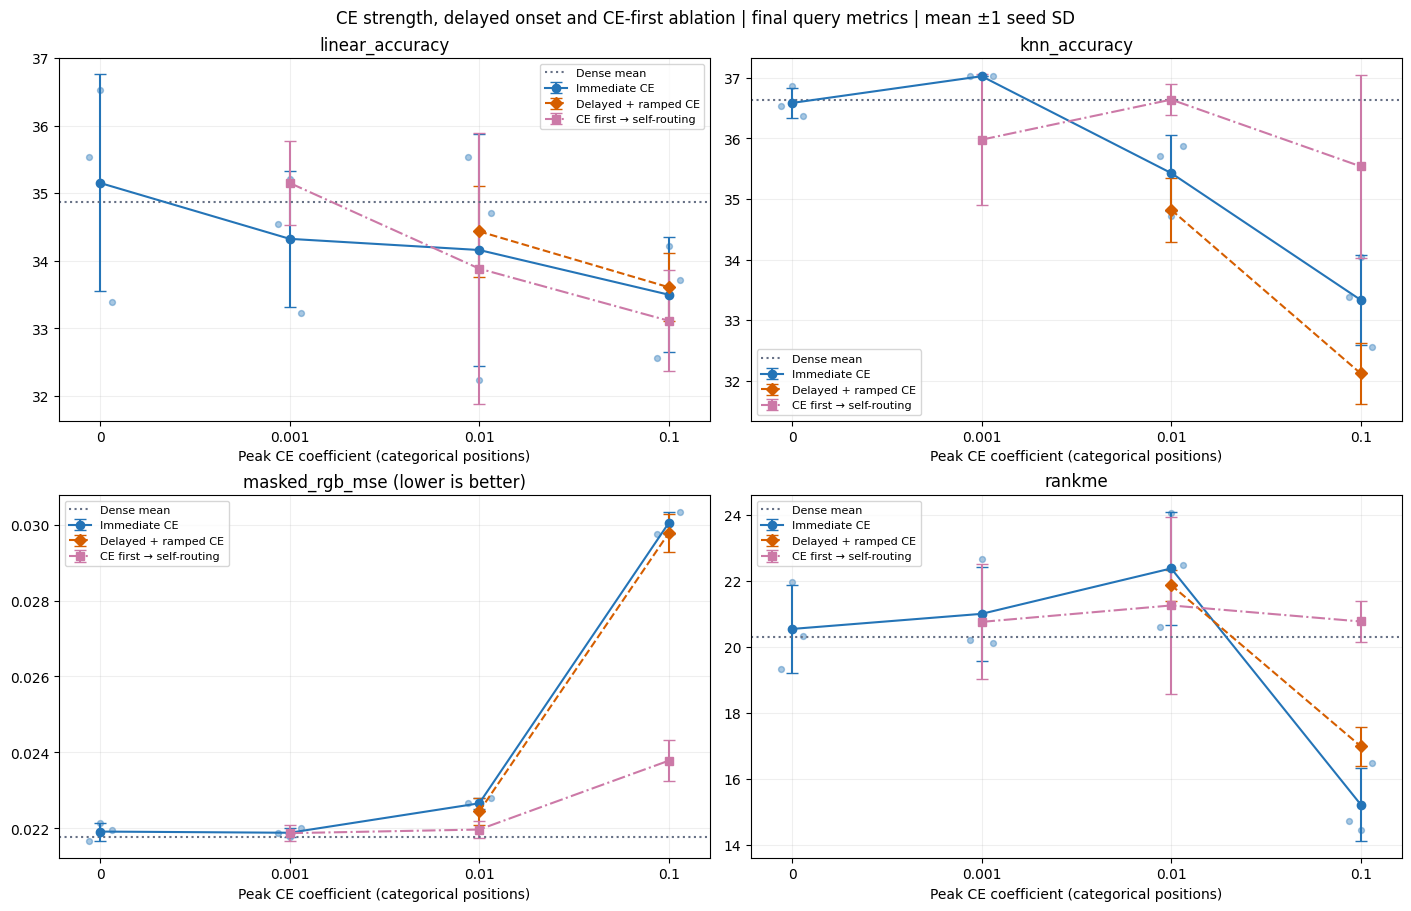

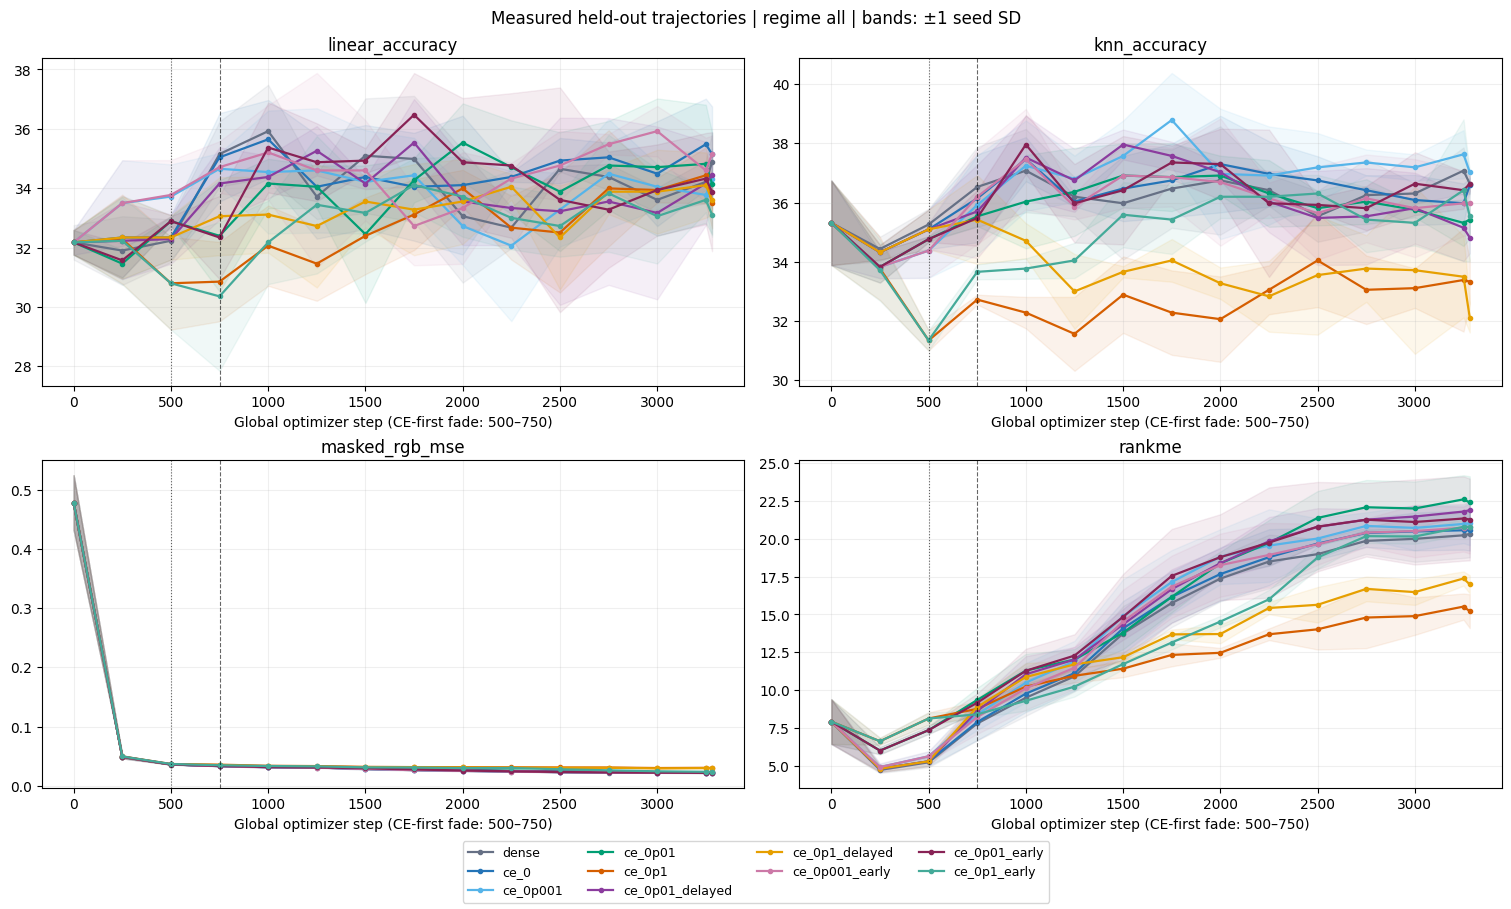

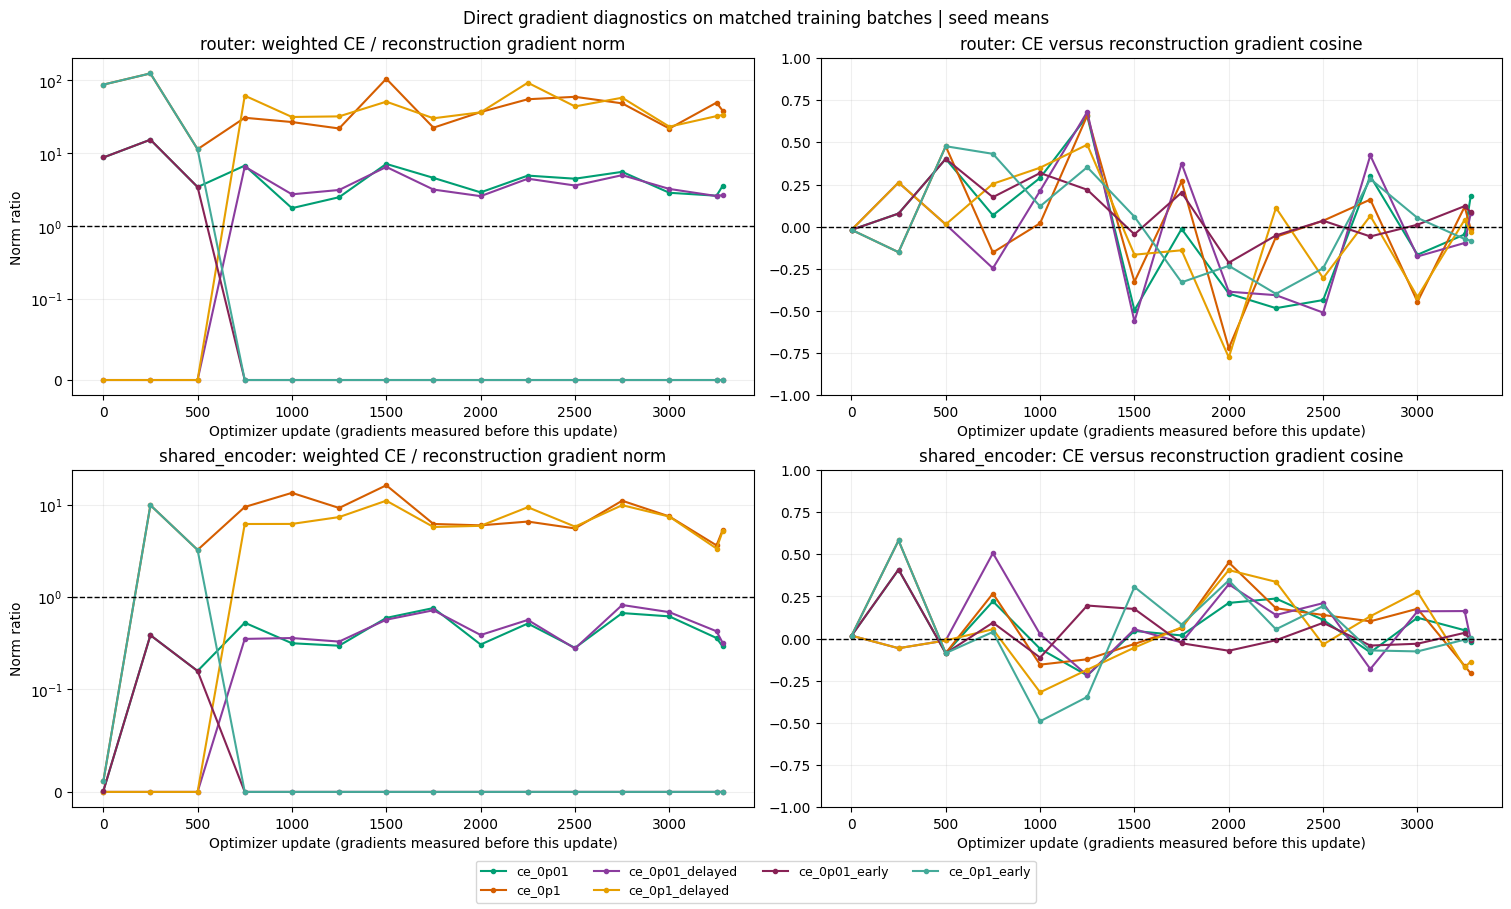

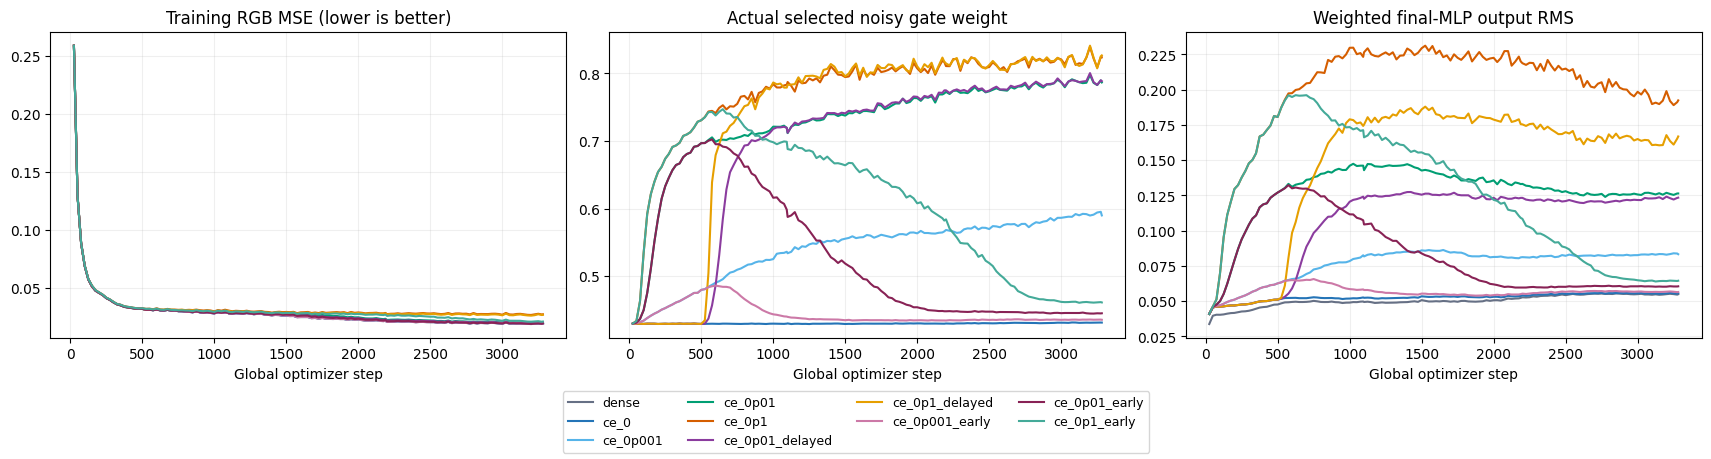

Completed paired ablation. All measurements and plots: C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-ce-ablation\20261029T075522835366Z


In [11]:
metric_names = ["linear_accuracy", "knn_accuracy", "masked_rgb_mse", "rankme"]
final_metrics = metrics.loc[metrics["global_step"] == total_updates].copy()
paired_rows = []
for (seed, regime), part in final_metrics.groupby(["seed", "regime"]):
    indexed = part.set_index("arm")
    for metric in metric_names:
        scale = 100 if metric.endswith("accuracy") else 1
        for arm in arm_names:
            for baseline in ["dense", "ce_0"]:
                if arm != baseline:
                    paired_rows.append(
                        {
                            "seed": seed,
                            "regime": regime,
                            "arm": arm,
                            "baseline": baseline,
                            "metric": metric,
                            "delta": scale * (indexed.loc[arm, metric] - indexed.loc[baseline, metric]),
                        }
                    )
        for weight_label in ["0p01", "0p1"]:
            delayed, immediate = f"ce_{weight_label}_delayed", f"ce_{weight_label}"
            paired_rows.append(
                {
                    "seed": seed,
                    "regime": regime,
                    "arm": delayed,
                    "baseline": immediate,
                    "metric": metric,
                    "delta": scale * (indexed.loc[delayed, metric] - indexed.loc[immediate, metric]),
                }
            )
        for weight_label in ["0p001", "0p01", "0p1"]:
            early, immediate = f"ce_{weight_label}_early", f"ce_{weight_label}"
            for baseline in [immediate, *([f"ce_{weight_label}_delayed"] if weight_label != "0p001" else [])]:
                paired_rows.append(
                    {
                        "seed": seed,
                        "regime": regime,
                        "arm": early,
                        "baseline": baseline,
                        "metric": metric,
                        "delta": scale * (indexed.loc[early, metric] - indexed.loc[baseline, metric]),
                    }
                )
paired = pd.DataFrame(paired_rows)
paired.to_csv(run_dir / "paired_deltas.csv", index=False)
summary_rows = []
for keys, part in paired.groupby(["regime", "arm", "baseline", "metric"]):
    values = part["delta"].to_numpy()
    spread = float(values.std(ddof=1)) if len(values) > 1 else float("nan")
    half_width = (
        float(student_t.ppf(0.975, len(values) - 1) * spread / np.sqrt(len(values)))
        if len(values) > 1
        else float("nan")
    )
    summary_rows.append(
        {
            **dict(zip(["regime", "arm", "baseline", "metric"], keys, strict=True)),
            "seeds": len(values),
            "mean_delta": values.mean(),
            "seed_sd": spread,
            "ci95_low": values.mean() - half_width,
            "ci95_high": values.mean() + half_width,
        }
    )
paired_summary = pd.DataFrame(summary_rows)
paired_summary.to_csv(run_dir / "paired_summary.csv", index=False)
endpoint_summary = final_metrics.groupby(["arm", "regime"])[metric_names].agg(["mean", "std"])
endpoint_summary.to_csv(run_dir / "endpoint_summary.csv")
show(endpoint_summary.xs("all", level="regime"))
show(paired_summary.loc[(paired_summary["regime"] == "all") & (paired_summary["baseline"] == "ce_0")])

colors = dict(
    zip(
        arm_names,
        ["#667085", "#2474b7", "#56b4e9", "#009e73", "#d55e00", "#8b3c9e", "#e69f00", "#cc79a7", "#882255", "#44aa99"],
        strict=True,
    )
)
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
constant_names = ["ce_0", "ce_0p001", "ce_0p01", "ce_0p1"]
weight_labels = ["0", "0.001", "0.01", "0.1"]
for ax, metric in zip(axes.flat, metric_names, strict=True):
    scale = 100 if metric.endswith("accuracy") else 1
    measured = final_metrics.loc[final_metrics["regime"] == "all"]
    means = [measured.loc[measured["arm"] == arm, metric].mean() * scale for arm in constant_names]
    errors = [
        measured.loc[measured["arm"] == arm, metric].std(ddof=1) * scale if len(seeds) > 1 else 0
        for arm in constant_names
    ]
    ax.errorbar(range(4), means, yerr=errors, fmt="o-", color="#2474b7", capsize=4, label="Immediate CE")
    for x, arm in enumerate(constant_names):
        points = measured.loc[measured["arm"] == arm, metric].to_numpy() * scale
        ax.scatter(
            np.full(len(points), x) + np.linspace(-0.06, 0.06, len(points)), points, color="#2474b7", alpha=0.4, s=18
        )
    delayed_means = [
        measured.loc[measured["arm"] == arm, metric].mean() * scale for arm in ["ce_0p01_delayed", "ce_0p1_delayed"]
    ]
    delayed_sd = [
        measured.loc[measured["arm"] == arm, metric].std(ddof=1) * scale if len(seeds) > 1 else 0
        for arm in ["ce_0p01_delayed", "ce_0p1_delayed"]
    ]
    ax.errorbar(
        [2, 3], delayed_means, yerr=delayed_sd, fmt="D--", color="#d55e00", capsize=4, label="Delayed + ramped CE"
    )
    early_names = ["ce_0p001_early", "ce_0p01_early", "ce_0p1_early"]
    early_means = [measured.loc[measured["arm"] == arm, metric].mean() * scale for arm in early_names]
    early_sd = [
        measured.loc[measured["arm"] == arm, metric].std(ddof=1) * scale if len(seeds) > 1 else 0 for arm in early_names
    ]
    ax.errorbar(
        [1, 2, 3], early_means, yerr=early_sd, fmt="s-.", color="#cc79a7", capsize=4, label="CE first → self-routing"
    )
    dense_values = measured.loc[measured["arm"] == "dense", metric].to_numpy() * scale
    ax.axhline(dense_values.mean(), color=colors["dense"], linestyle=":", label="Dense mean")
    ax.set_xticks(range(4), weight_labels)
    ax.set(
        xlabel="Peak CE coefficient (categorical positions)",
        title=metric + (" (lower is better)" if metric == "masked_rgb_mse" else ""),
    )
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("CE strength, delayed onset and CE-first ablation | final query metrics | mean ±1 seed SD")
fig.savefig(run_dir / "ce_weight_response.png", dpi=160)
fig.savefig(run_dir / "ce_weight_response.pdf")
show(fig)
plt.close(fig)

plot_regime = "all"  # Or daytime, dawn/dusk, night.
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for ax, metric in zip(axes.flat, metric_names, strict=True):
    scale = 100 if metric.endswith("accuracy") else 1
    for arm in arm_names:
        part = metrics.loc[(metrics["arm"] == arm) & (metrics["regime"] == plot_regime)]
        stats = part.groupby("global_step")[metric].agg(["mean", "std"])
        x = stats.index.to_numpy()
        y = stats["mean"].to_numpy() * scale
        spread = stats["std"].fillna(0).to_numpy() * scale
        ax.plot(x, y, "o-", color=colors[arm], label=arm, markersize=3, linewidth=1.6)
        ax.fill_between(x, y - spread, y + spread, color=colors[arm], alpha=0.08)
    ax.axvline(early_supervised_steps, color="black", linestyle=":", linewidth=0.8, alpha=0.6)
    ax.axvline(early_supervised_steps + early_fade_steps, color="black", linestyle="--", linewidth=0.8, alpha=0.6)
    ax.set(title=metric, xlabel="Global optimizer step (CE-first fade: 500–750)")
    ax.grid(alpha=0.2)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, fontsize=9)
fig.suptitle(f"Measured held-out trajectories | regime {plot_regime} | bands: ±1 seed SD")
fig.savefig(run_dir / "heldout_step_curves.png", dpi=160)
fig.savefig(run_dir / "heldout_step_curves.pdf")
show(fig)
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for row, group in enumerate(["router", "shared_encoder"]):
    for arm in ["ce_0p01", "ce_0p1", "ce_0p01_delayed", "ce_0p1_delayed", "ce_0p01_early", "ce_0p1_early"]:
        part = gradients.loc[(gradients["arm"] == arm) & (gradients["group"] == group)]
        for ax, metric in zip(axes[row], ["weighted_ce_to_reconstruction", "ce_vs_reconstruction_cosine"], strict=True):
            stats = part.groupby("global_step")[metric].mean()
            ax.plot(stats.index, stats.values, "o-", color=colors[arm], label=arm, markersize=3)
    axes[row, 0].set(
        title=f"{group}: weighted CE / reconstruction gradient norm",
        ylabel="Norm ratio",
    )
    axes[row, 0].set_yscale("symlog", linthresh=0.1)
    axes[row, 0].axhline(1, color="black", linestyle="--", linewidth=1)
    axes[row, 1].set(title=f"{group}: CE versus reconstruction gradient cosine", ylim=(-1, 1))
    axes[row, 1].axhline(0, color="black", linestyle="--", linewidth=1)
    for ax in axes[row]:
        ax.set_xlabel("Optimizer update (gradients measured before this update)")
        ax.grid(alpha=0.2)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, fontsize=9)
fig.suptitle("Direct gradient diagnostics on matched training batches | seed means")
fig.savefig(run_dir / "gradient_tradeoffs.png", dpi=160)
fig.savefig(run_dir / "gradient_tradeoffs.pdf")
show(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
for arm in arm_names:
    part = training.loc[training["arm"] == arm]
    for ax, metric in zip(axes, ["reconstruction", "selected_gate_mean", "mlp_output_rms"], strict=True):
        stats = part.groupby("global_step")[metric].mean()
        if stats.notna().any():
            ax.plot(stats.index, stats.values, color=colors[arm], label=arm)
for ax, title in zip(
    axes,
    ["Training RGB MSE (lower is better)", "Actual selected noisy gate weight", "Weighted final-MLP output RMS"],
    strict=True,
):
    ax.set(title=title, xlabel="Global optimizer step")
    ax.grid(alpha=0.2)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=4, fontsize=9)
fig.savefig(run_dir / "reconstruction_gate_amplitude.png", dpi=160)
fig.savefig(run_dir / "reconstruction_gate_amplitude.pdf")
show(fig)
plt.close(fig)
write_status(state="complete", completed_models=len(arms) * len(seeds))
print(f"Completed paired ablation. All measurements and plots: {run_dir}")

## Evaluation dashboards matching the previous comparison

These cells read the saved ablation measurements without retraining. Run the next cell directly
to redraw **linear-probe accuracy, frozen kNN accuracy, masked RGB MSE and RankMe**, overall and
by regime, for all ten arms. Set `evaluation_run_dir` to select another completed run.
Labeled bars are means, black points are individual seeds, and error bars are ±1 seed SD,
not confidence intervals. Each metric keeps its own units; RGB MSE is scaled by 1,000 for readability.
The paired-difference heatmaps compare each MoE with the same-seed self-routing control.
The earlier step curves and CE/gradient diagnostics remain above.


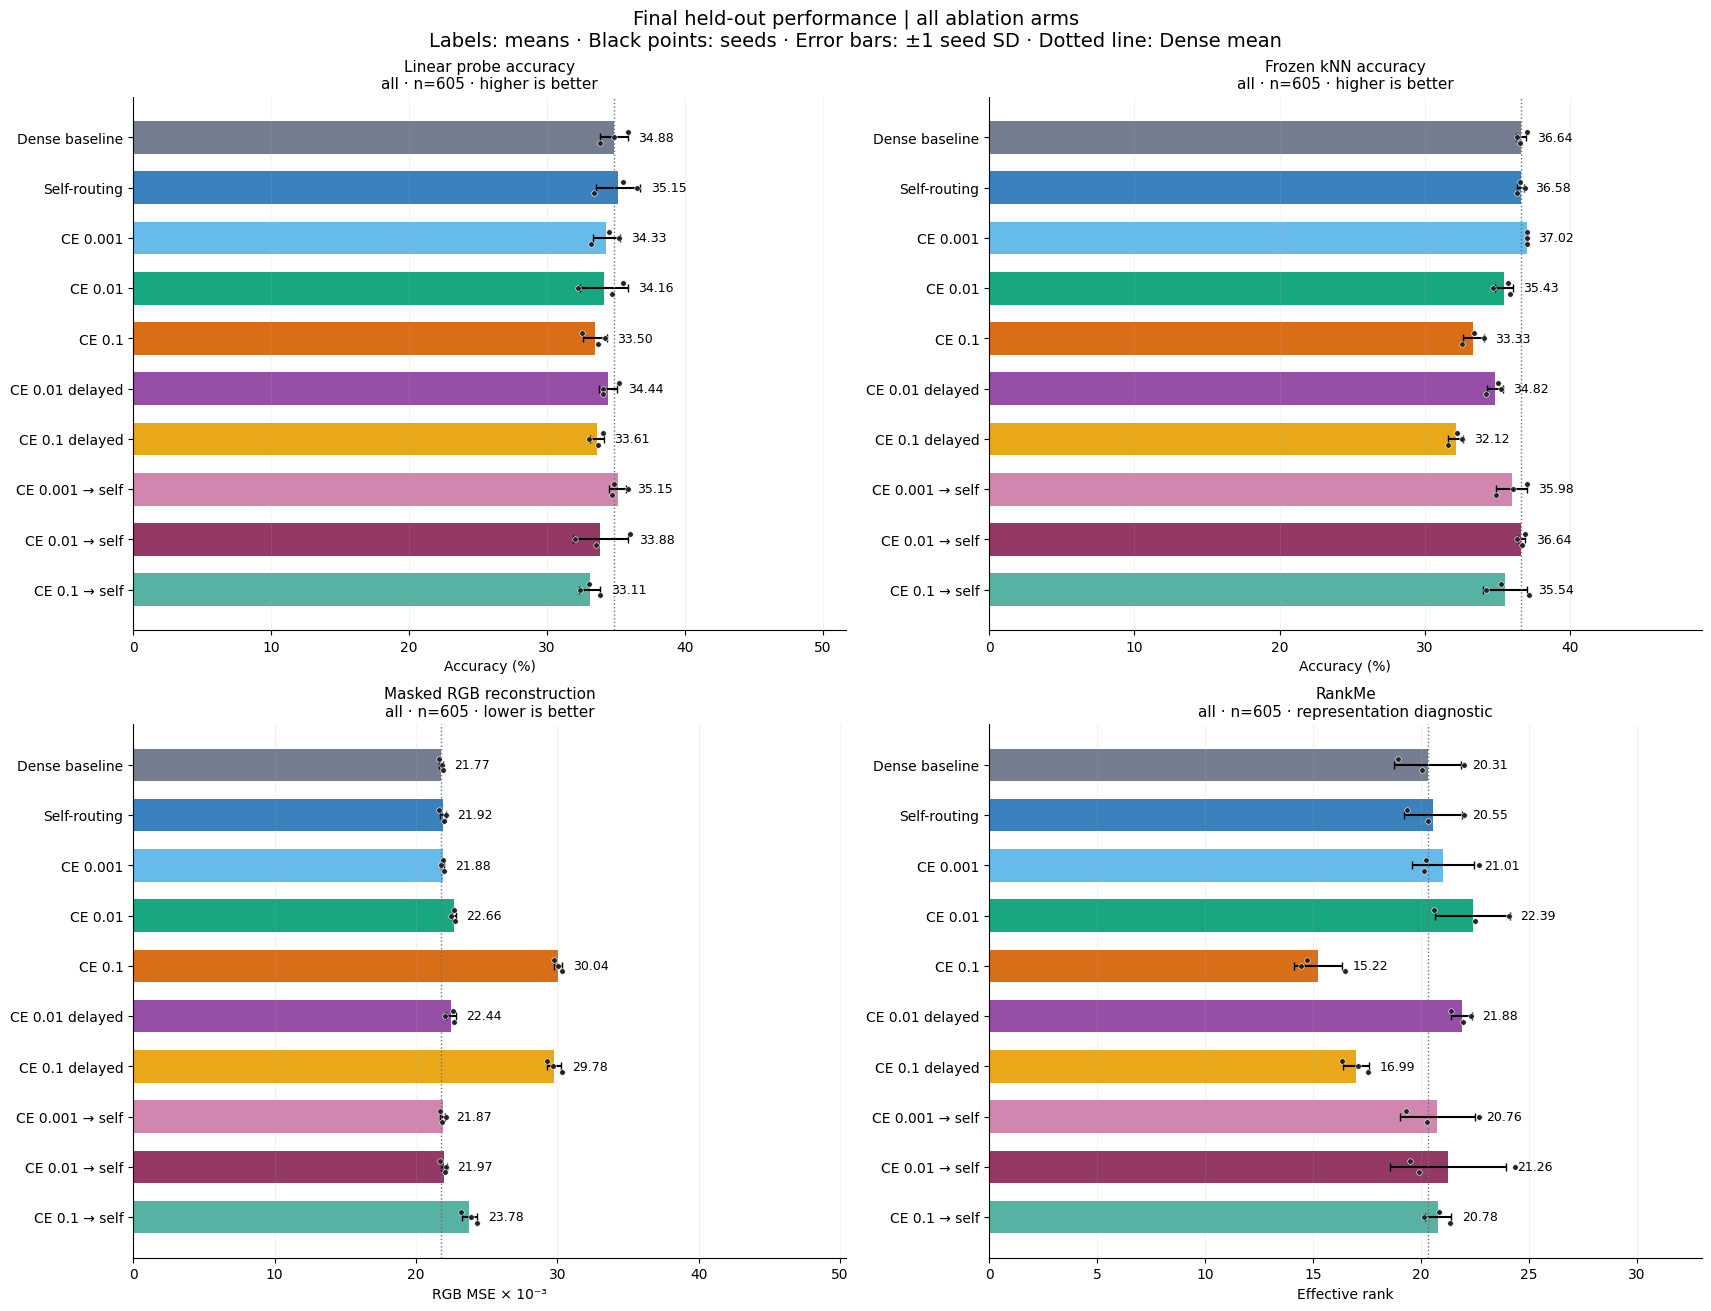

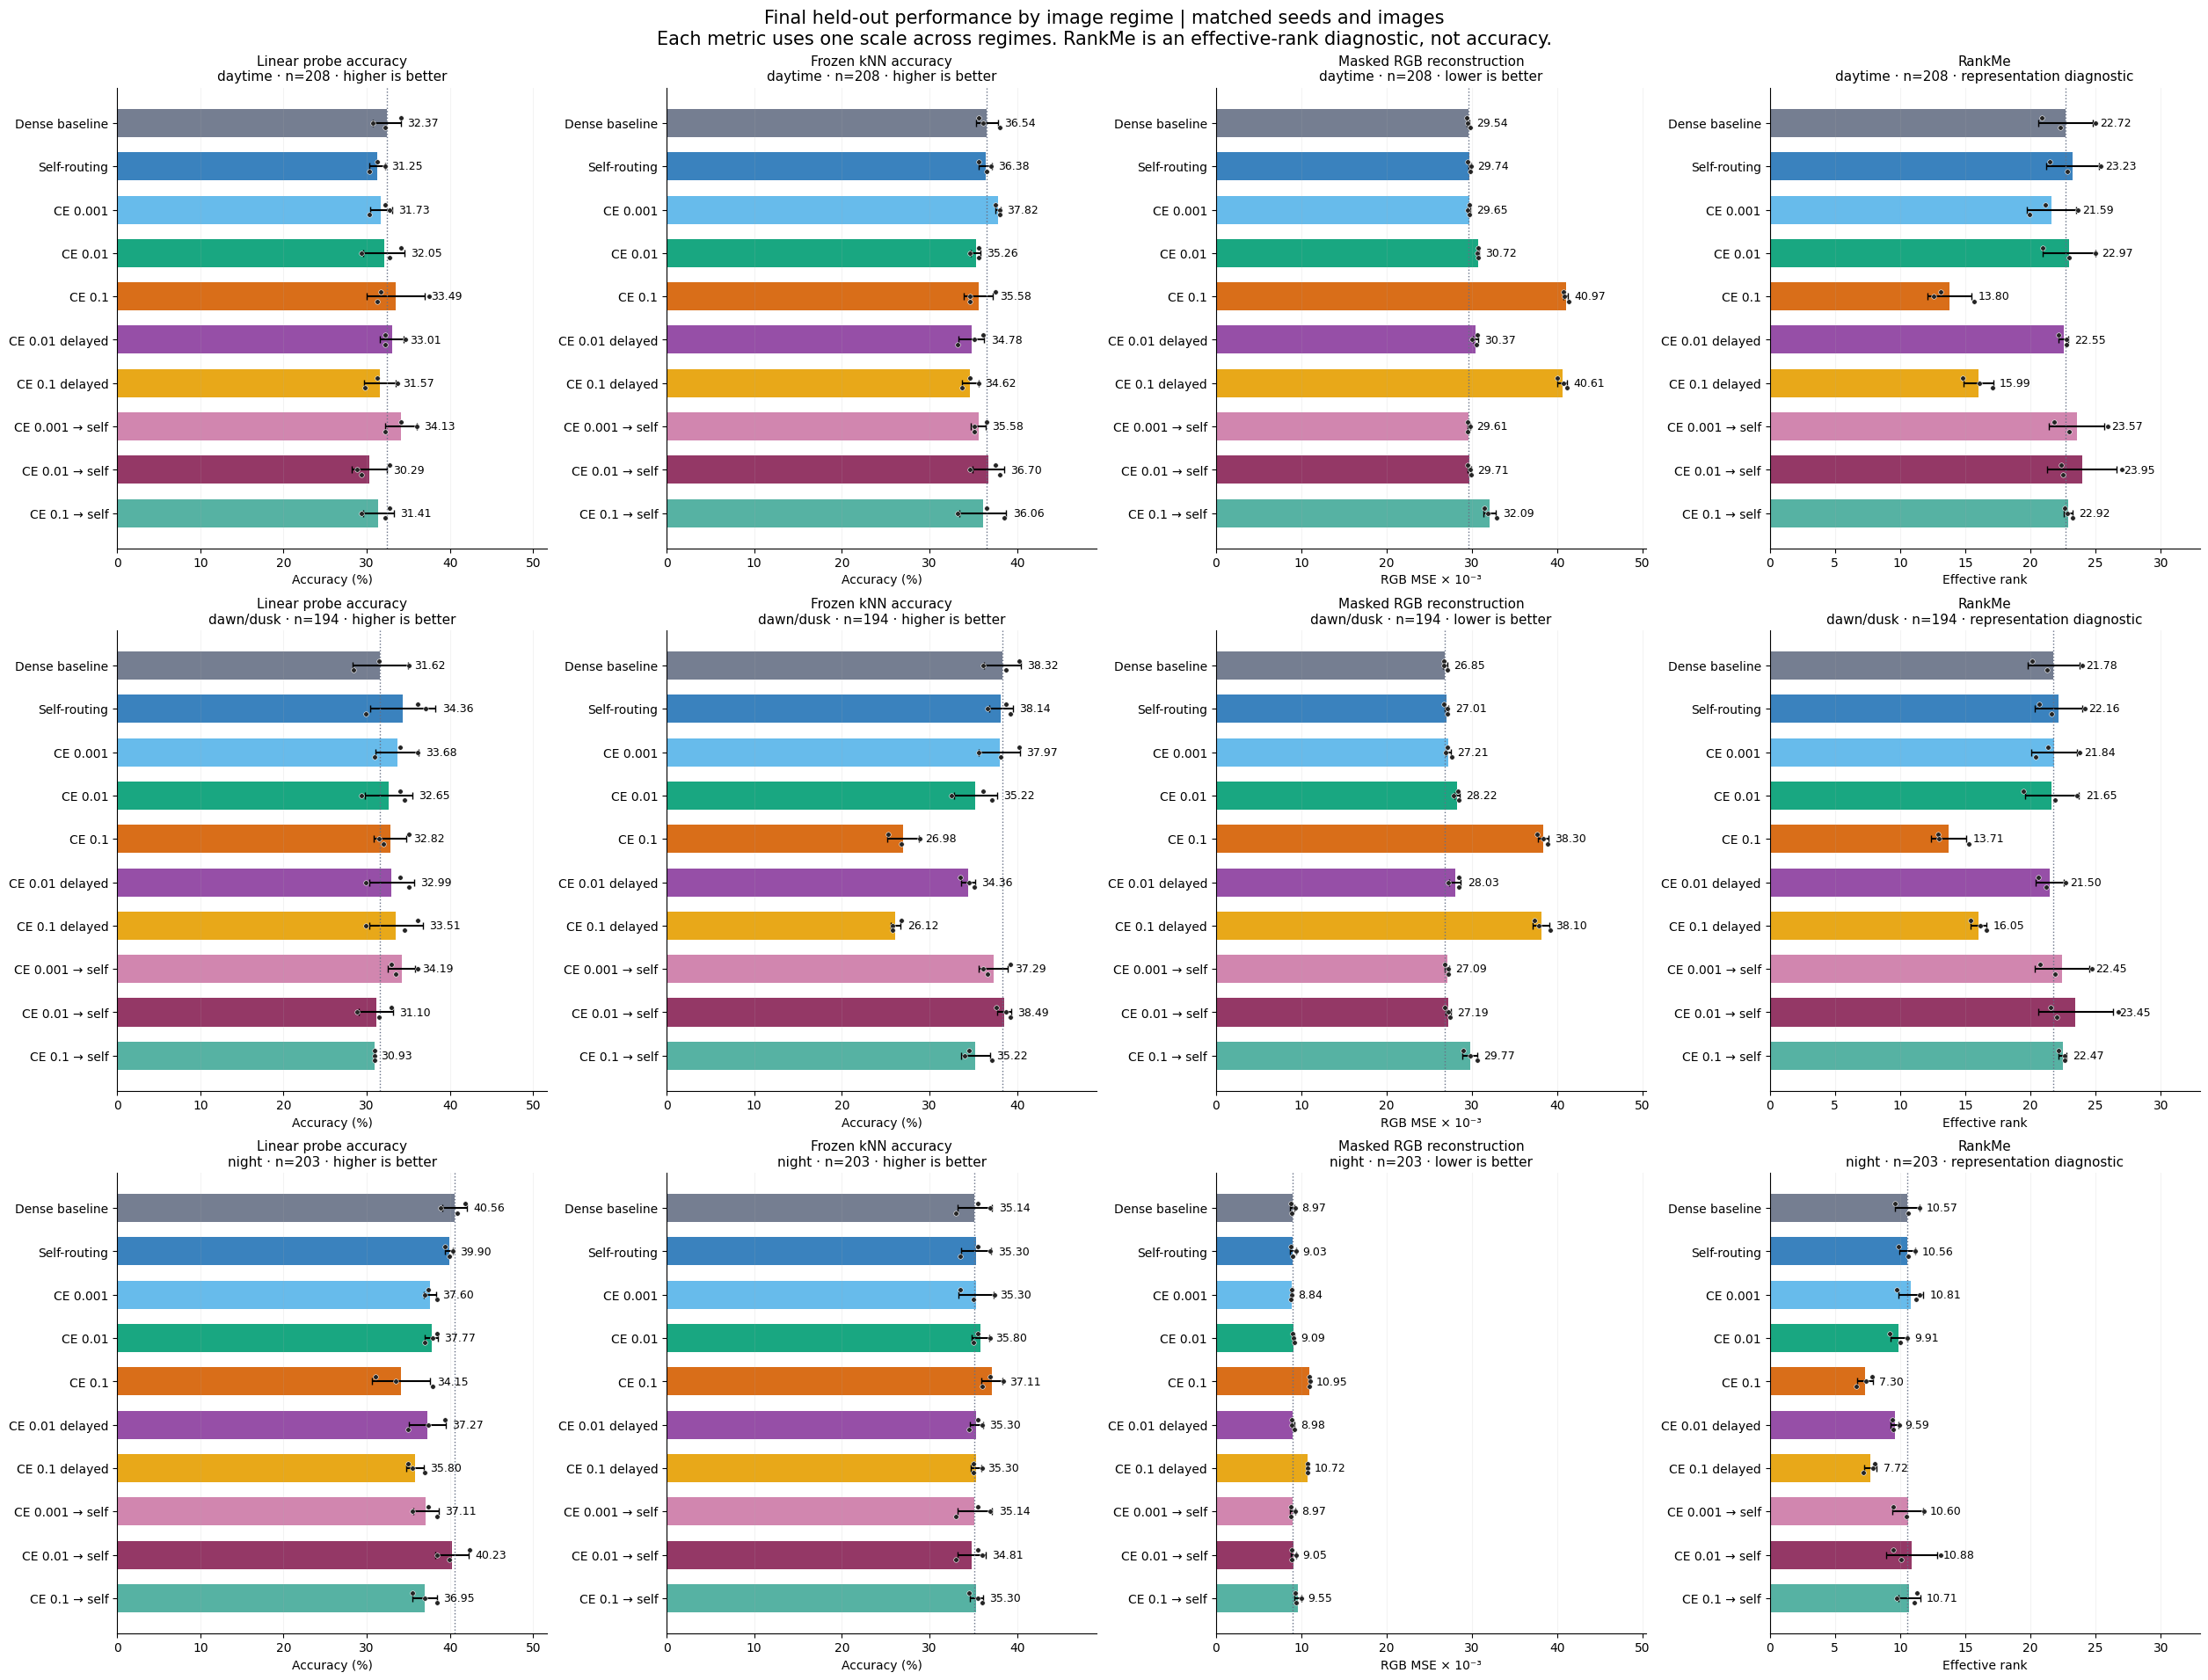

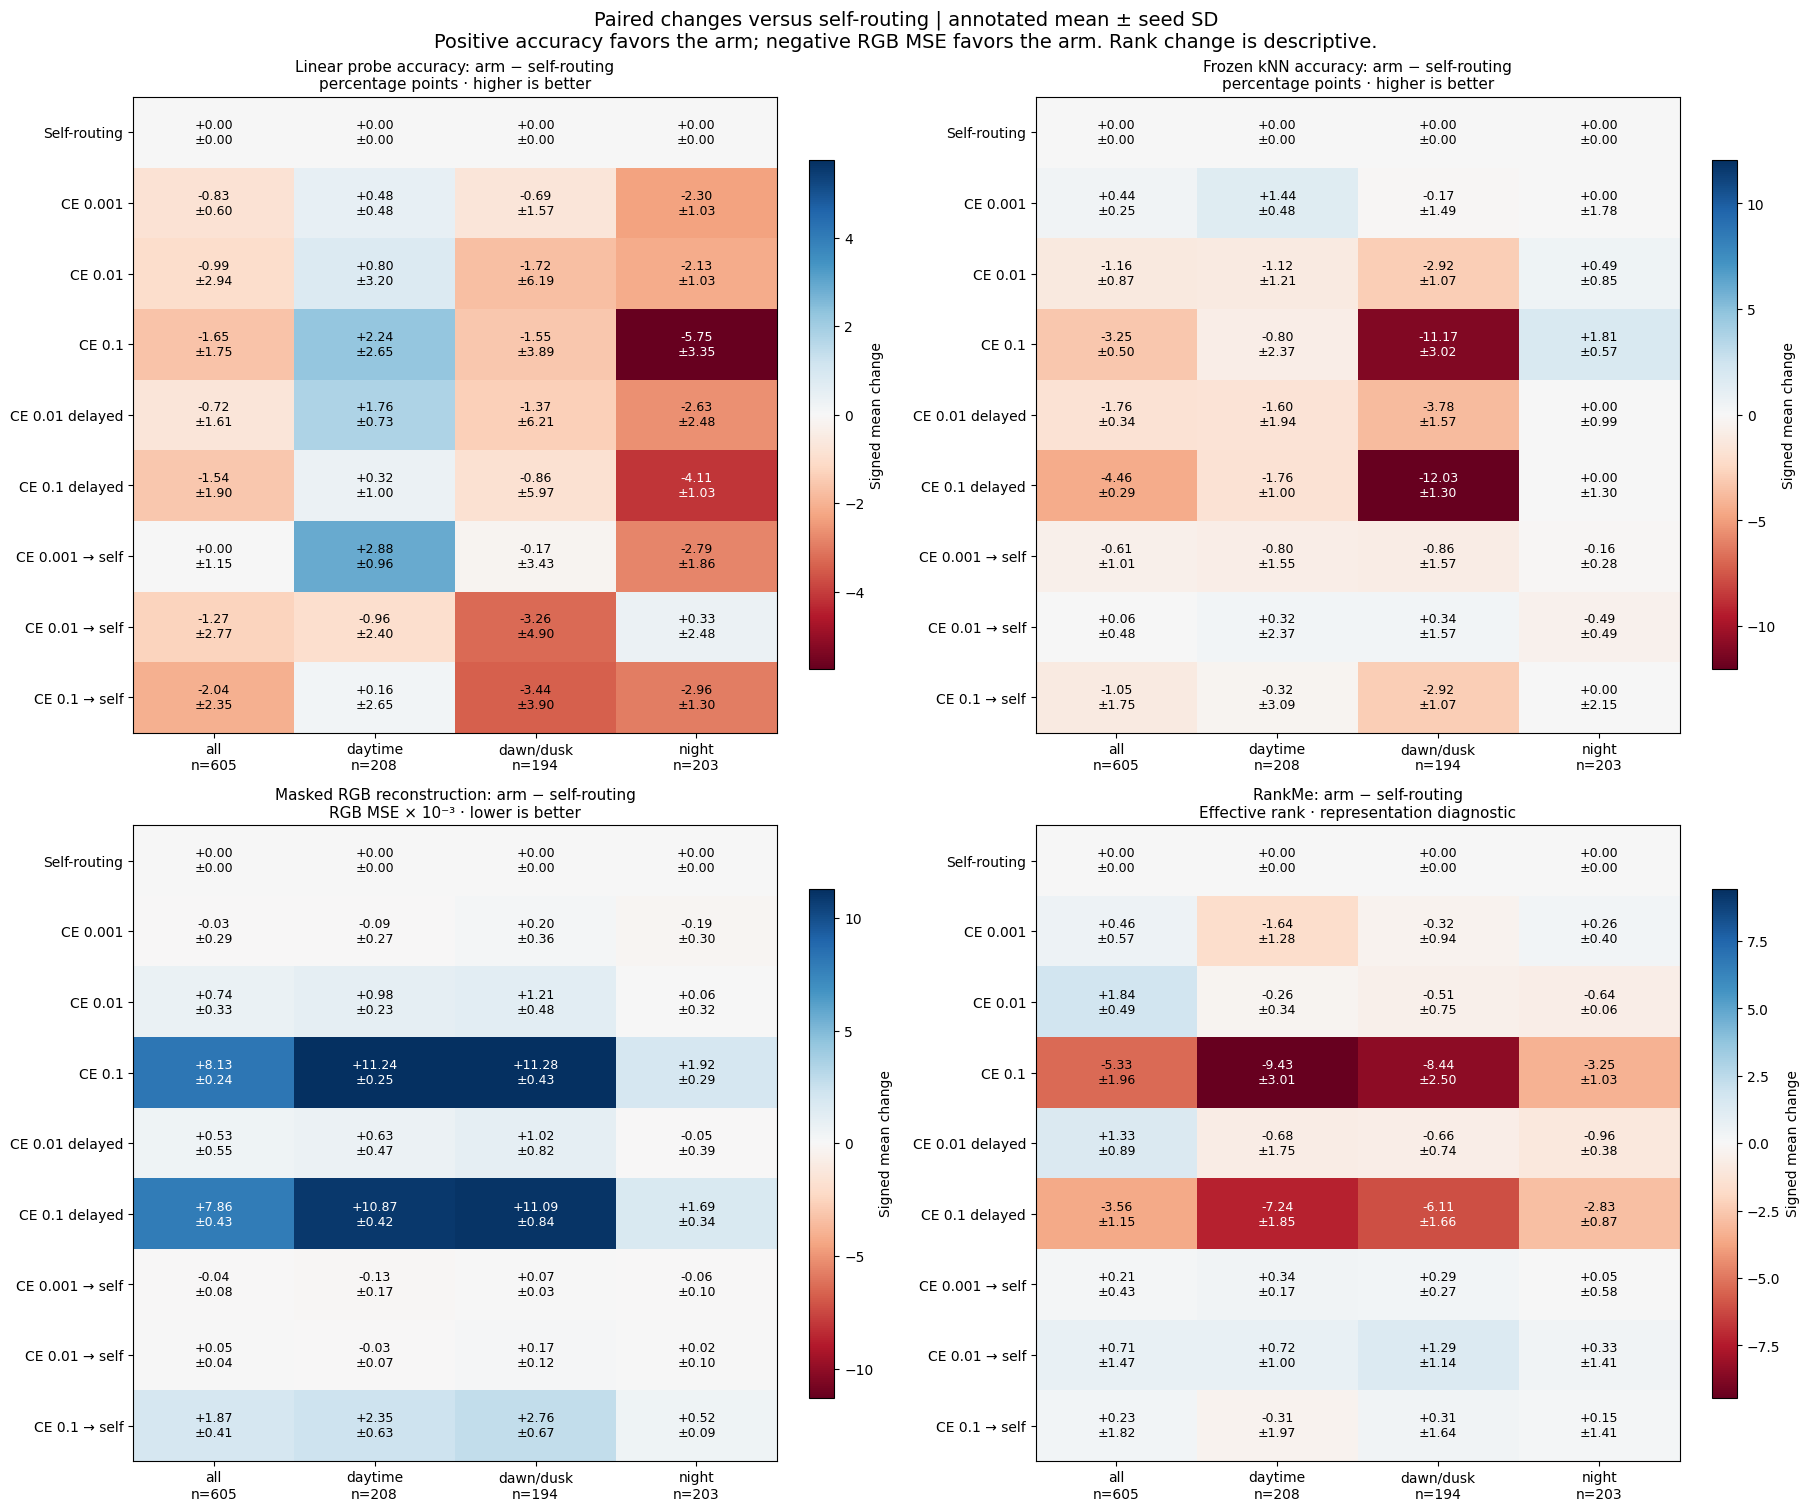

Evaluation figures use saved full-run measurements: C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-ce-ablation\20261029T075522835366Z


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as eval_plt
import numpy as np
import pandas as pd
from IPython.display import display as eval_show
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.image import AxesImage

# Run this section directly on saved measurements; no training cells are required.
evaluation_run_dir = None
evaluation_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir())
if evaluation_run_dir is None:
    evaluation_run_dir = globals().get("run_dir")
    if evaluation_run_dir is None:
        evaluation_runs = sorted((evaluation_root / "outputs/moe-router-ce-ablation").glob("*/endpoint_summary.csv"))
        if not evaluation_runs:
            raise FileNotFoundError("Set evaluation_run_dir to a completed ablation run.")
        evaluation_run_dir = evaluation_runs[-1].parent
evaluation_run_dir = Path(evaluation_run_dir)
evaluation_config = json.loads((evaluation_run_dir / "protocol.json").read_text())["protocol"]
evaluation_output = evaluation_run_dir / "evaluation_visualizations"
evaluation_output.mkdir(exist_ok=True)
evaluation_arms = [a["name"] for a in evaluation_config["arms"]]
evaluation_moes = [a["name"] for a in evaluation_config["arms"] if a["kind"] == "moe"]
evaluation_seeds = evaluation_config["seeds"]
evaluation_labels = {
    "dense": "Dense baseline",
    "ce_0": "Self-routing",
    "ce_0p001": "CE 0.001",
    "ce_0p01": "CE 0.01",
    "ce_0p1": "CE 0.1",
    "ce_0p01_delayed": "CE 0.01 delayed",
    "ce_0p1_delayed": "CE 0.1 delayed",
    "ce_0p001_early": "CE 0.001 → self",
    "ce_0p01_early": "CE 0.01 → self",
    "ce_0p1_early": "CE 0.1 → self",
}
evaluation_colors = dict(
    zip(
        evaluation_arms,
        ["#667085", "#2474b7", "#56b4e9", "#009e73", "#d55e00", "#8b3c9e", "#e69f00", "#cc79a7", "#882255", "#44aa99"],
        strict=True,
    )
)
evaluation_regimes = ["all", "daytime", "dawn/dusk", "night"]
evaluation_specs = [
    ("linear_accuracy", "Linear probe accuracy", 100, "Accuracy (%)", "higher is better"),
    ("knn_accuracy", "Frozen kNN accuracy", 100, "Accuracy (%)", "higher is better"),
    ("masked_rgb_mse", "Masked RGB reconstruction", 1000, "RGB MSE × 10⁻³", "lower is better"),
    ("rankme", "RankMe", 1, "Effective rank", "representation diagnostic"),
]
evaluation_data = pd.read_csv(evaluation_run_dir / "external_metrics_by_step.csv")
evaluation_final = evaluation_data.loc[evaluation_data["global_step"].eq(evaluation_config["total_updates"])].copy()
evaluation_index = pd.MultiIndex.from_product(
    [evaluation_seeds, evaluation_arms, evaluation_regimes], names=["seed", "arm", "regime"]
)
evaluation_panel = evaluation_final.set_index(["seed", "arm", "regime"])
if not evaluation_panel.index.is_unique or not evaluation_index.isin(evaluation_panel.index).all():
    raise ValueError("Missing or duplicated paired seed/arm/regime results.")
evaluation_panel = evaluation_panel.reindex(evaluation_index)
if not np.isfinite(evaluation_panel[[s[0] for s in evaluation_specs]].to_numpy()).all():
    raise ValueError("Nonfinite endpoint measurements.")
if (evaluation_final.groupby("regime")["images"].nunique() != 1).any():
    raise ValueError("Unequal query counts across compared arms.")
evaluation_counts = evaluation_final.groupby("regime")["images"].first()


def evaluation_save(fig: Figure, stem: str) -> None:
    """Embed the actual figure and save PNG/PDF copies beside the measured run."""
    for suffix in ["png", "pdf"]:
        fig.savefig(evaluation_output / f"{stem}.{suffix}", dpi=150)
    eval_show(fig)
    eval_plt.close(fig)


def evaluation_values(metric: str, regime: str, arms: list[str]) -> np.ndarray:
    """Return rows in explicit arm order and columns in paired seed order."""
    return np.array([[evaluation_panel.loc[(s, a, regime), metric] for s in evaluation_seeds] for a in arms])


def performance_axis(ax: Axes, regime: str, spec: tuple[str, str, int, str, str]) -> None:
    """Labeled means, seed points and SD bars, using the same scale across regimes."""
    metric, title, scale, unit, direction = spec
    values = evaluation_values(metric, regime, evaluation_arms) * scale
    means = values.mean(1)
    sd = values.std(1, ddof=1) if len(evaluation_seeds) > 1 else np.zeros(len(evaluation_arms))
    y = np.arange(len(evaluation_arms))
    ax.barh(
        y,
        means,
        xerr=sd if len(evaluation_seeds) > 1 else None,
        capsize=3,
        color=[evaluation_colors[a] for a in evaluation_arms],
        height=0.65,
        alpha=0.9,
    )
    for j, _seed in enumerate(evaluation_seeds):
        offset = 0.22 * (j / max(1, len(evaluation_seeds) - 1) - 0.5)
        ax.scatter(values[:, j], y + offset, s=16, c="#242424", edgecolors="white", linewidths=0.4, zorder=4)
    all_values = evaluation_panel[metric].to_numpy() * scale
    upper = float(all_values.max()) * 1.22
    ax.set_xlim(0, upper)
    for i, (mean, spread) in enumerate(zip(means, sd, strict=True)):
        ax.text(mean + spread + upper * 0.015, i, f"{mean:.2f}", va="center", fontsize=9)
    ax.axvline(means[0], color="#667085", linestyle=":", linewidth=1)
    ax.set_yticks(y, [evaluation_labels[a] for a in evaluation_arms])
    ax.invert_yaxis()
    ax.set_xlabel(unit)
    ax.set_title(f"{title}\n{regime} · n={int(evaluation_counts[regime])} · {direction}", fontsize=11)
    ax.xaxis.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = eval_plt.subplots(2, 2, figsize=(17, 13), constrained_layout=True)
for ax, spec in zip(axes.flat, evaluation_specs, strict=True):
    performance_axis(ax, "all", spec)
fig.suptitle(
    "Final held-out performance | all ablation arms\n"
    "Labels: means · Black points: seeds · Error bars: ±1 seed SD · Dotted line: Dense mean",
    fontsize=14,
)
evaluation_save(fig, "external_performance_overall")
fig, axes = eval_plt.subplots(3, 4, figsize=(25, 19), constrained_layout=True)
for row, regime in enumerate(evaluation_regimes[1:]):
    for col, spec in enumerate(evaluation_specs):
        performance_axis(axes[row, col], regime, spec)
fig.suptitle(
    "Final held-out performance by image regime | matched seeds and images\n"
    "Each metric uses one scale across regimes. RankMe is an effective-rank diagnostic, not accuracy.",
    fontsize=15,
)
evaluation_save(fig, "external_performance_by_regime")

# The color shows a signed change in the metric's own units, not an overall score.
fig, axes = eval_plt.subplots(2, 2, figsize=(18, 15), constrained_layout=True)
evaluation_delta_rows = []
for ax, (metric, title, scale, unit, direction) in zip(axes.flat, evaluation_specs, strict=True):
    means, spreads = [], []
    for arm in evaluation_moes:
        row_means, row_sd = [], []
        for regime in evaluation_regimes:
            pair = evaluation_values(metric, regime, [arm, "ce_0"]) * scale
            differences = pair[0] - pair[1]
            row_means.append(differences.mean())
            row_sd.append(differences.std(ddof=1) if len(differences) > 1 else 0)
            for seed, value in zip(evaluation_seeds, differences, strict=True):
                evaluation_delta_rows.append(
                    {"seed": seed, "arm": arm, "regime": regime, "metric": metric, "delta": value / scale}
                )
        means.append(row_means)
        spreads.append(row_sd)
    means, spreads = np.array(means), np.array(spreads)
    limit = max(float(np.abs(means).max()), 1e-6)
    image = ax.imshow(means, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
    for i, j in np.ndindex(means.shape):
        ax.text(
            j,
            i,
            f"{means[i, j]:+.2f}\n±{spreads[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(means[i, j]) > limit * 0.60 else "black",
        )
    ax.set_xticks(range(4), [f"{r}\nn={int(evaluation_counts[r])}" for r in evaluation_regimes])
    ax.set_yticks(range(len(evaluation_moes)), [evaluation_labels[a] for a in evaluation_moes])
    delta_unit = "percentage points" if scale == 100 else unit
    ax.set_title(f"{title}: arm − self-routing\n{delta_unit} · {direction}", fontsize=11)
    fig.colorbar(image, ax=ax, shrink=0.8, label="Signed mean change")
fig.suptitle(
    "Paired changes versus self-routing | annotated mean ± seed SD\n"
    "Positive accuracy favors the arm; negative RGB MSE favors the arm. Rank change is descriptive.",
    fontsize=14,
)
evaluation_save(fig, "external_paired_differences_by_regime")
pd.DataFrame(evaluation_delta_rows).to_csv(evaluation_output / "external_paired_differences.csv", index=False)
print(f"Evaluation figures use saved full-run measurements: {evaluation_run_dir}")

### Focused comparison: classification first, then self-routing

The first phase still trains reconstruction and balancing; time-of-day CE adds classification
supervision. CE stays at full strength for 500 optimizer updates, fades to zero by update 750,
and stays off thereafter. Every weight stays trainable and the same AdamW state continues.
The router can retain a regime preference after release; it is free to adapt through the
reconstruction and balancing objectives.

The plots below isolate each CE strength, mark the fade window, and show actual held-out
measurements over optimizer updates. The RGB trajectory omits the untrained checkpoint so
later reconstruction differences remain visible. The dose chart makes the different total
amounts of CE supervision explicit. A timing-only causal claim would need a dose-matched control.


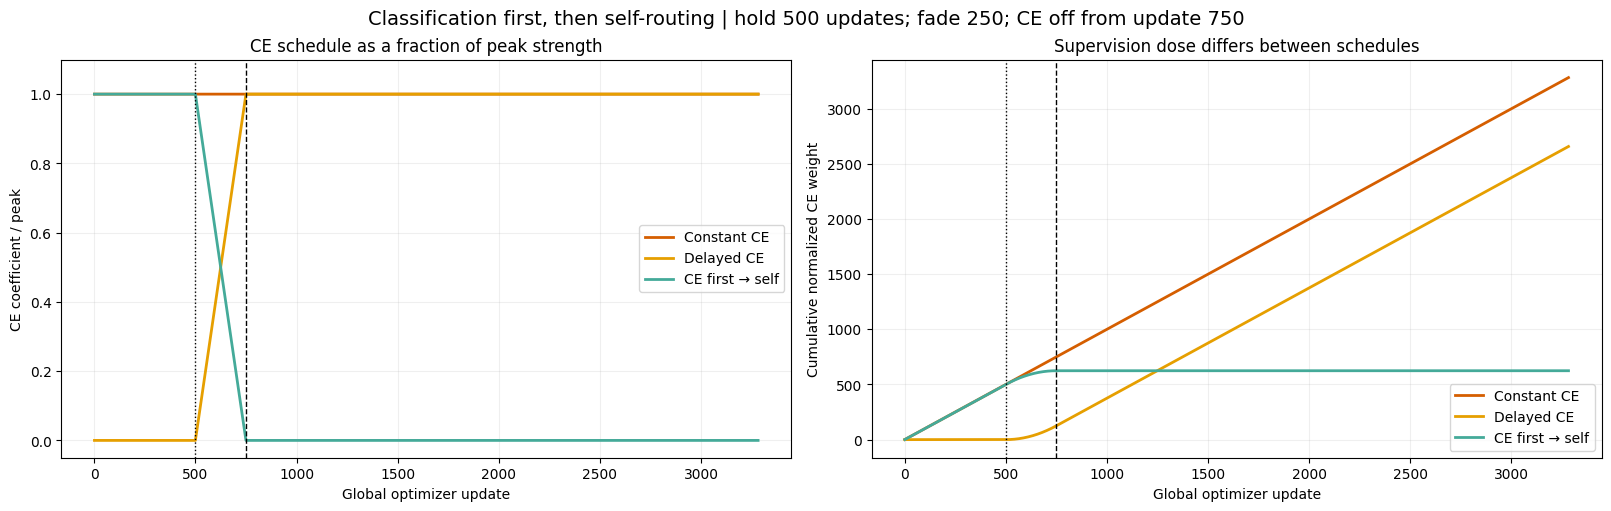

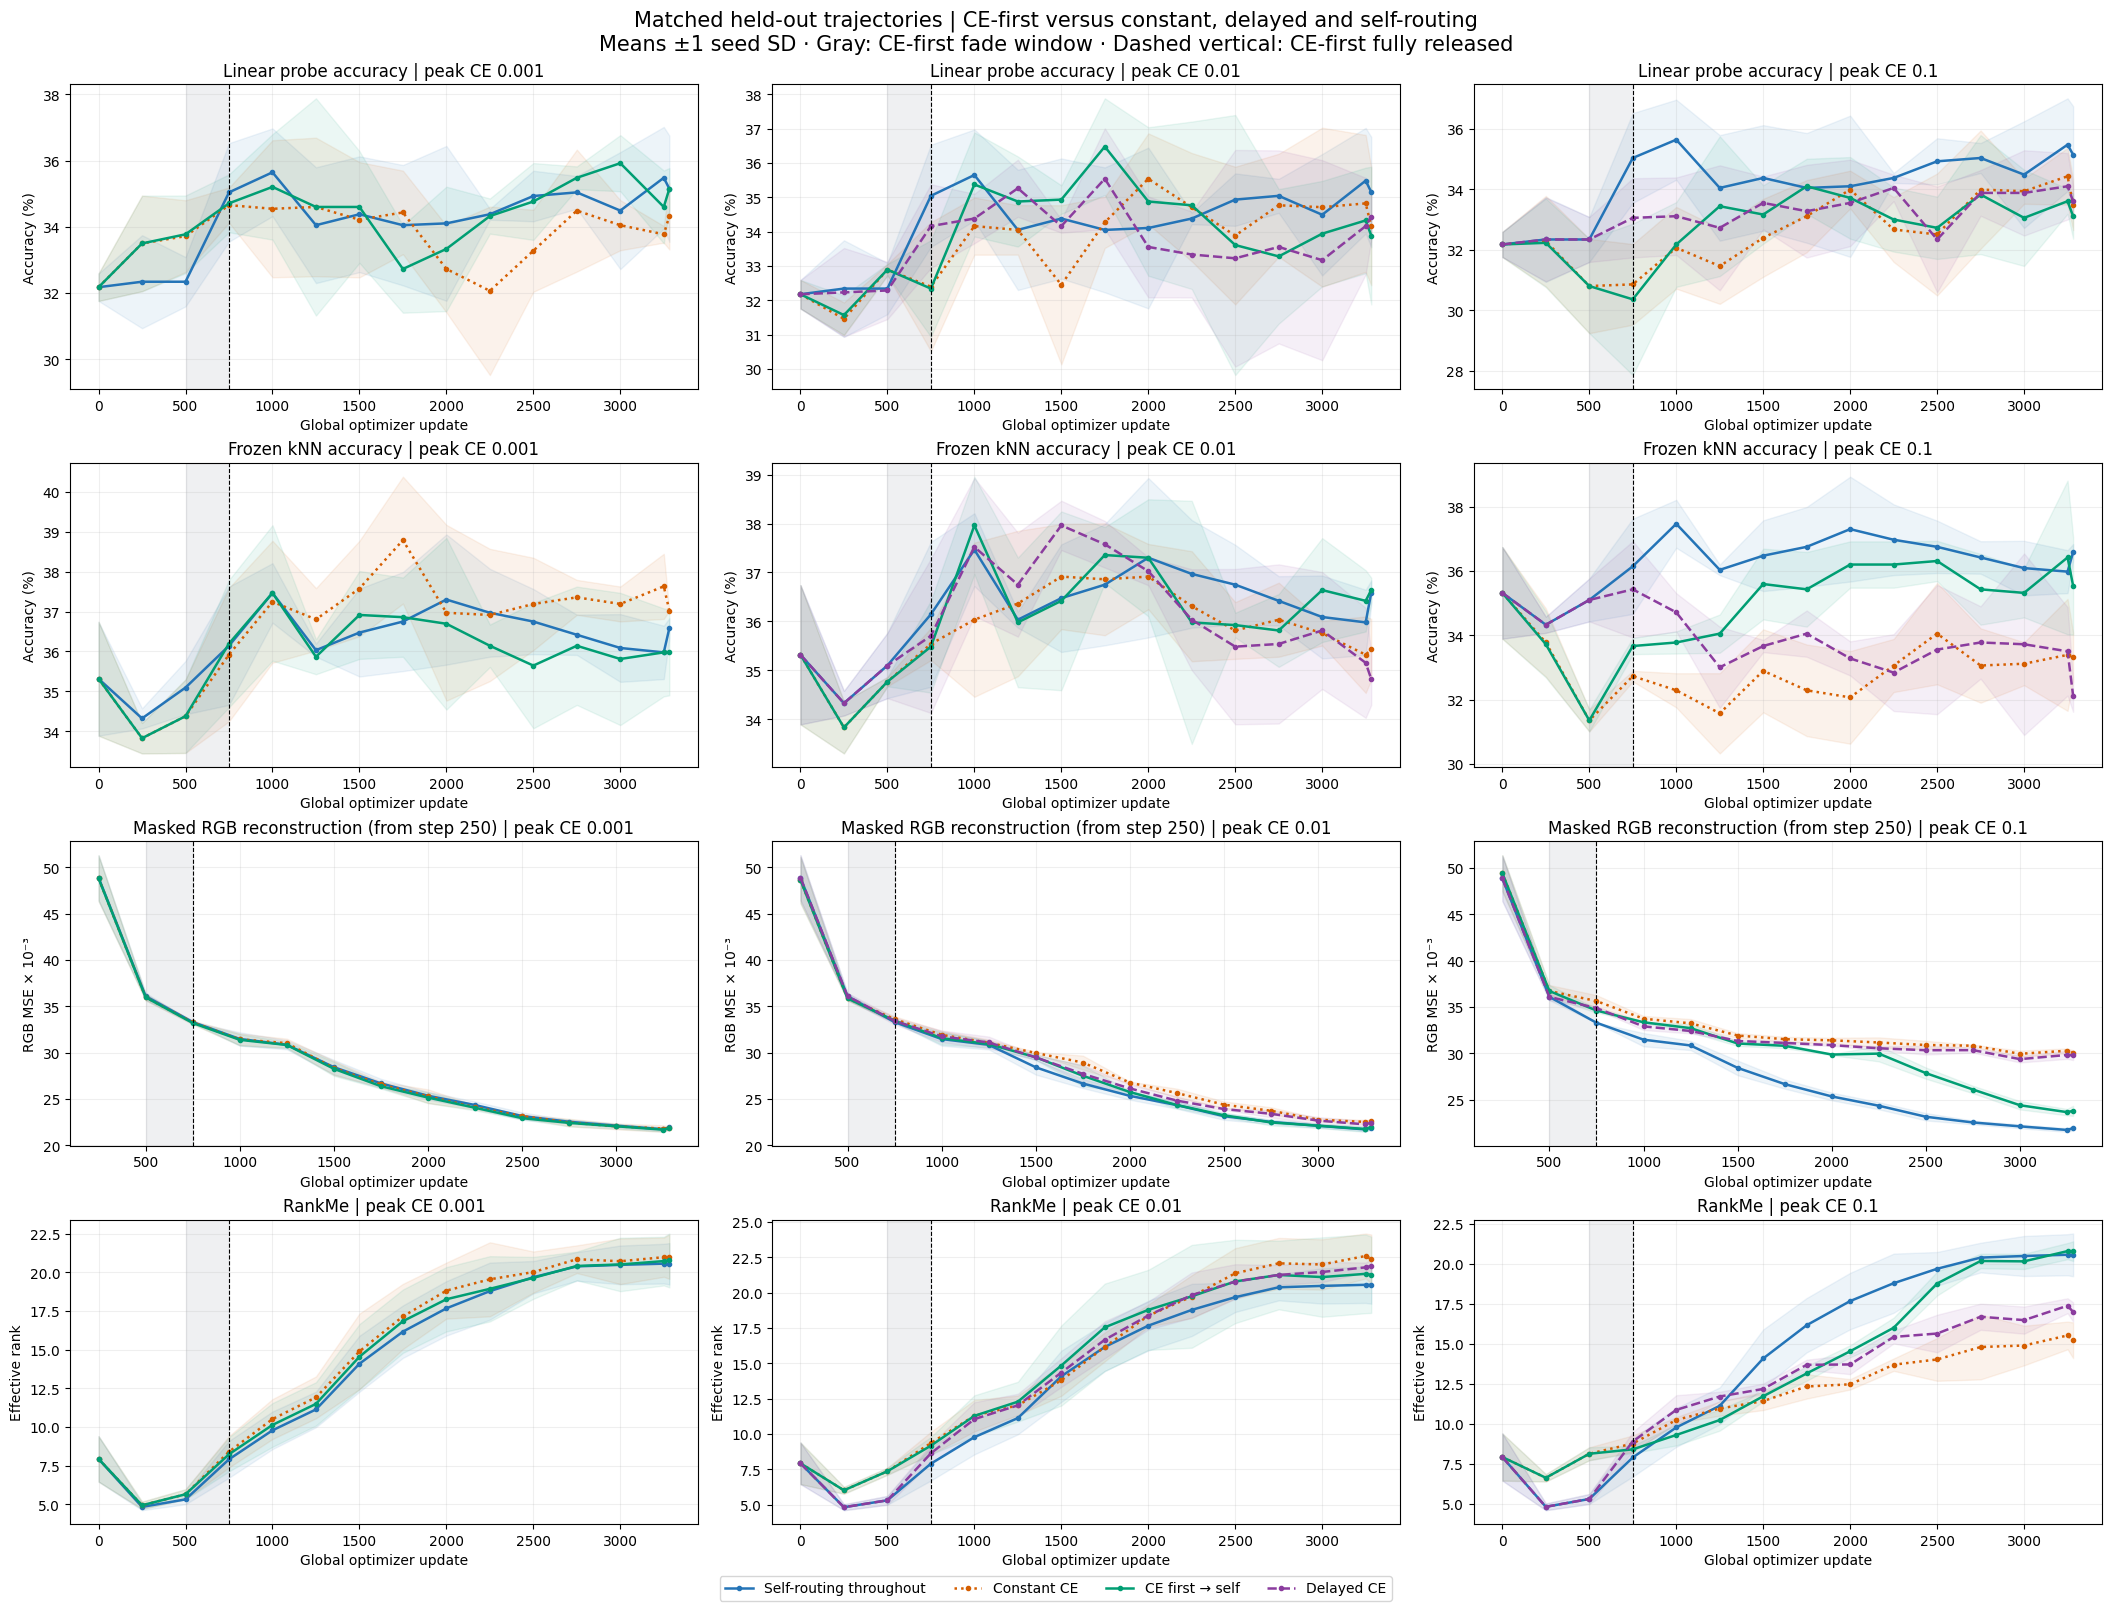

linear_accuracy           knn_accuracy            \
                          mean       std         mean       std   
arm                                                               
dense                 0.348760  0.009917     0.366391  0.003441   
ce_0                  0.351515  0.016054     0.365840  0.002525   
ce_0p001_early        0.351515  0.006258     0.359780  0.010754   
ce_0p01_early         0.338843  0.020040     0.366391  0.002525   
ce_0p1_early          0.331129  0.007453     0.355372  0.015149   

               masked_rgb_mse               rankme            
                         mean       std       mean       std  
arm                                                           
dense                0.021774  0.000145  20.312720  1.544503  
ce_0                 0.021916  0.000237  20.548183  1.334211  
ce_0p001_early       0.021874  0.000205  20.762568  1.743583  
ce_0p01_early        0.021969  0.000217  21.261655  2.696648  
ce_0p1_early         0.023782  0.000547  20.775262  0.613632

Endpoint selection remains exploratory: three paired seeds and the same reused query panel.


In [2]:
# Run after the saved-result dashboard cell. These plots do not train or update weights.
early_peak_names = [("0p001", "0.001"), ("0p01", "0.01"), ("0p1", "0.1")]
early_updates = np.arange(1, evaluation_config["total_updates"] + 1)
early_schedule_rows = []
early_profile = next(spec for spec in evaluation_config["arms"] if "supervised_steps" in spec)
early_hold = early_profile["supervised_steps"]
early_release = early_hold + early_profile["fade_steps"]


def plotted_ce_schedule(spec: dict) -> np.ndarray:
    """Draw the saved protocol's per-update schedule, independently of image-weighted log windows."""
    if "supervised_steps" in spec:
        fade = spec["fade_steps"]
        fraction = (
            np.clip(1 - (early_updates - spec["supervised_steps"]) / fade, 0, 1)
            if fade
            else (early_updates <= spec["supervised_steps"]).astype(float)
        )
    else:
        fraction = (
            np.clip((early_updates - spec["delay"]) / spec["ramp"], 0, 1)
            if spec["ramp"]
            else (early_updates > spec["delay"]).astype(float)
        )
    return fraction * spec["ce_weight"]


fig, axes = eval_plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
for arm, label, color in [
    ("ce_0p1", "Constant CE", "#d55e00"),
    ("ce_0p1_delayed", "Delayed CE", "#e69f00"),
    ("ce_0p1_early", "CE first → self", "#44aa99"),
]:
    spec = next(s for s in evaluation_config["arms"] if s["name"] == arm)
    values = plotted_ce_schedule(spec)
    fraction = values / spec["ce_weight"]
    axes[0].plot(early_updates, fraction, label=label, color=color, linewidth=2)
    axes[1].plot(early_updates, fraction.cumsum(), label=label, color=color, linewidth=2)
for spec in evaluation_config["arms"]:
    values = plotted_ce_schedule(spec)
    early_schedule_rows.append(
        {
            "arm": spec["name"],
            "peak_ce": spec["ce_weight"],
            "ce_at_final_update": values[-1],
            "integrated_ce_weight": values.sum(),
            "nonzero_ce_updates": int((values > 0).sum()),
        }
    )
for ax in axes:
    ax.axvline(early_hold, color="black", linestyle=":", linewidth=1)
    ax.axvline(early_release, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Global optimizer update")
    ax.grid(alpha=0.2)
    ax.legend()
axes[0].set(title="CE schedule as a fraction of peak strength", ylabel="CE coefficient / peak", ylim=(-0.05, 1.10))
axes[1].set(title="Supervision dose differs between schedules", ylabel="Cumulative normalized CE weight")
fig.suptitle(
    f"Classification first, then self-routing | hold {early_hold} updates; "
    f"fade {early_profile['fade_steps']}; CE off from update {early_release}",
    fontsize=14,
)
evaluation_save(fig, "early_ce_schedule_and_dose")
pd.DataFrame(early_schedule_rows).to_csv(evaluation_output / "ce_schedule_doses.csv", index=False)

fig, axes = eval_plt.subplots(4, 3, figsize=(21, 16), constrained_layout=True)
early_styles = {
    "self": ("#2474b7", "-", "Self-routing throughout"),
    "constant": ("#d55e00", ":", "Constant CE"),
    "delayed": ("#8b3c9e", "--", "Delayed CE"),
    "early": ("#009e73", "-", "CE first → self"),
}
for col, (weight_name, weight_label) in enumerate(early_peak_names):
    comparisons = [("ce_0", "self"), (f"ce_{weight_name}", "constant"), (f"ce_{weight_name}_early", "early")]
    if weight_name != "0p001":
        comparisons.append((f"ce_{weight_name}_delayed", "delayed"))
    for row, (metric, title, scale, unit, _direction) in enumerate(evaluation_specs):
        ax = axes[row, col]
        for arm, style in comparisons:
            part = evaluation_data.loc[evaluation_data["arm"].eq(arm) & evaluation_data["regime"].eq("all")]
            if metric == "masked_rgb_mse":
                part = part.loc[part["global_step"].gt(0)]
            stats = part.groupby("global_step")[metric].agg(["mean", "std"])
            x = stats.index.to_numpy()
            mean = stats["mean"].to_numpy() * scale
            sd = stats["std"].fillna(0).to_numpy() * scale
            color, line, label = early_styles[style]
            ax.plot(x, mean, color=color, linestyle=line, linewidth=1.8, marker="o", markersize=3, label=label)
            ax.fill_between(x, mean - sd, mean + sd, color=color, alpha=0.08)
        ax.axvspan(early_hold, early_release, color="#667085", alpha=0.10)
        ax.axvline(early_release, color="black", linestyle="--", linewidth=0.8)
        ax.set(title=f"{title} | peak CE {weight_label}", xlabel="Global optimizer update", ylabel=unit)
        ax.grid(alpha=0.2)
        if metric == "masked_rgb_mse":
            ax.set_title(f"{title} (from step {evaluation_config['evaluation_interval']}) | peak CE {weight_label}")
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4)
fig.suptitle(
    "Matched held-out trajectories | CE-first versus constant, delayed and self-routing\n"
    "Means ±1 seed SD · Gray: CE-first fade window · Dashed vertical: CE-first fully released",
    fontsize=15,
)
evaluation_save(fig, "early_ce_handoff_trajectories")

early_final = evaluation_final.loc[evaluation_final["regime"].eq("all")]
early_summary = early_final.groupby("arm")[[s[0] for s in evaluation_specs]].agg(["mean", "std"])
eval_show(early_summary.reindex(["dense", "ce_0", *[f"ce_{w}_early" for w, _ in early_peak_names]]))
print("Endpoint selection remains exploratory: three paired seeds and the same reused query panel.")

### Internal MoE evaluation: final block nearest the output

The CKA matrices compare expert outputs on the same hidden-token inputs. The following heatmaps
show spatial dispatch share, image activation frequency, and continuous router probabilities
by regime, separately for every arm and seed. All use a fixed 0–1 scale and exclude CLS.
Self-routing expert IDs are arbitrary, so seeds are not averaged into a misleading expert identity.
Utilization entropy uses pooled dispatch shares, normalized by log(number of experts).
These diagnostics describe specialization and load; they do not measure downstream accuracy.
The original expert panel contains up to 512 query images; the condition analysis below uses
the full saved query panel and can therefore have different sample counts and distributions.


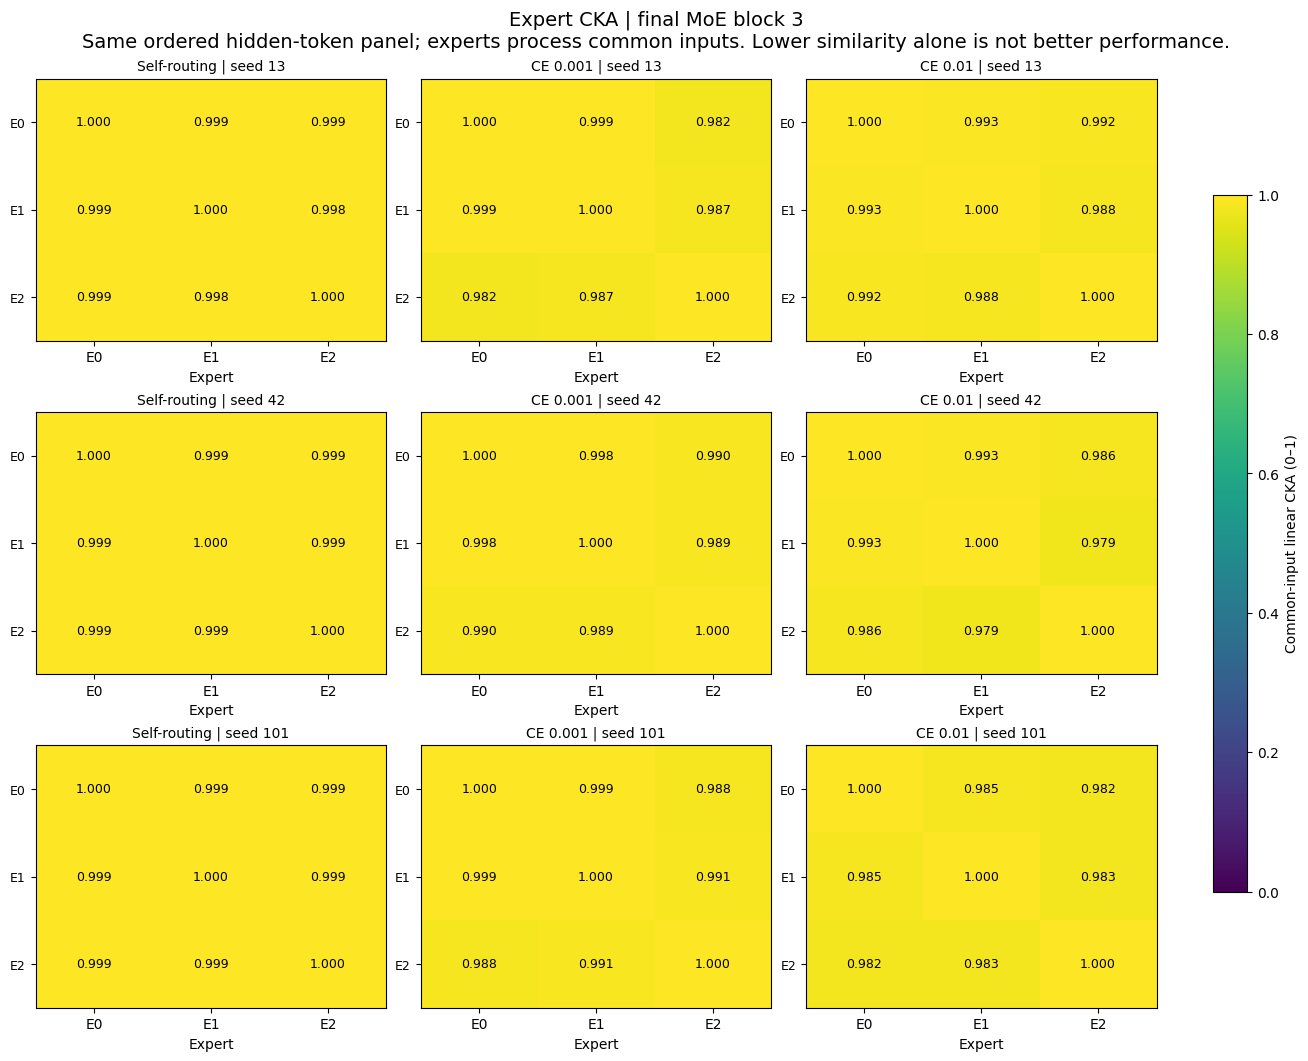

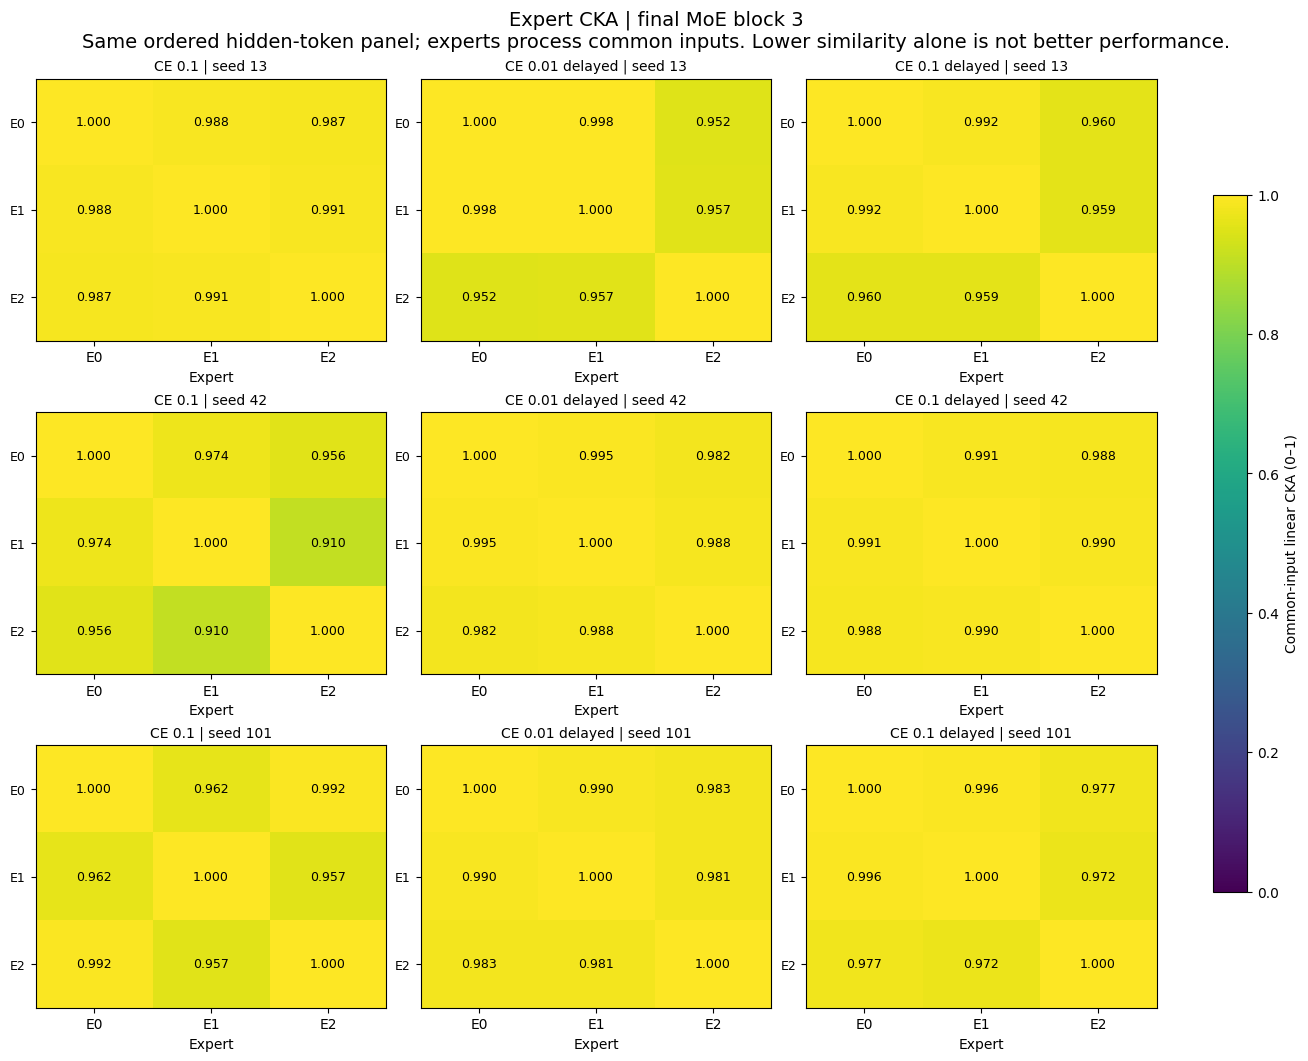

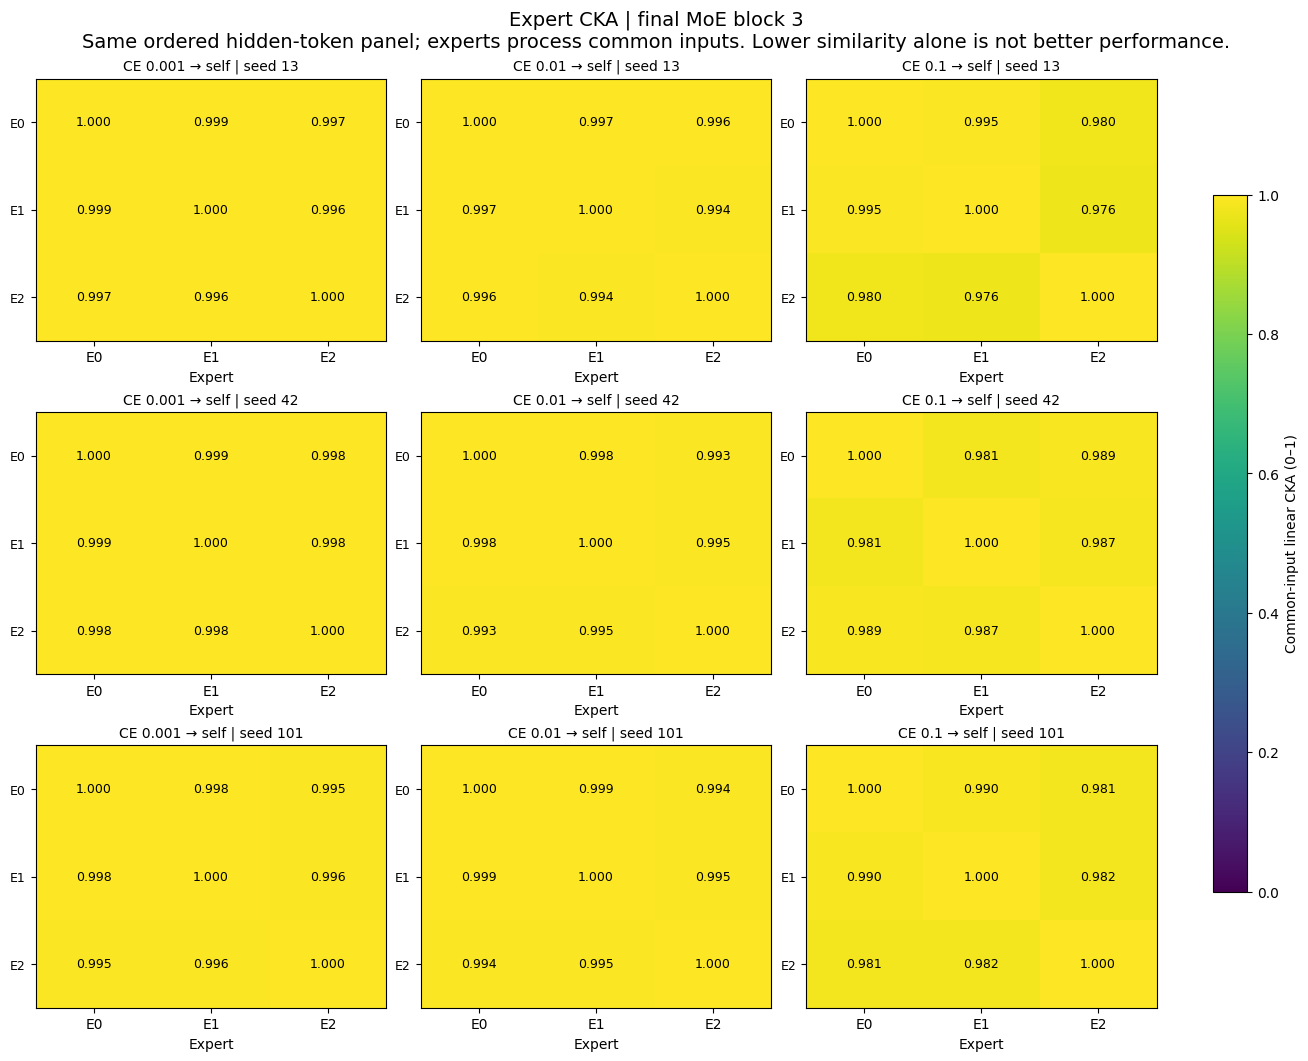

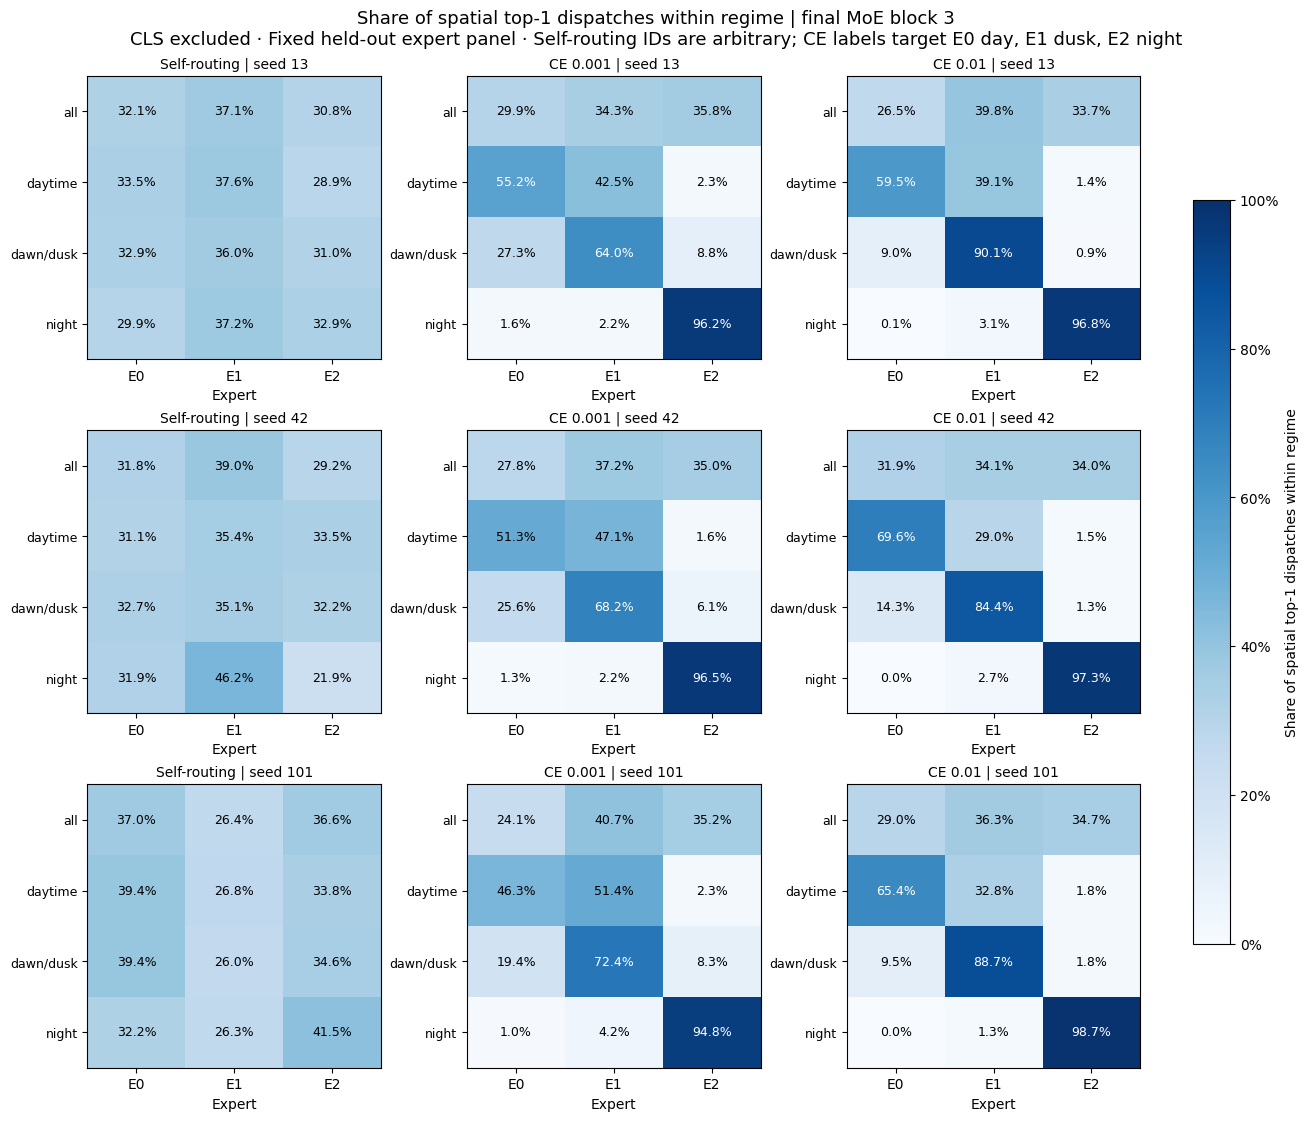

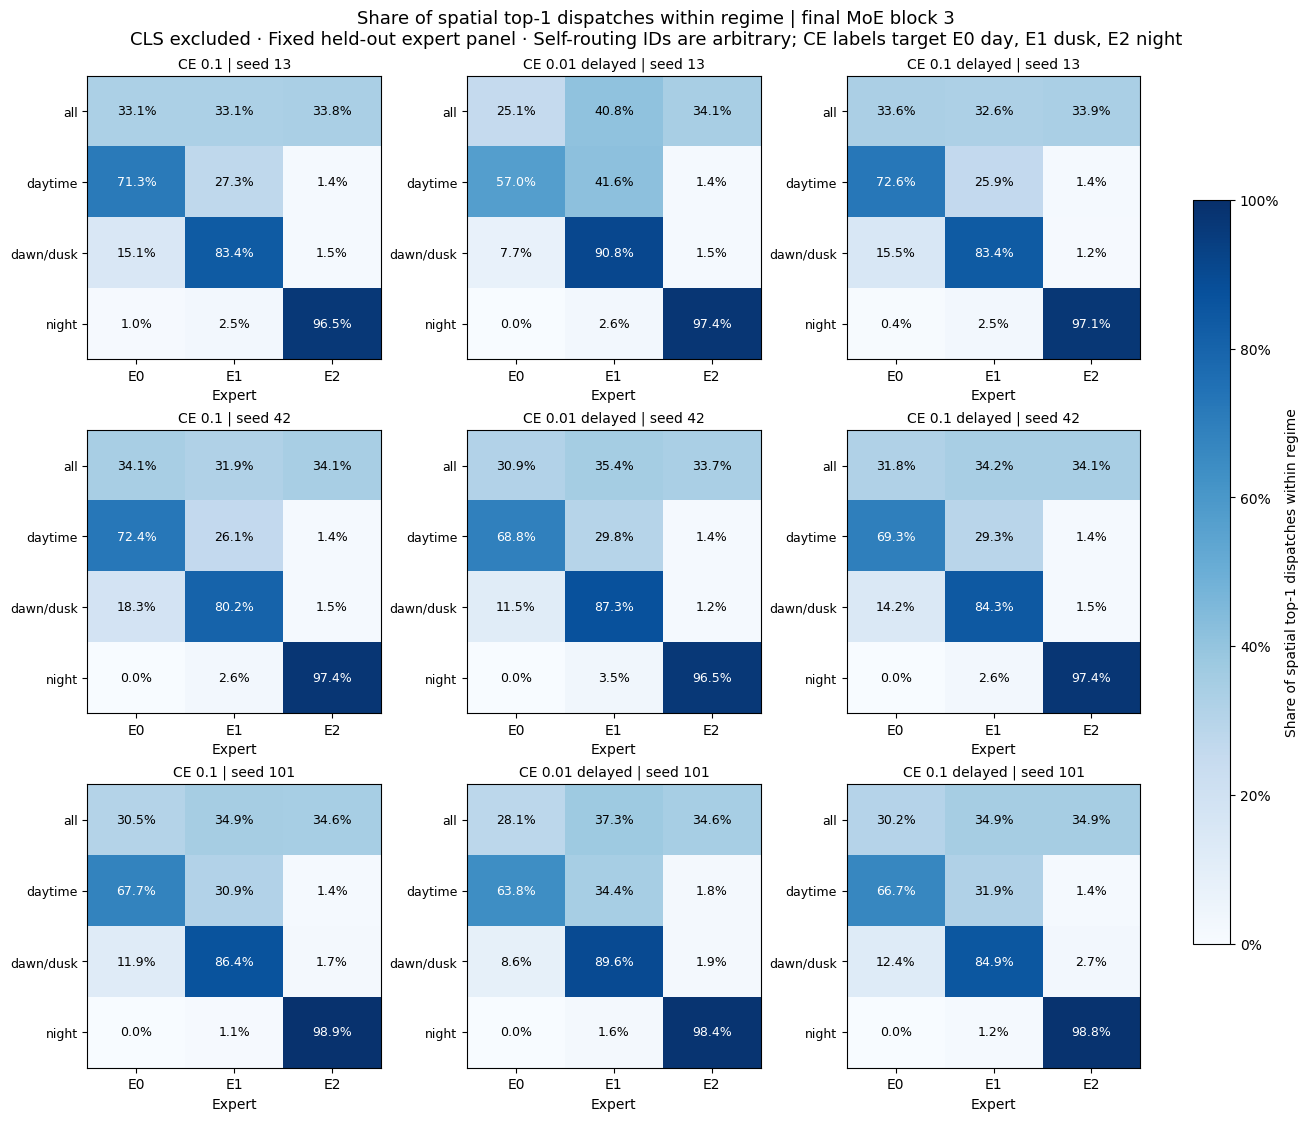

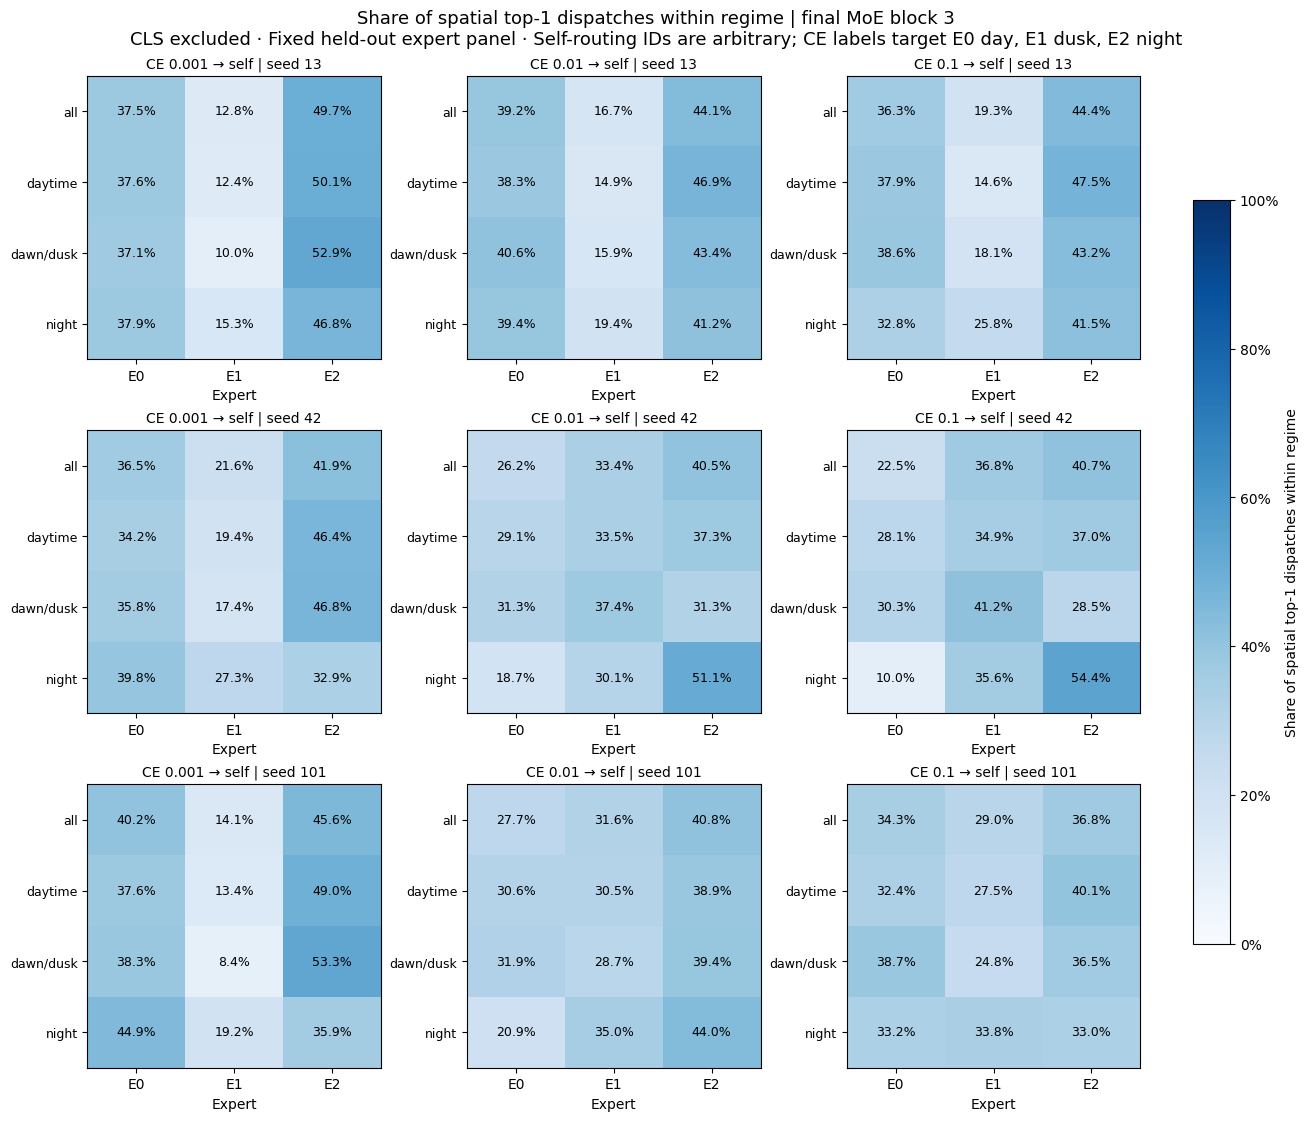

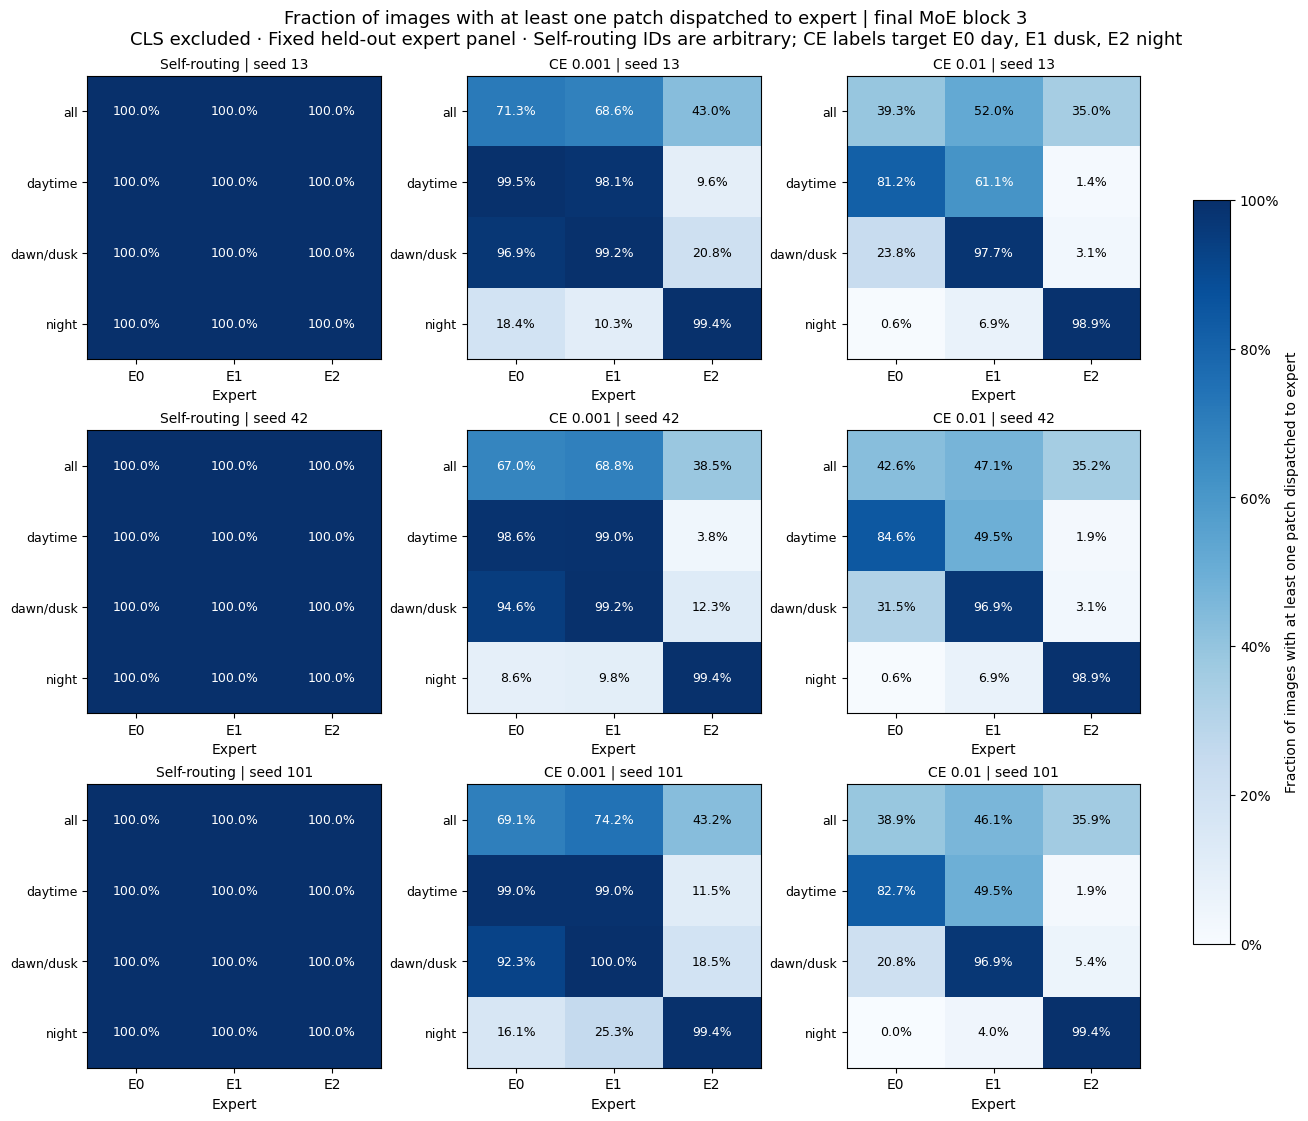

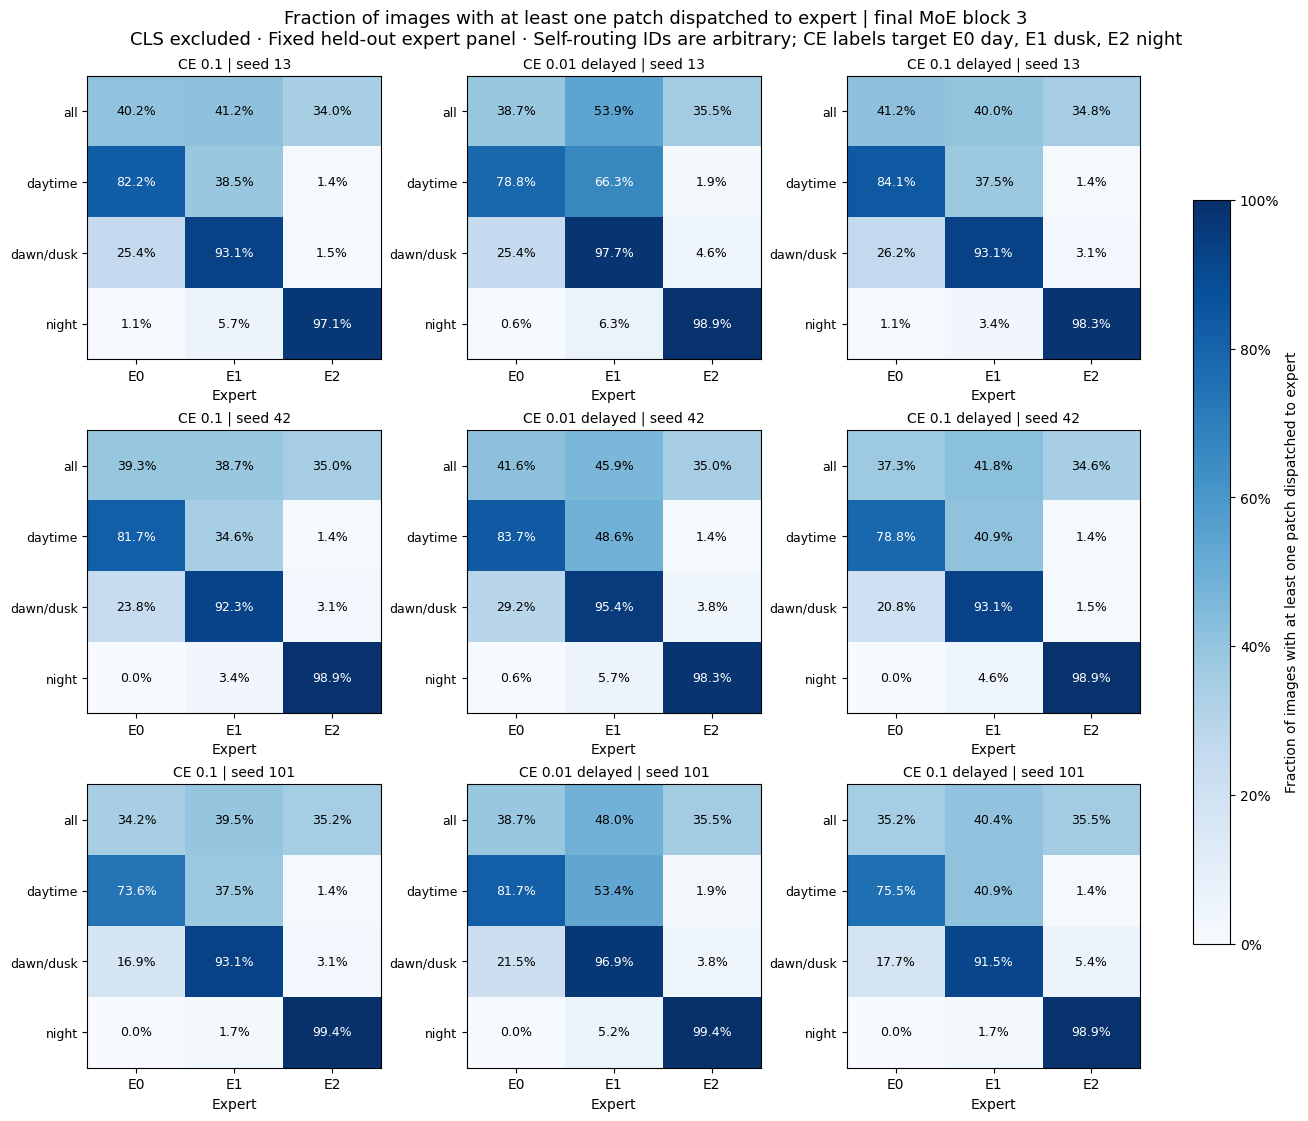

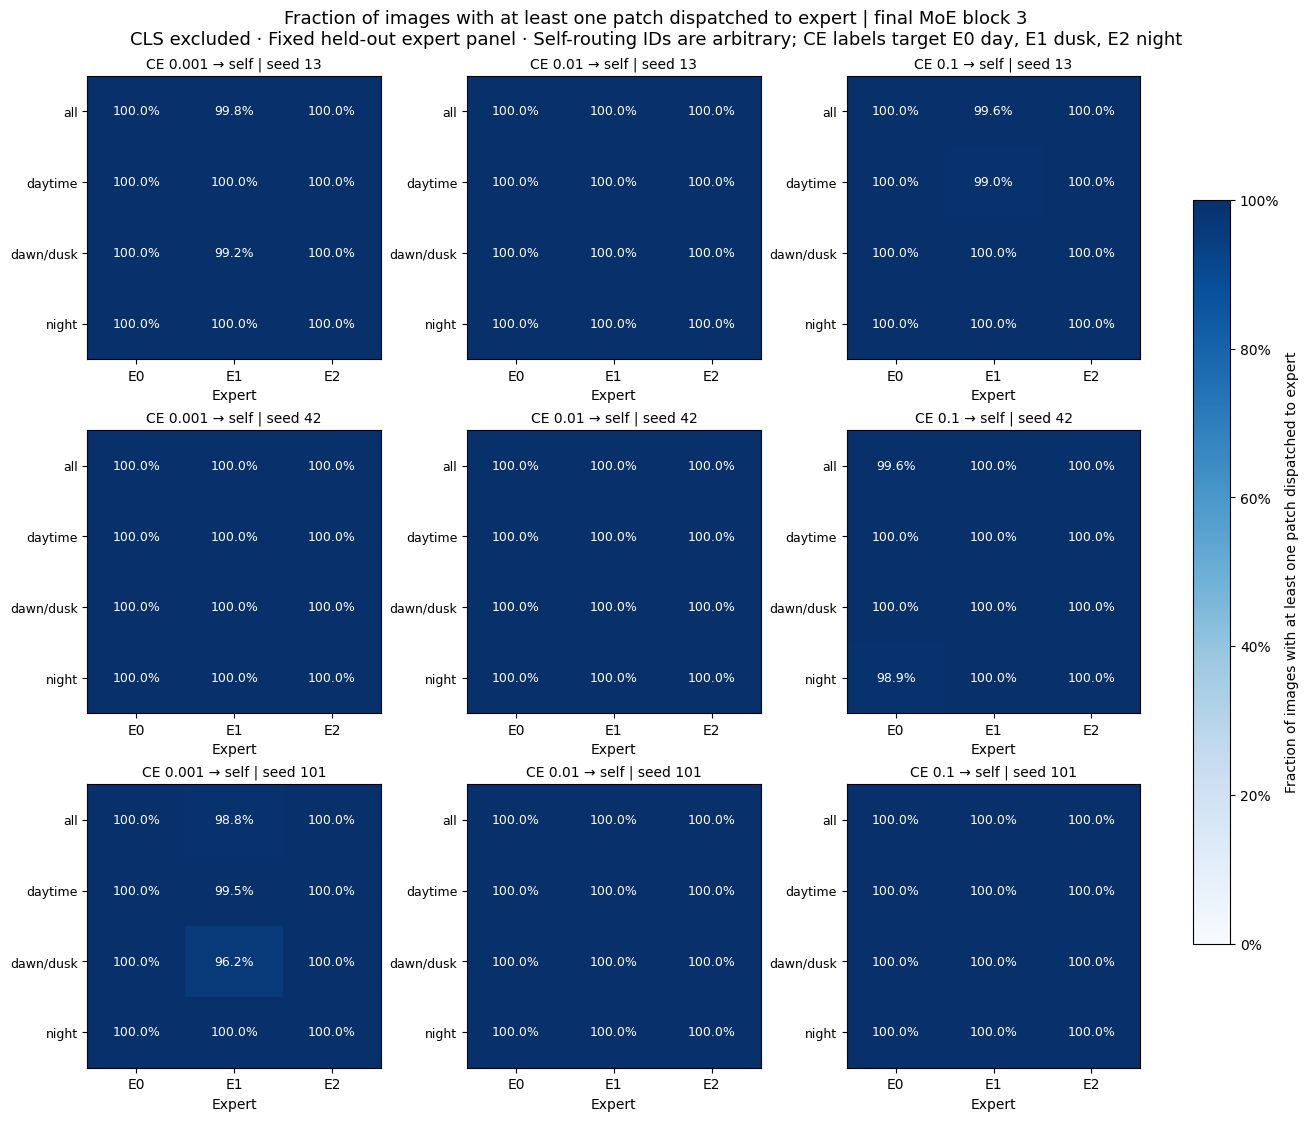

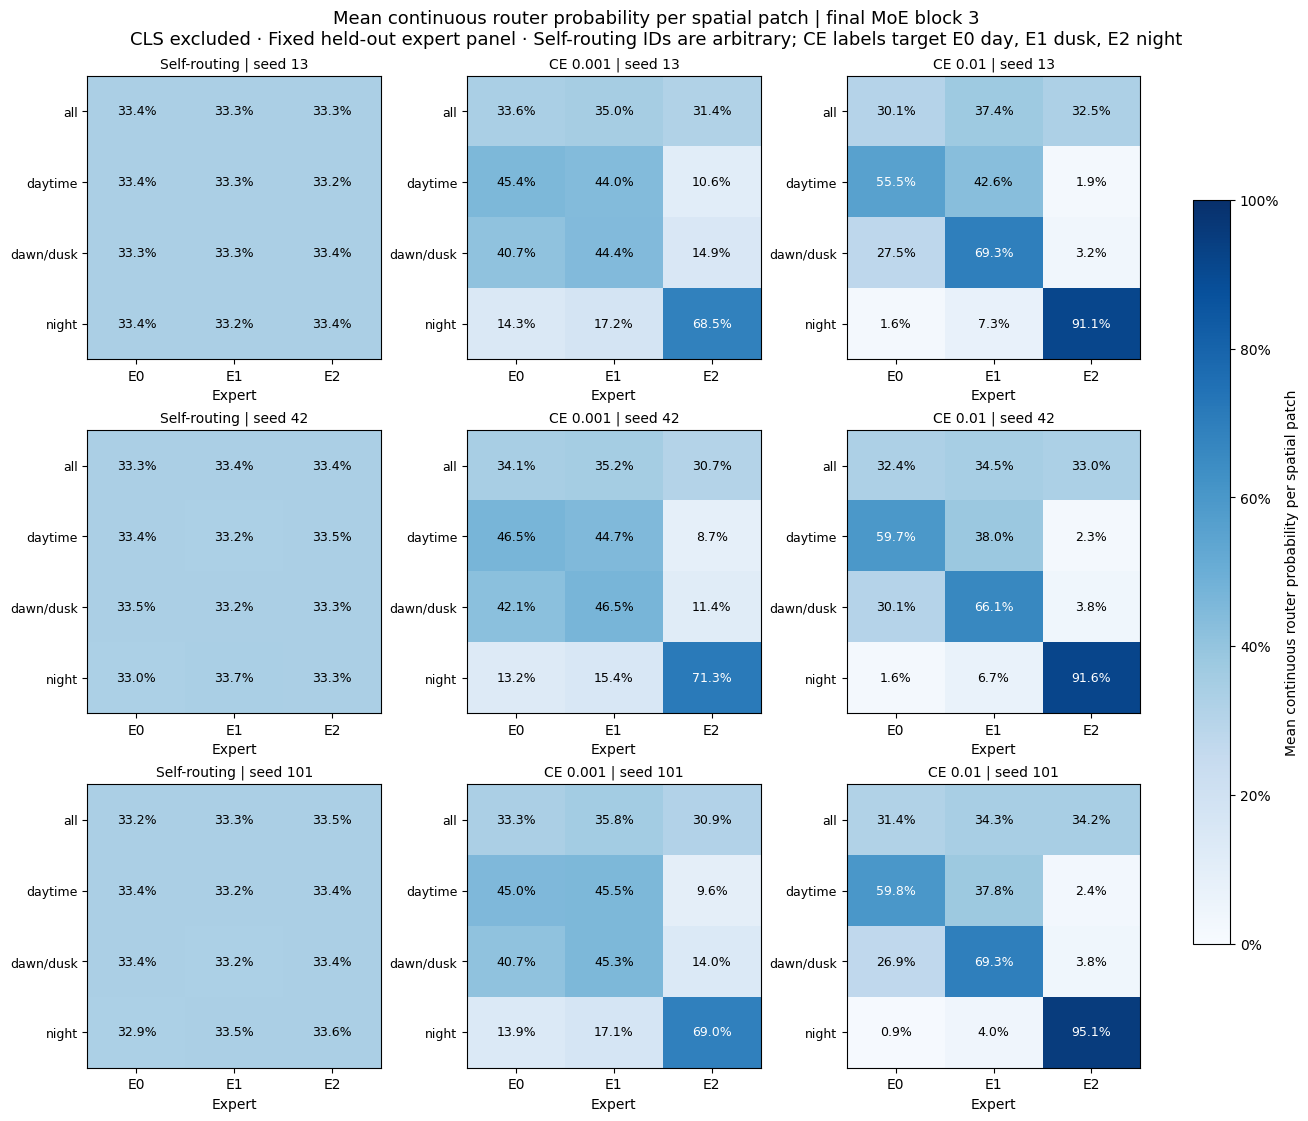

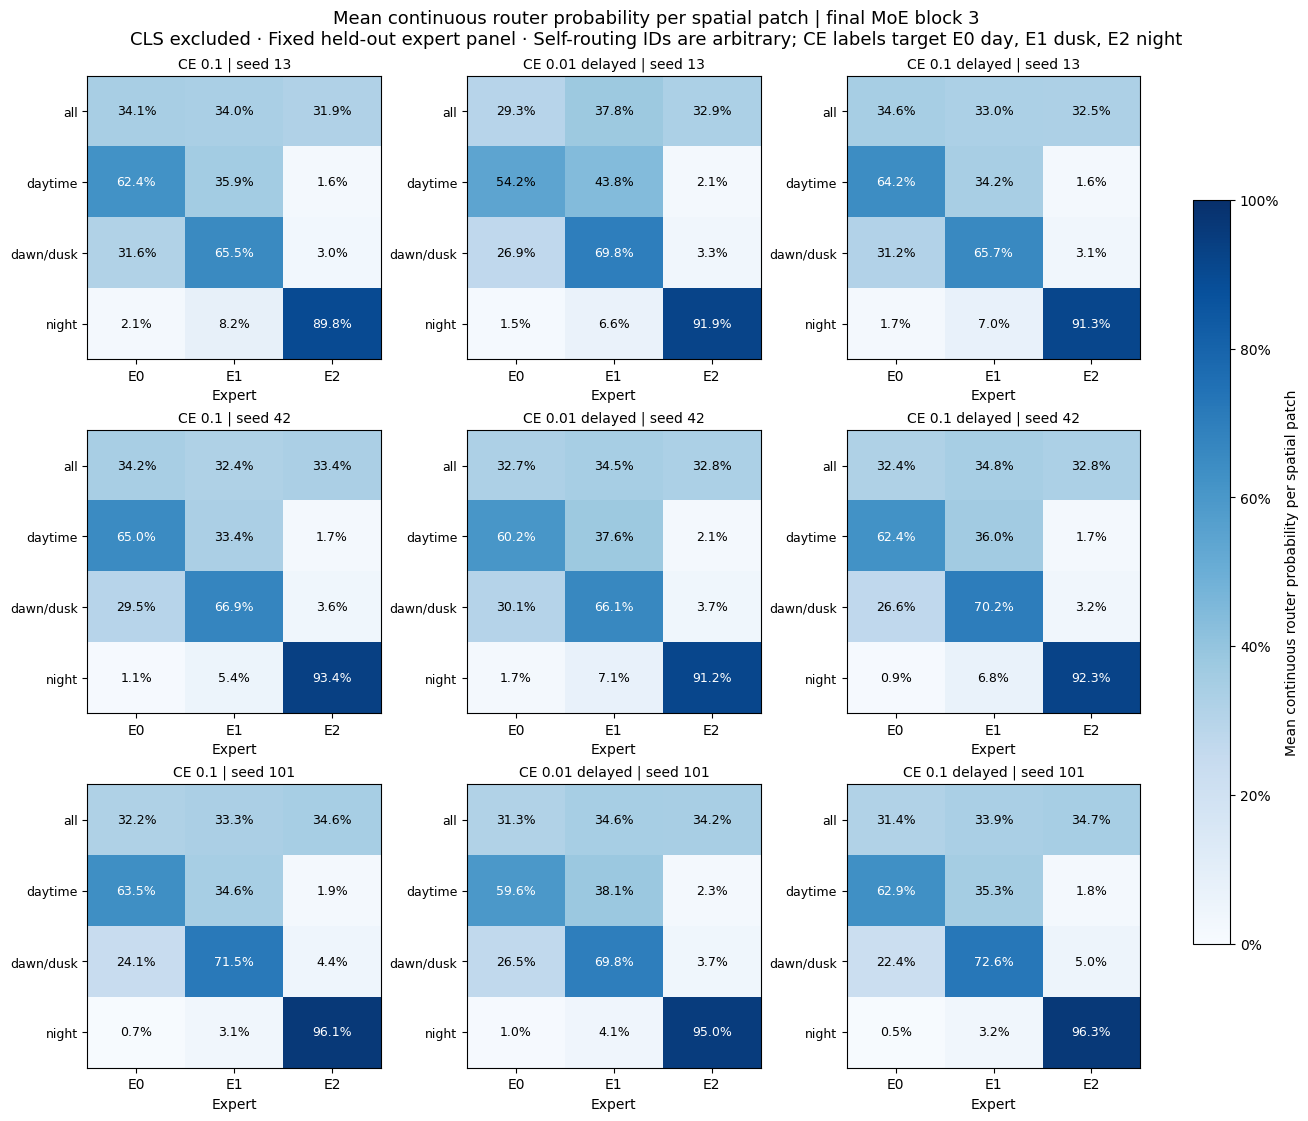

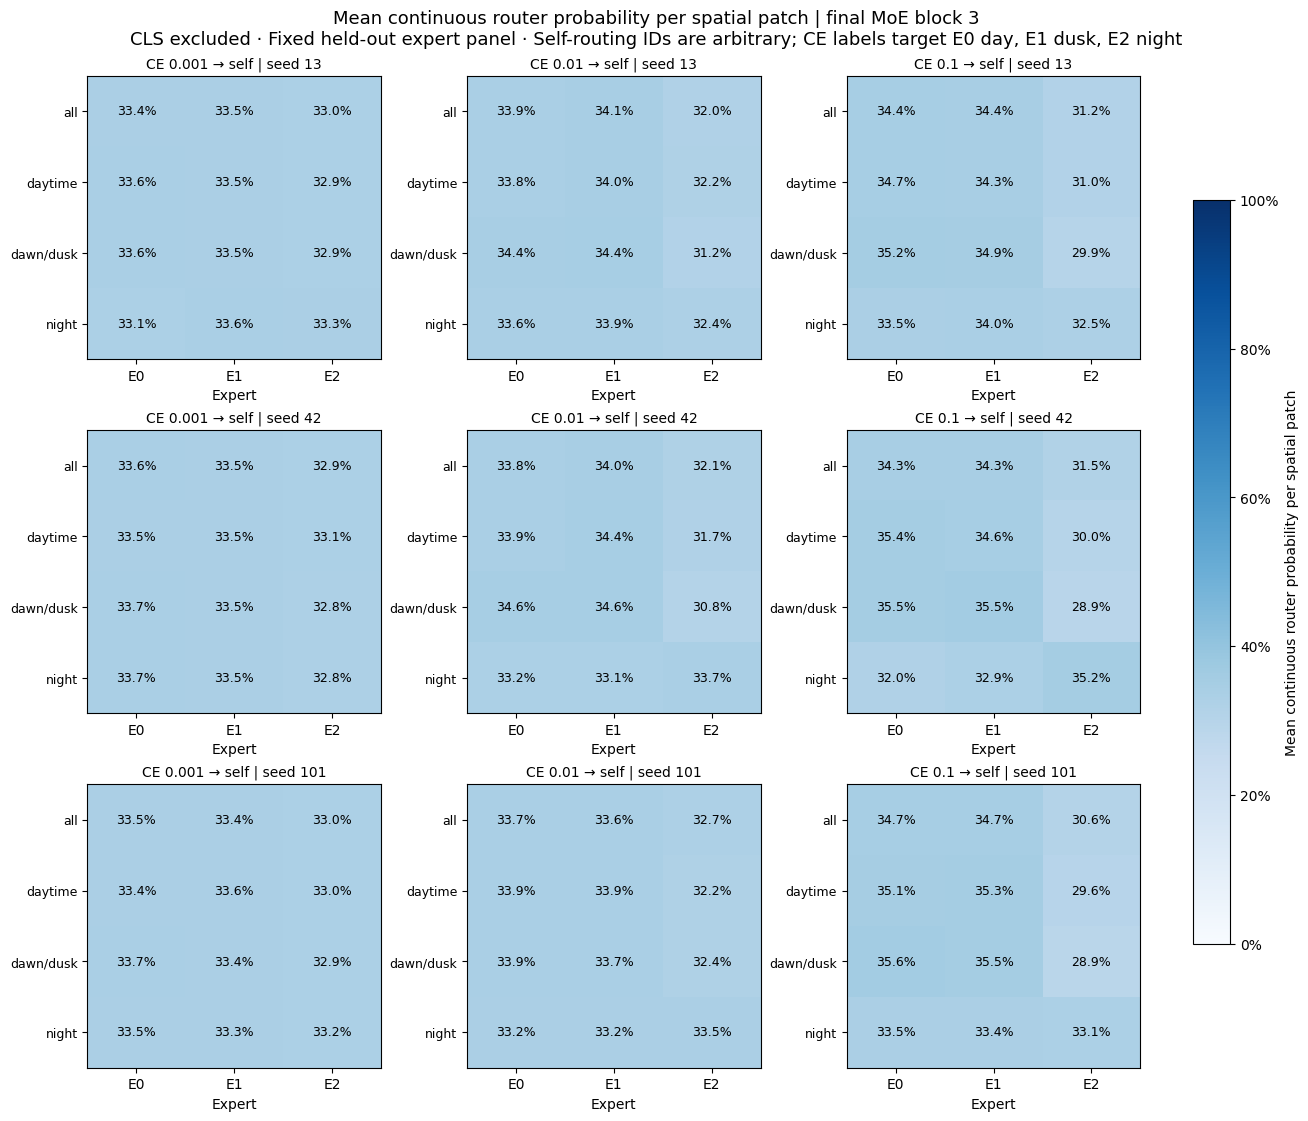

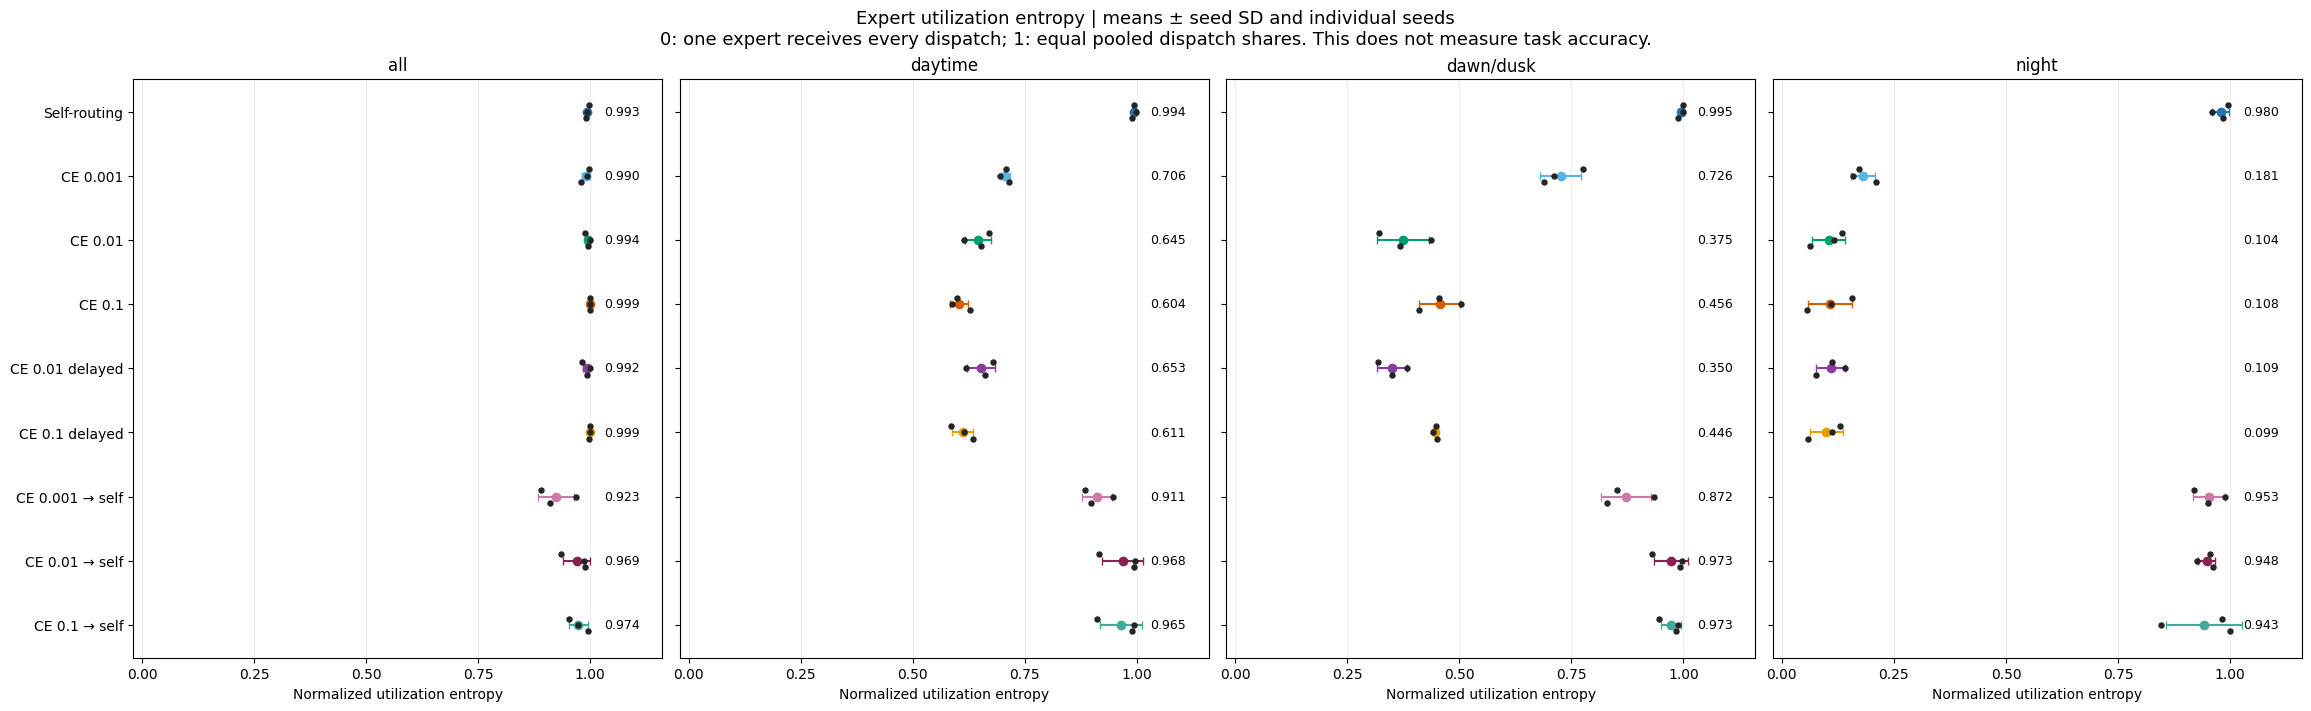

In [3]:
evaluation_cka = pd.read_csv(evaluation_run_dir / "expert_cka.csv")
evaluation_activation = pd.read_csv(evaluation_run_dir / "expert_activation_frequency.csv")
evaluation_entropy = pd.read_csv(evaluation_run_dir / "expert_utilization_entropy.csv")
evaluation_experts = list(range(evaluation_config["num_experts"]))
evaluation_block = max(evaluation_config["moe_blocks"])


def expert_matrix(ax: Axes, matrix: pd.DataFrame, title: str, rows: list[str], *, percent: bool = True) -> AxesImage:
    """Use one 0–1 scale for all expert matrices; missing cells remain missing."""
    values = matrix.to_numpy(dtype=float)
    image = ax.imshow(
        np.ma.masked_invalid(values), vmin=0, vmax=1, cmap="Blues" if percent else "viridis", aspect="auto"
    )
    ax.set_xticks(range(len(evaluation_experts)), [f"E{e}" for e in evaluation_experts])
    ax.set_yticks(range(len(rows)), rows, fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Expert")
    for i, j in np.ndindex(values.shape):
        value = values[i, j]
        label = (f"{value:.1%}" if percent else f"{value:.3f}") if np.isfinite(value) else "n/a"
        ax.text(
            j,
            i,
            label,
            ha="center",
            va="center",
            fontsize=9,
            color=("white" if value > 0.55 else "black") if percent else ("black" if value > 0.65 else "white"),
        )
    return image


evaluation_arm_pages = [evaluation_moes[i : i + 3] for i in range(0, len(evaluation_moes), 3)]
for page_index, page_arms in enumerate(evaluation_arm_pages):
    fig, axes = eval_plt.subplots(
        len(evaluation_seeds),
        len(page_arms),
        figsize=(13, 3.5 * len(evaluation_seeds)),
        squeeze=False,
        constrained_layout=True,
    )
    for row, seed in enumerate(evaluation_seeds):
        for col, arm in enumerate(page_arms):
            part = evaluation_cka.loc[
                evaluation_cka["kind"].eq("within_arm")
                & evaluation_cka["arm"].eq(arm)
                & evaluation_cka["seed"].eq(seed)
            ]
            matrix = part.pivot(index="expert_i", columns="expert_j", values="cka").reindex(
                index=evaluation_experts, columns=evaluation_experts
            )
            image = expert_matrix(
                axes[row, col],
                matrix,
                f"{evaluation_labels[arm]} | seed {seed}",
                [f"E{e}" for e in evaluation_experts],
                percent=False,
            )
    fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.75, label="Common-input linear CKA (0–1)")
    fig.suptitle(
        f"Expert CKA | final MoE block {evaluation_block}\n"
        "Same ordered hidden-token panel; experts process common inputs. "
        "Lower similarity alone is not better performance.",
        fontsize=14,
    )
    evaluation_save(fig, "expert_cka" if page_index == 0 else f"expert_cka_page_{page_index + 1}")

for metric, stem, title in [
    ("token_activation_frequency", "expert_distribution_by_regime", "Share of spatial top-1 dispatches within regime"),
    (
        "image_activation_frequency",
        "expert_image_activation_frequency",
        "Fraction of images with at least one patch dispatched to expert",
    ),
    ("mean_probability", "expert_probability_by_regime", "Mean continuous router probability per spatial patch"),
]:
    for page_index, page_arms in enumerate(evaluation_arm_pages):
        fig, axes = eval_plt.subplots(
            len(evaluation_seeds),
            len(page_arms),
            figsize=(13, 3.7 * len(evaluation_seeds)),
            squeeze=False,
            constrained_layout=True,
        )
        for row, seed in enumerate(evaluation_seeds):
            for col, arm in enumerate(page_arms):
                part = evaluation_activation.loc[
                    evaluation_activation["arm"].eq(arm) & evaluation_activation["seed"].eq(seed)
                ]
                matrix = part.pivot(index="regime", columns="expert", values=metric).reindex(
                    index=evaluation_regimes, columns=evaluation_experts
                )
                present = matrix.notna().all(axis=1)
                if metric in {"token_activation_frequency", "mean_probability"} and not np.allclose(
                    matrix.loc[present].sum(axis=1), 1, atol=1e-6
                ):
                    raise ValueError("Expert dispatch/probability rows must sum to one.")
                image = expert_matrix(
                    axes[row, col], matrix, f"{evaluation_labels[arm]} | seed {seed}", evaluation_regimes
                )
        fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.75, format="{x:.0%}", label=title)
        fig.suptitle(
            f"{title} | final MoE block {evaluation_block}\n"
            "CLS excluded · Fixed held-out expert panel · Self-routing IDs are arbitrary; "
            "CE labels target E0 day, E1 dusk, E2 night",
            fontsize=13,
        )
        evaluation_save(fig, stem if page_index == 0 else f"{stem}_page_{page_index + 1}")

fig, axes = eval_plt.subplots(1, 4, figsize=(23, 7), sharey=True, constrained_layout=True)
for ax, regime in zip(axes, evaluation_regimes, strict=True):
    for i, arm in enumerate(evaluation_moes):
        values = evaluation_entropy.loc[
            evaluation_entropy["arm"].eq(arm) & evaluation_entropy["regime"].eq(regime), "entropy_normalized"
        ].to_numpy()
        if not len(values):
            ax.text(1.03, i, "n/a", va="center", fontsize=9)
            continue
        spread = values.std(ddof=1) if len(values) > 1 else 0
        ax.errorbar(
            values.mean(), i, xerr=spread if len(values) > 1 else None, fmt="o", color=evaluation_colors[arm], capsize=3
        )
        ax.scatter(values, i + np.linspace(-0.10, 0.10, len(values)), c="#252525", s=13, zorder=4)
        ax.text(1.03, i, f"{values.mean():.3f}", va="center", fontsize=9)
    ax.set(title=regime, xlabel="Normalized utilization entropy", xlim=(-0.02, 1.16))
    ax.set_yticks(range(len(evaluation_moes)), [evaluation_labels[a] for a in evaluation_moes])
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
fig.suptitle(
    "Expert utilization entropy | means ± seed SD and individual seeds\n"
    "0: one expert receives every dispatch; 1: equal pooled dispatch shares. "
    "This does not measure task accuracy.",
    fontsize=13,
)
evaluation_save(fig, "expert_utilization_entropy")

### Detailed expert distribution by regime, weather and scene

This frozen evaluation loads the saved final checkpoints for all nine MoE arms and all seeds.
Weather and scene names come from the actual BDD validation annotations. Every arm processes
the same full query panel with unmasked spatial routing in evaluation mode. No training or
optimizer updates occur. Per-image token counts and probability mass are cached with checkpoint,
annotation, protocol and image fingerprints, then reused when redrawing plots.

The heatmaps show time of day × weather, time of day × scene, and their observed joint conditions.
Each row states the number of images. Gray cells have fewer than five images or no observations;
they are not zeros. The detailed figures default to the first seed, matching the previous notebook.
Change `condition_plot_seeds` to `evaluation_seeds` to show all seeds, or switch `condition_metric`
to `mean_probability` for continuous router preferences. All-seed CSV summaries are always saved.


In [ ]:
import hashlib as condition_hashlib

import torch as condition_torch
from PIL import Image as ConditionImage
from torchvision.transforms import functional as condition_TF

from cafl4ds.models.vit import MoEViTEncoder as ConditionEncoder
from cafl4ds.ssl.factory import build_mae as condition_build_mae

# Frozen inference only. All seeds are cached; detailed plots default to seed 13.
condition_plot_seeds = [evaluation_seeds[0]]  # Set to evaluation_seeds to display every seed.
condition_min_images = 5
condition_metric = "dispatch_share"  # Or "mean_probability" for continuous routing preferences.
condition_labels_path = None
condition_panel = pd.read_csv(evaluation_run_dir / "query.csv")
condition_protocol = json.loads((evaluation_run_dir / "protocol.json").read_text())
if condition_panel["clip_id"].duplicated().any():
    raise ValueError("Condition evaluation requires unique query clip IDs.")
for split in ["train", "support"]:
    if set(condition_panel["clip_id"]) & set(pd.read_csv(evaluation_run_dir / f"{split}.csv")["clip_id"]):
        raise ValueError("Condition panel overlaps training/support clips.")
if condition_labels_path is None and "weather" in condition_panel.columns:
    condition_labels = {
        row.clip_id: {"timeofday": row.regime, "scene": row.scene, "weather": row.weather}
        for row in condition_panel.itertuples()
    }
else:
    if condition_labels_path is None:
        condition_labels_path = next(
            (
                p / "labels/bdd100k_labels_images_val.json"
                for p in Path(condition_panel["path"].iloc[0]).parents
                if (p / "labels/bdd100k_labels_images_val.json").exists()
            ),
            None,
        )
    if condition_labels_path is None:
        raise FileNotFoundError("Set condition_labels_path to BDD validation image annotations.")
    condition_labels_path = Path(condition_labels_path)
    condition_labels = {Path(r["name"]).stem: r["attributes"] for r in json.loads(condition_labels_path.read_text())}
condition_weather = []
for row in condition_panel.itertuples():
    attrs = condition_labels[row.clip_id]
    if (attrs["timeofday"], attrs["scene"]) != (row.regime, row.scene):
        raise ValueError("BDD annotations disagree with the saved query manifest.")
    condition_weather.append(attrs.get("weather", "(missing)"))
condition_panel["weather"] = condition_weather
condition_checkpoint_paths = {
    (s, a): evaluation_run_dir / f"seed_{s}/{a}/checkpoint_last.pt" for s in evaluation_seeds for a in evaluation_moes
}
condition_contract = {
    "version": 1,
    "protocol_hash": condition_protocol["protocol_hash"],
    "labels_sha256": condition_hashlib.sha256(json.dumps(condition_labels, sort_keys=True).encode()).hexdigest(),
    "panel": [
        {"clip_id": r.clip_id, "size": Path(r.path).stat().st_size, "mtime_ns": Path(r.path).stat().st_mtime_ns}
        for r in condition_panel.itertuples()
    ],
    "checkpoints": {
        f"{s}/{a}": condition_hashlib.sha256(p.read_bytes()).hexdigest()
        for (s, a), p in condition_checkpoint_paths.items()
    },
    "preprocess": "TF.to_tensor RGB uint8; TF.resize square antialias=True; eval spatial routing excluding CLS",
}
condition_key = condition_hashlib.sha256(json.dumps(condition_contract, sort_keys=True).encode()).hexdigest()[:12]
condition_output = evaluation_output / "conditions" / condition_key
condition_output.mkdir(parents=True, exist_ok=True)
condition_cache = condition_output / "per_image_expert_routing.csv"
condition_manifest = condition_output / "manifest.json"
if condition_manifest.exists():
    cached = json.loads(condition_manifest.read_text())
    if (
        cached["contract"] != condition_contract
        or condition_hashlib.sha256(condition_cache.read_bytes()).hexdigest() != cached["routing_sha256"]
    ):
        raise ValueError("Frozen routing cache does not match its inputs/checksum.")
    condition_routing = pd.read_csv(condition_cache)
    print("Reusing frozen condition routing cache.")
else:
    condition_device = condition_torch.device("cuda" if condition_torch.cuda.is_available() else "cpu")
    condition_images = []
    for row in condition_panel.itertuples():
        with ConditionImage.open(row.path) as img:
            tensor = condition_TF.to_tensor(np.array(img.convert("RGB")))
            condition_images.append(condition_TF.resize(tensor, [evaluation_config["img_size"]] * 2, antialias=True))
    condition_images = condition_torch.stack(condition_images)
    condition_rows = []
    previous_threads = condition_torch.get_num_threads()
    condition_torch.set_num_threads(4)
    try:
        with condition_torch.no_grad():
            for seed in evaluation_seeds:
                for arm in evaluation_moes:
                    encoder = ConditionEncoder(
                        **{
                            k: evaluation_config[k]
                            for k in [
                                "img_size",
                                "patch_size",
                                "embed_dim",
                                "depth",
                                "num_heads",
                                "num_experts",
                                "top_k",
                                "router_noise_std",
                            ]
                        },
                        mlp_ratio=2.0,
                        moe_blocks=tuple(evaluation_config["moe_blocks"]),
                        routing_level="token",
                    )
                    model = condition_build_mae(
                        encoder,
                        mask_ratio=evaluation_config["mask_ratio"],
                        decoder_dim=64,
                        decoder_depth=2,
                        decoder_heads=4,
                        norm_pix_loss=False,
                        aux_weight=evaluation_config["balance_weight"],
                    )
                    checkpoint = condition_torch.load(
                        condition_checkpoint_paths[seed, arm], map_location="cpu", weights_only=True
                    )
                    expected_protocol_hash = condition_protocol["protocol_hash"]
                    reuse_path = evaluation_run_dir / "reused_controls.json"
                    if reuse_path.exists():
                        provenance = json.loads(reuse_path.read_text())
                        if arm in provenance["arms"]:
                            if (
                                condition_contract["checkpoints"][f"{seed}/{arm}"]
                                != provenance["checkpoint_sha256"][f"{seed}/{arm}"]
                            ):
                                raise ValueError("A reused checkpoint differs from its recorded source.")
                            expected_protocol_hash = provenance["source_protocol_hash"]
                    if (
                        checkpoint["protocol_hash"] != expected_protocol_hash
                        or checkpoint["seed"] != seed
                        or checkpoint["arm"]["name"] != arm
                        or checkpoint["global_step"] != evaluation_config["total_updates"]
                    ):
                        raise ValueError("Checkpoint is not the expected final paired model.")
                    model.load_state_dict(checkpoint["method"], strict=True)
                    model.to(condition_device).eval()
                    for start in range(0, len(condition_panel), 64):
                        batch = condition_images[start : start + 64].to(condition_device)
                        probs = model.encoder.routing(batch)[evaluation_block][:, 1:, :]
                        selected = (
                            condition_torch.nn.functional.one_hot(probs.argmax(-1), len(evaluation_experts))
                            .sum(1)
                            .cpu()
                            .numpy()
                        )
                        masses = probs.sum(1).cpu().numpy()
                        for i, record in enumerate(condition_panel.iloc[start : start + len(batch)].to_dict("records")):
                            for expert in evaluation_experts:
                                condition_rows.append(
                                    {
                                        **{k: record[k] for k in ["clip_id", "regime", "weather", "scene"]},
                                        "seed": seed,
                                        "arm": arm,
                                        "block": evaluation_block,
                                        "expert": expert,
                                        "spatial_tokens": probs.shape[1],
                                        "selected_tokens": int(selected[i, expert]),
                                        "probability_mass": float(masses[i, expert]),
                                    }
                                )
                    model.cpu()
                    del model, checkpoint
                    print(f"Frozen routing: {arm}, seed {seed}, {len(condition_panel)} held-out images", flush=True)
    finally:
        condition_torch.set_num_threads(previous_threads)
    condition_routing = pd.DataFrame(condition_rows)
    condition_routing.to_csv(condition_cache, index=False)
    condition_panel.to_csv(condition_output / "panel_metadata.csv", index=False)
    condition_manifest.write_text(
        json.dumps(
            {
                "contract": condition_contract,
                "routing_sha256": condition_hashlib.sha256(condition_cache.read_bytes()).hexdigest(),
                "device": str(condition_device),
            },
            indent=2,
        )
        + "\n"
    )
if condition_routing.duplicated(["seed", "arm", "clip_id", "expert"]).any():
    raise ValueError("Duplicated per-image routing observations.")
condition_totals = condition_routing.groupby(["seed", "arm", "clip_id"]).agg(
    selected=("selected_tokens", "sum"), tokens=("spatial_tokens", "first"), probability=("probability_mass", "sum")
)
if not (condition_totals["selected"] == condition_totals["tokens"]).all() or not np.allclose(
    condition_totals["probability"], condition_totals["tokens"], atol=1e-4
):
    raise ValueError("Routing does not conserve spatial tokens/probability mass.")
expected = pd.MultiIndex.from_product(
    [evaluation_seeds, evaluation_moes, condition_panel["clip_id"]], names=["seed", "arm", "clip_id"]
)
if len(condition_totals) != len(expected) or not expected.isin(condition_totals.index).all():
    raise ValueError("The frozen cache must cover all seeds, arms and query images.")
print(
    f"Condition routing covers all {len(condition_panel)} query images and "
    f"{len(evaluation_moes)} MoE arms × {len(evaluation_seeds)} seeds."
)

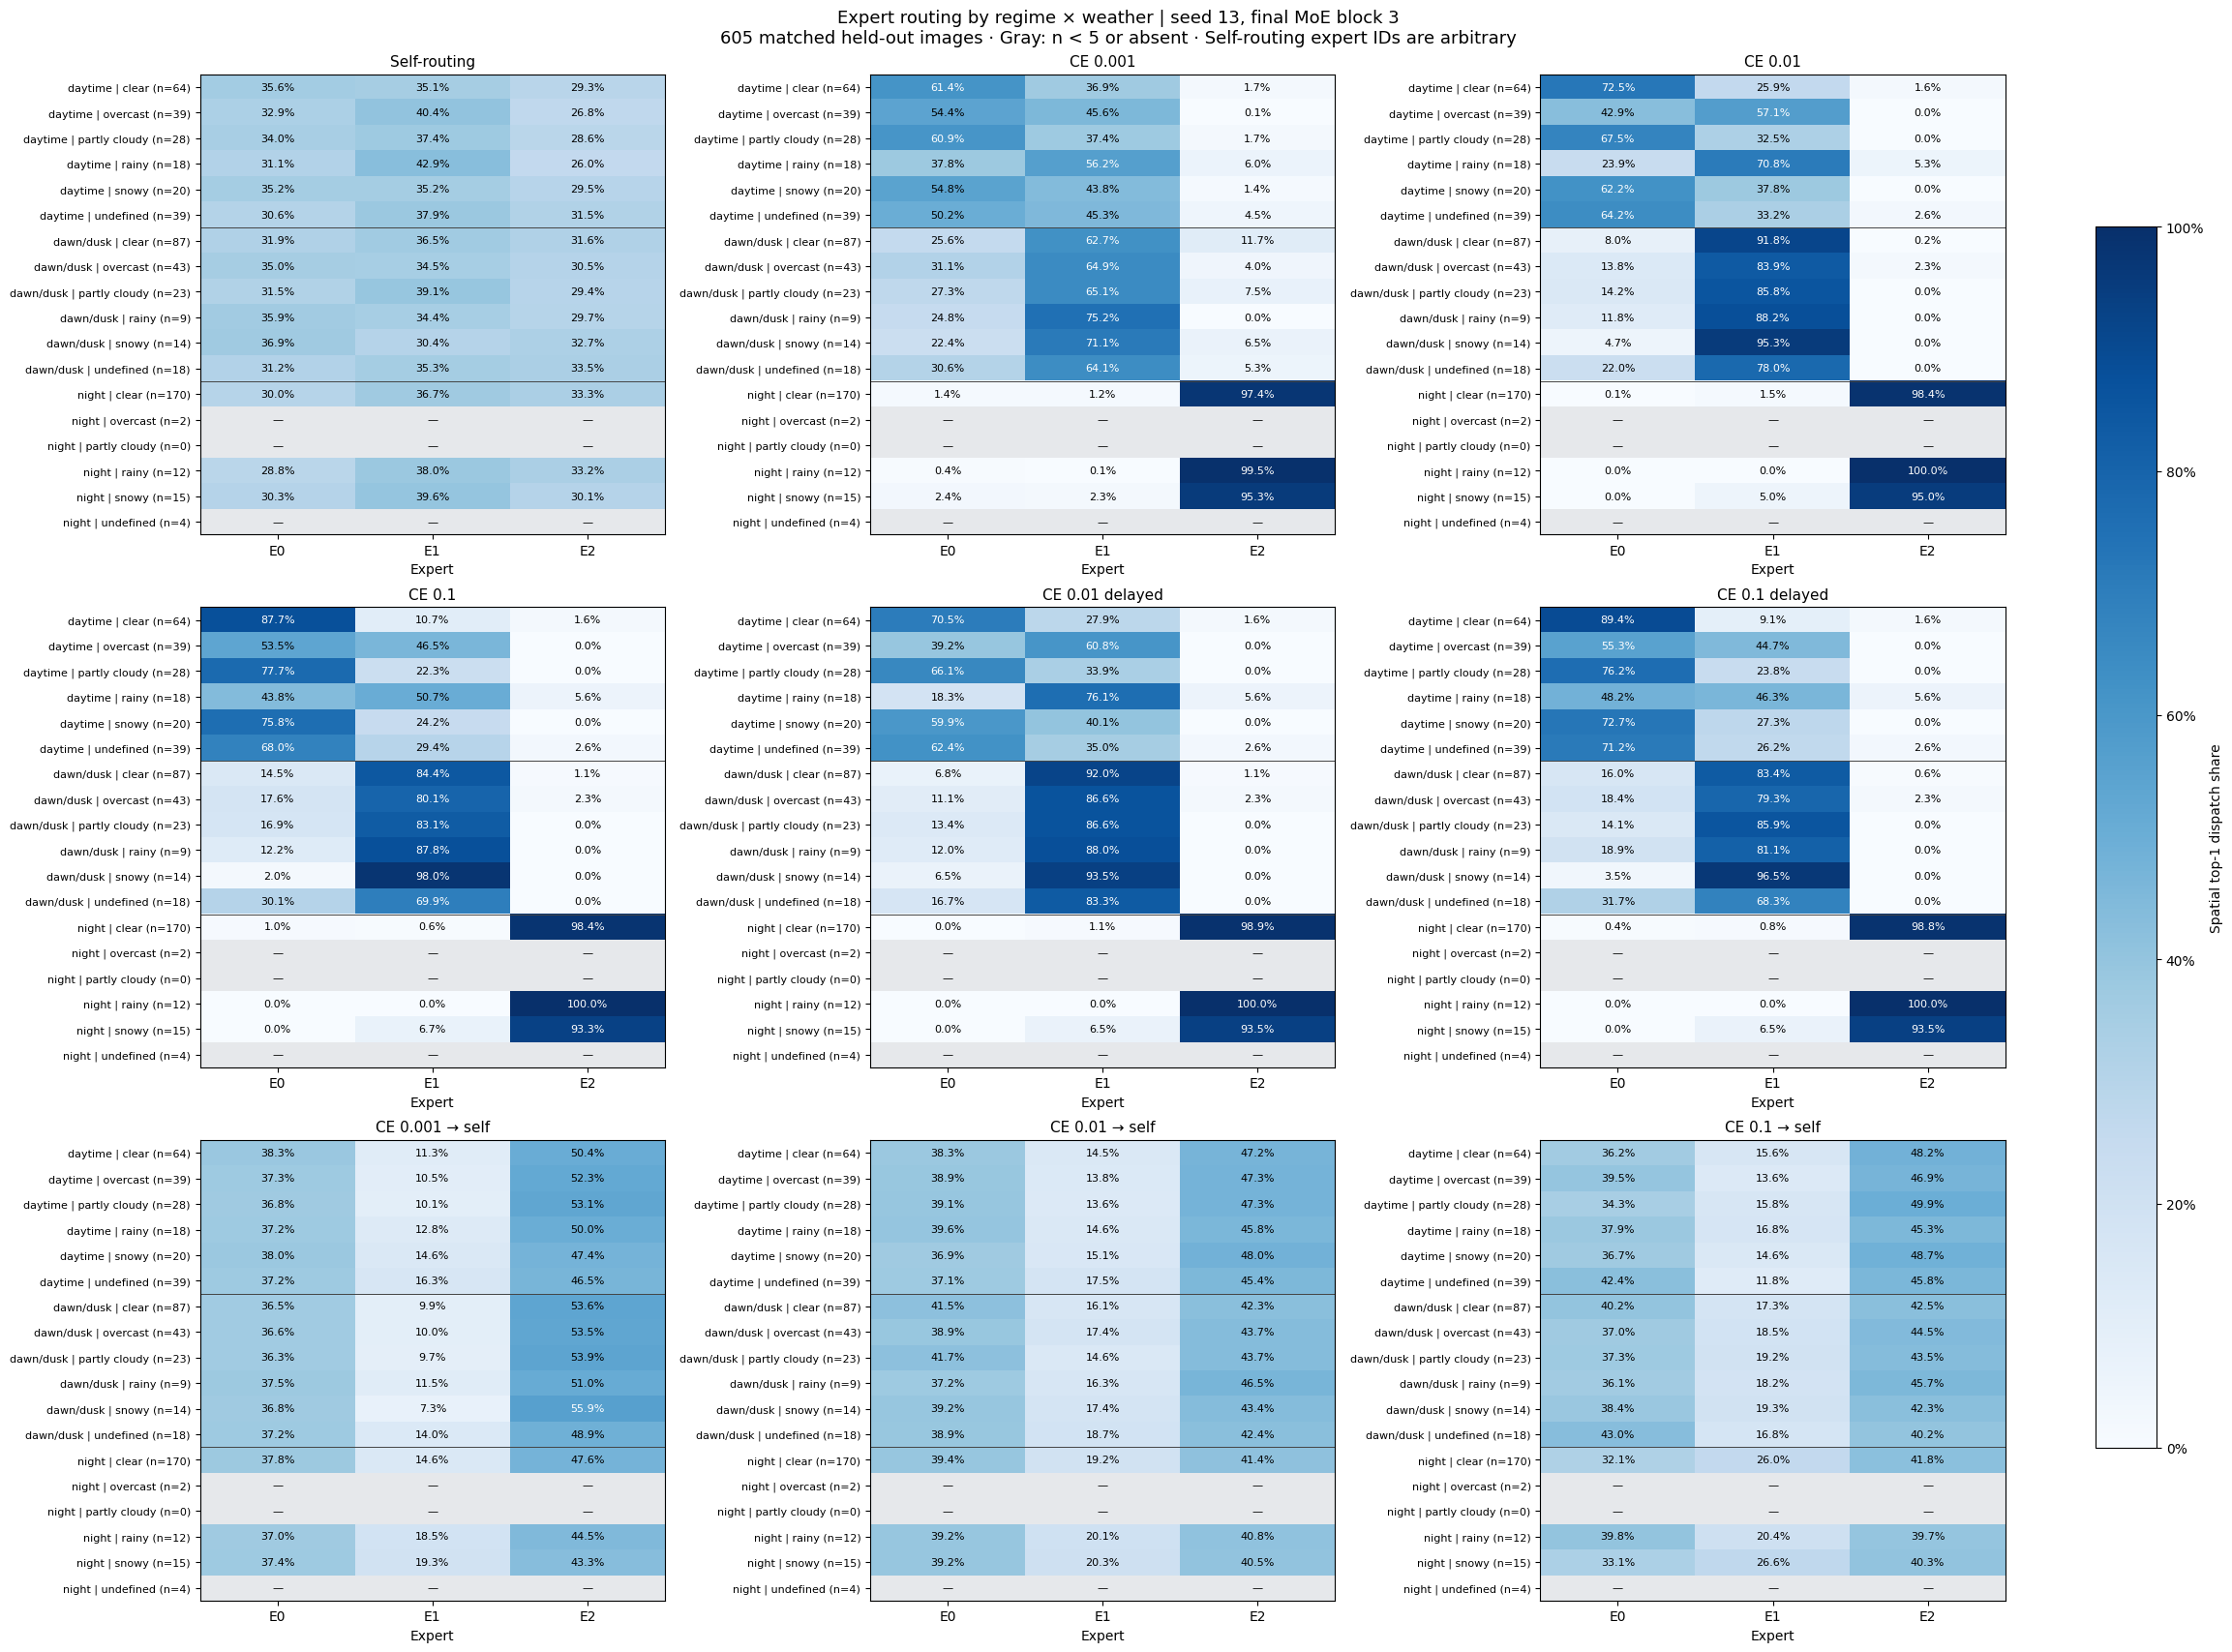

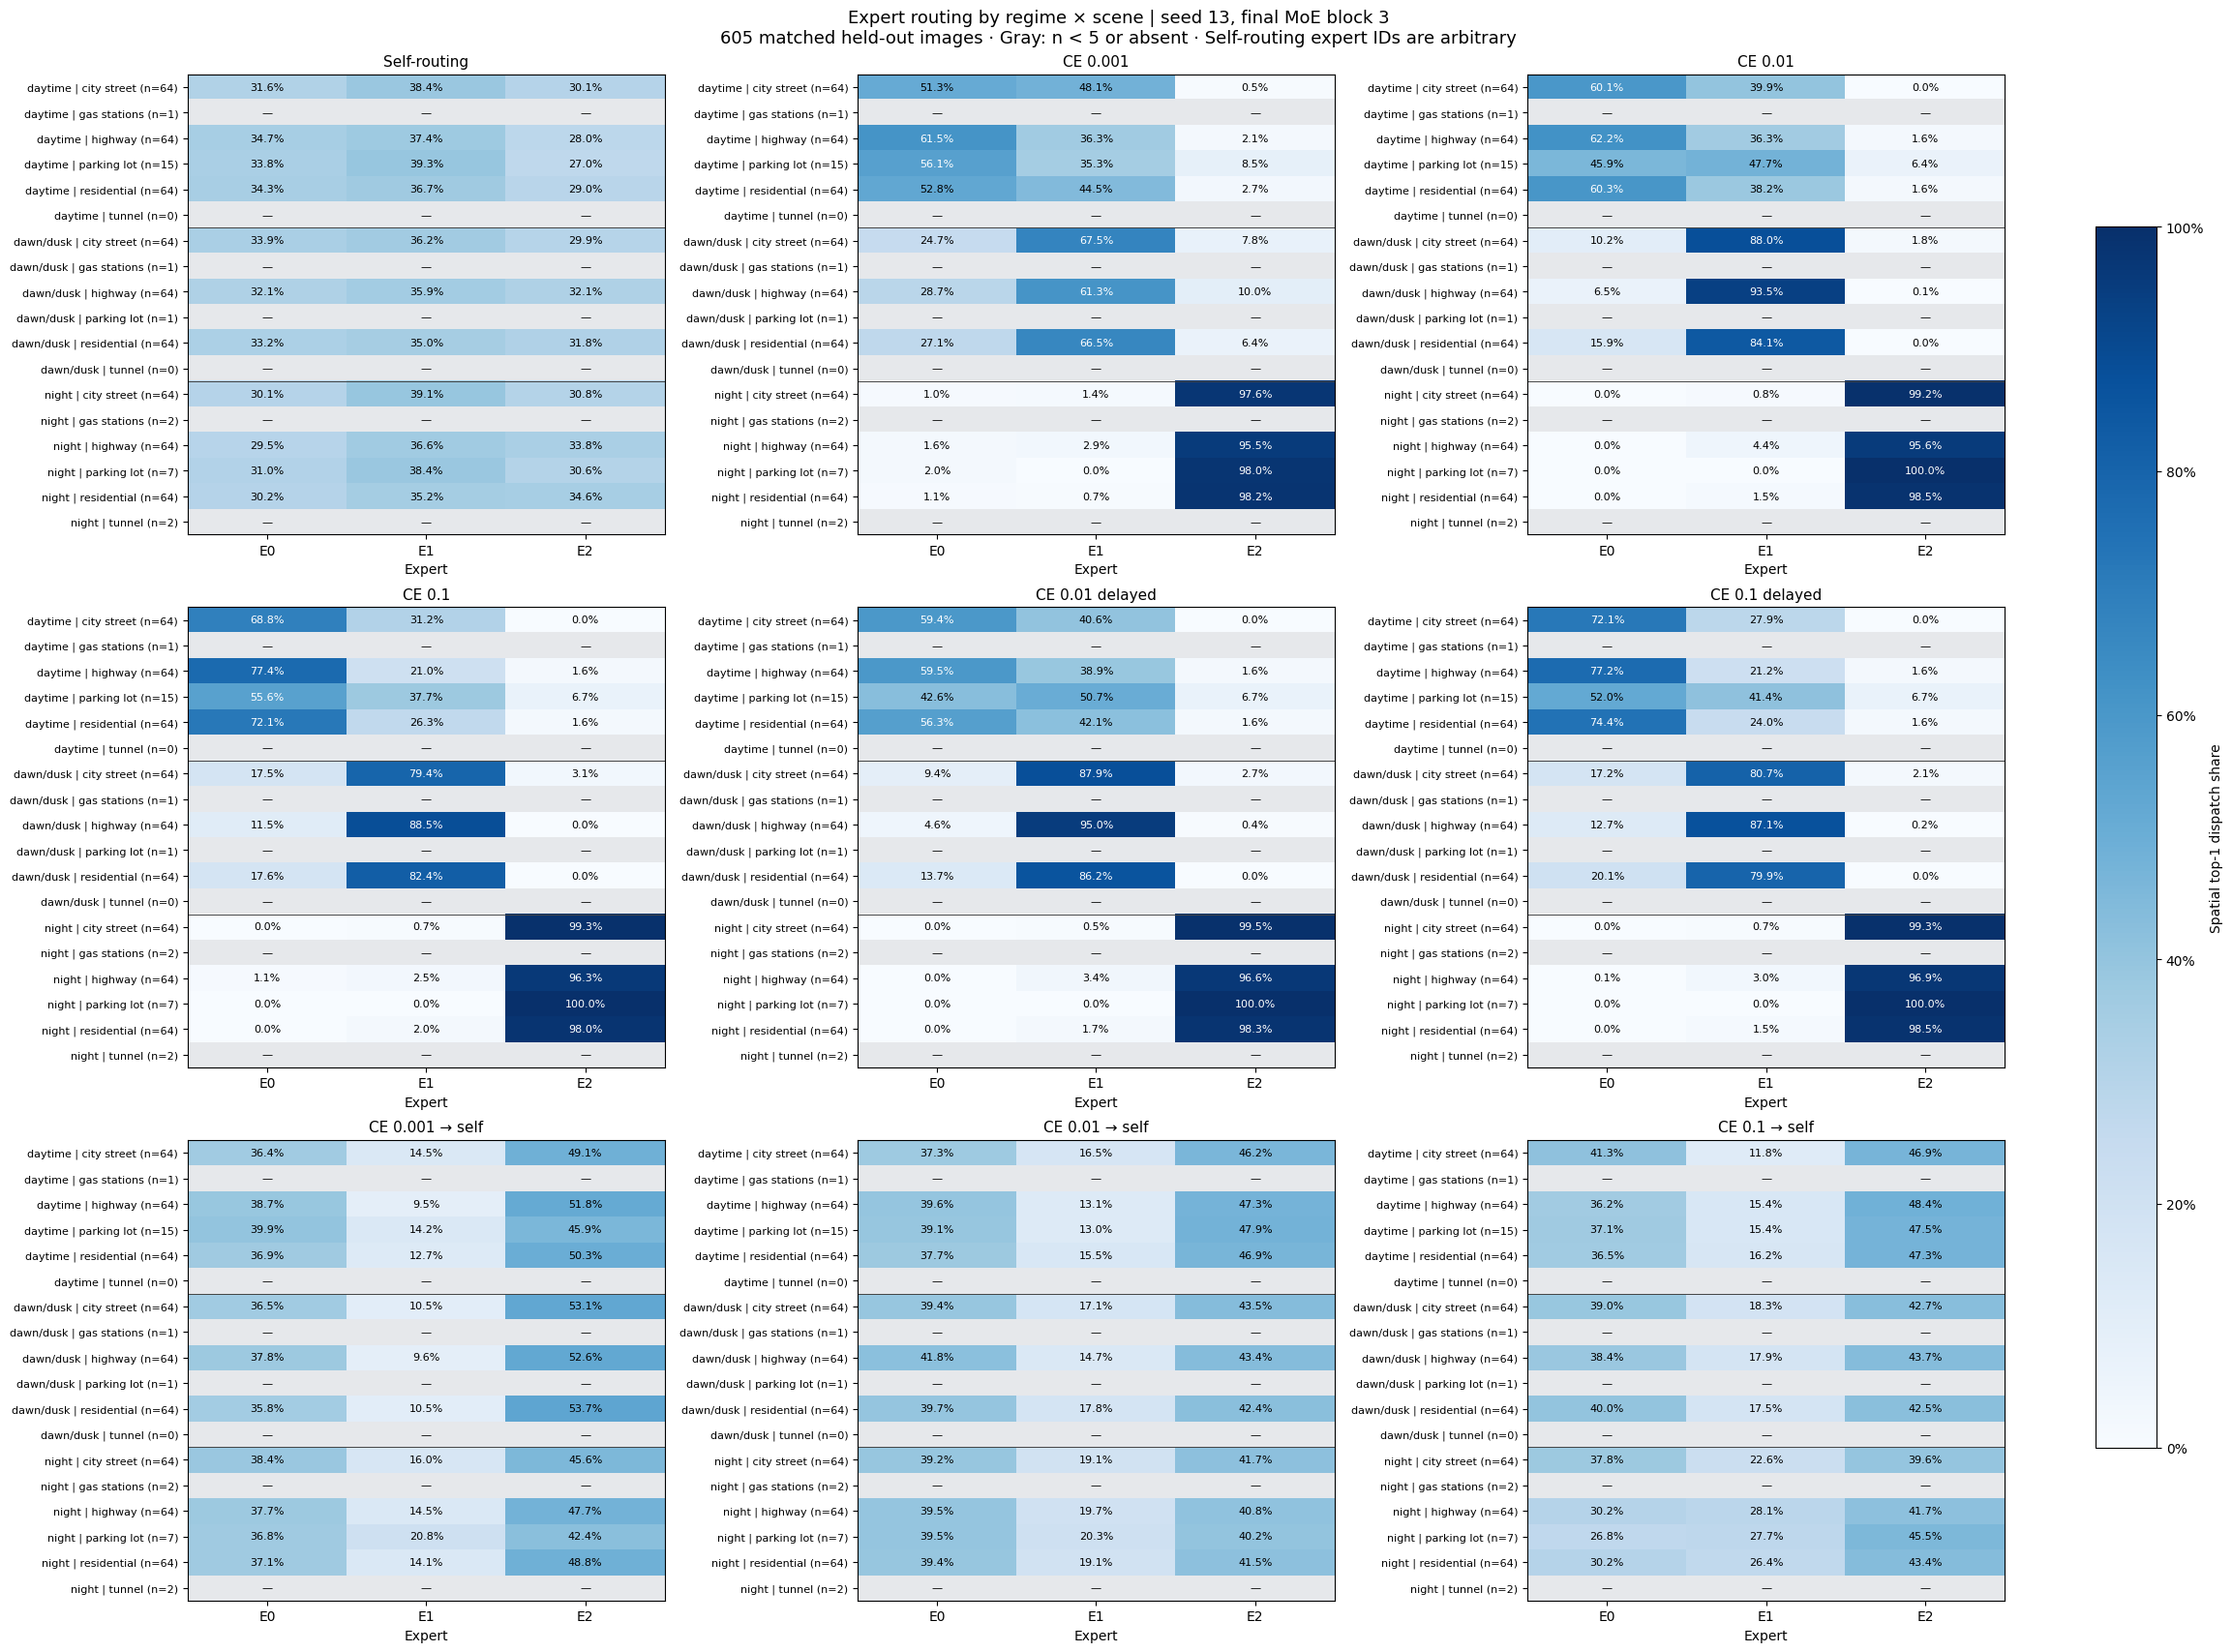

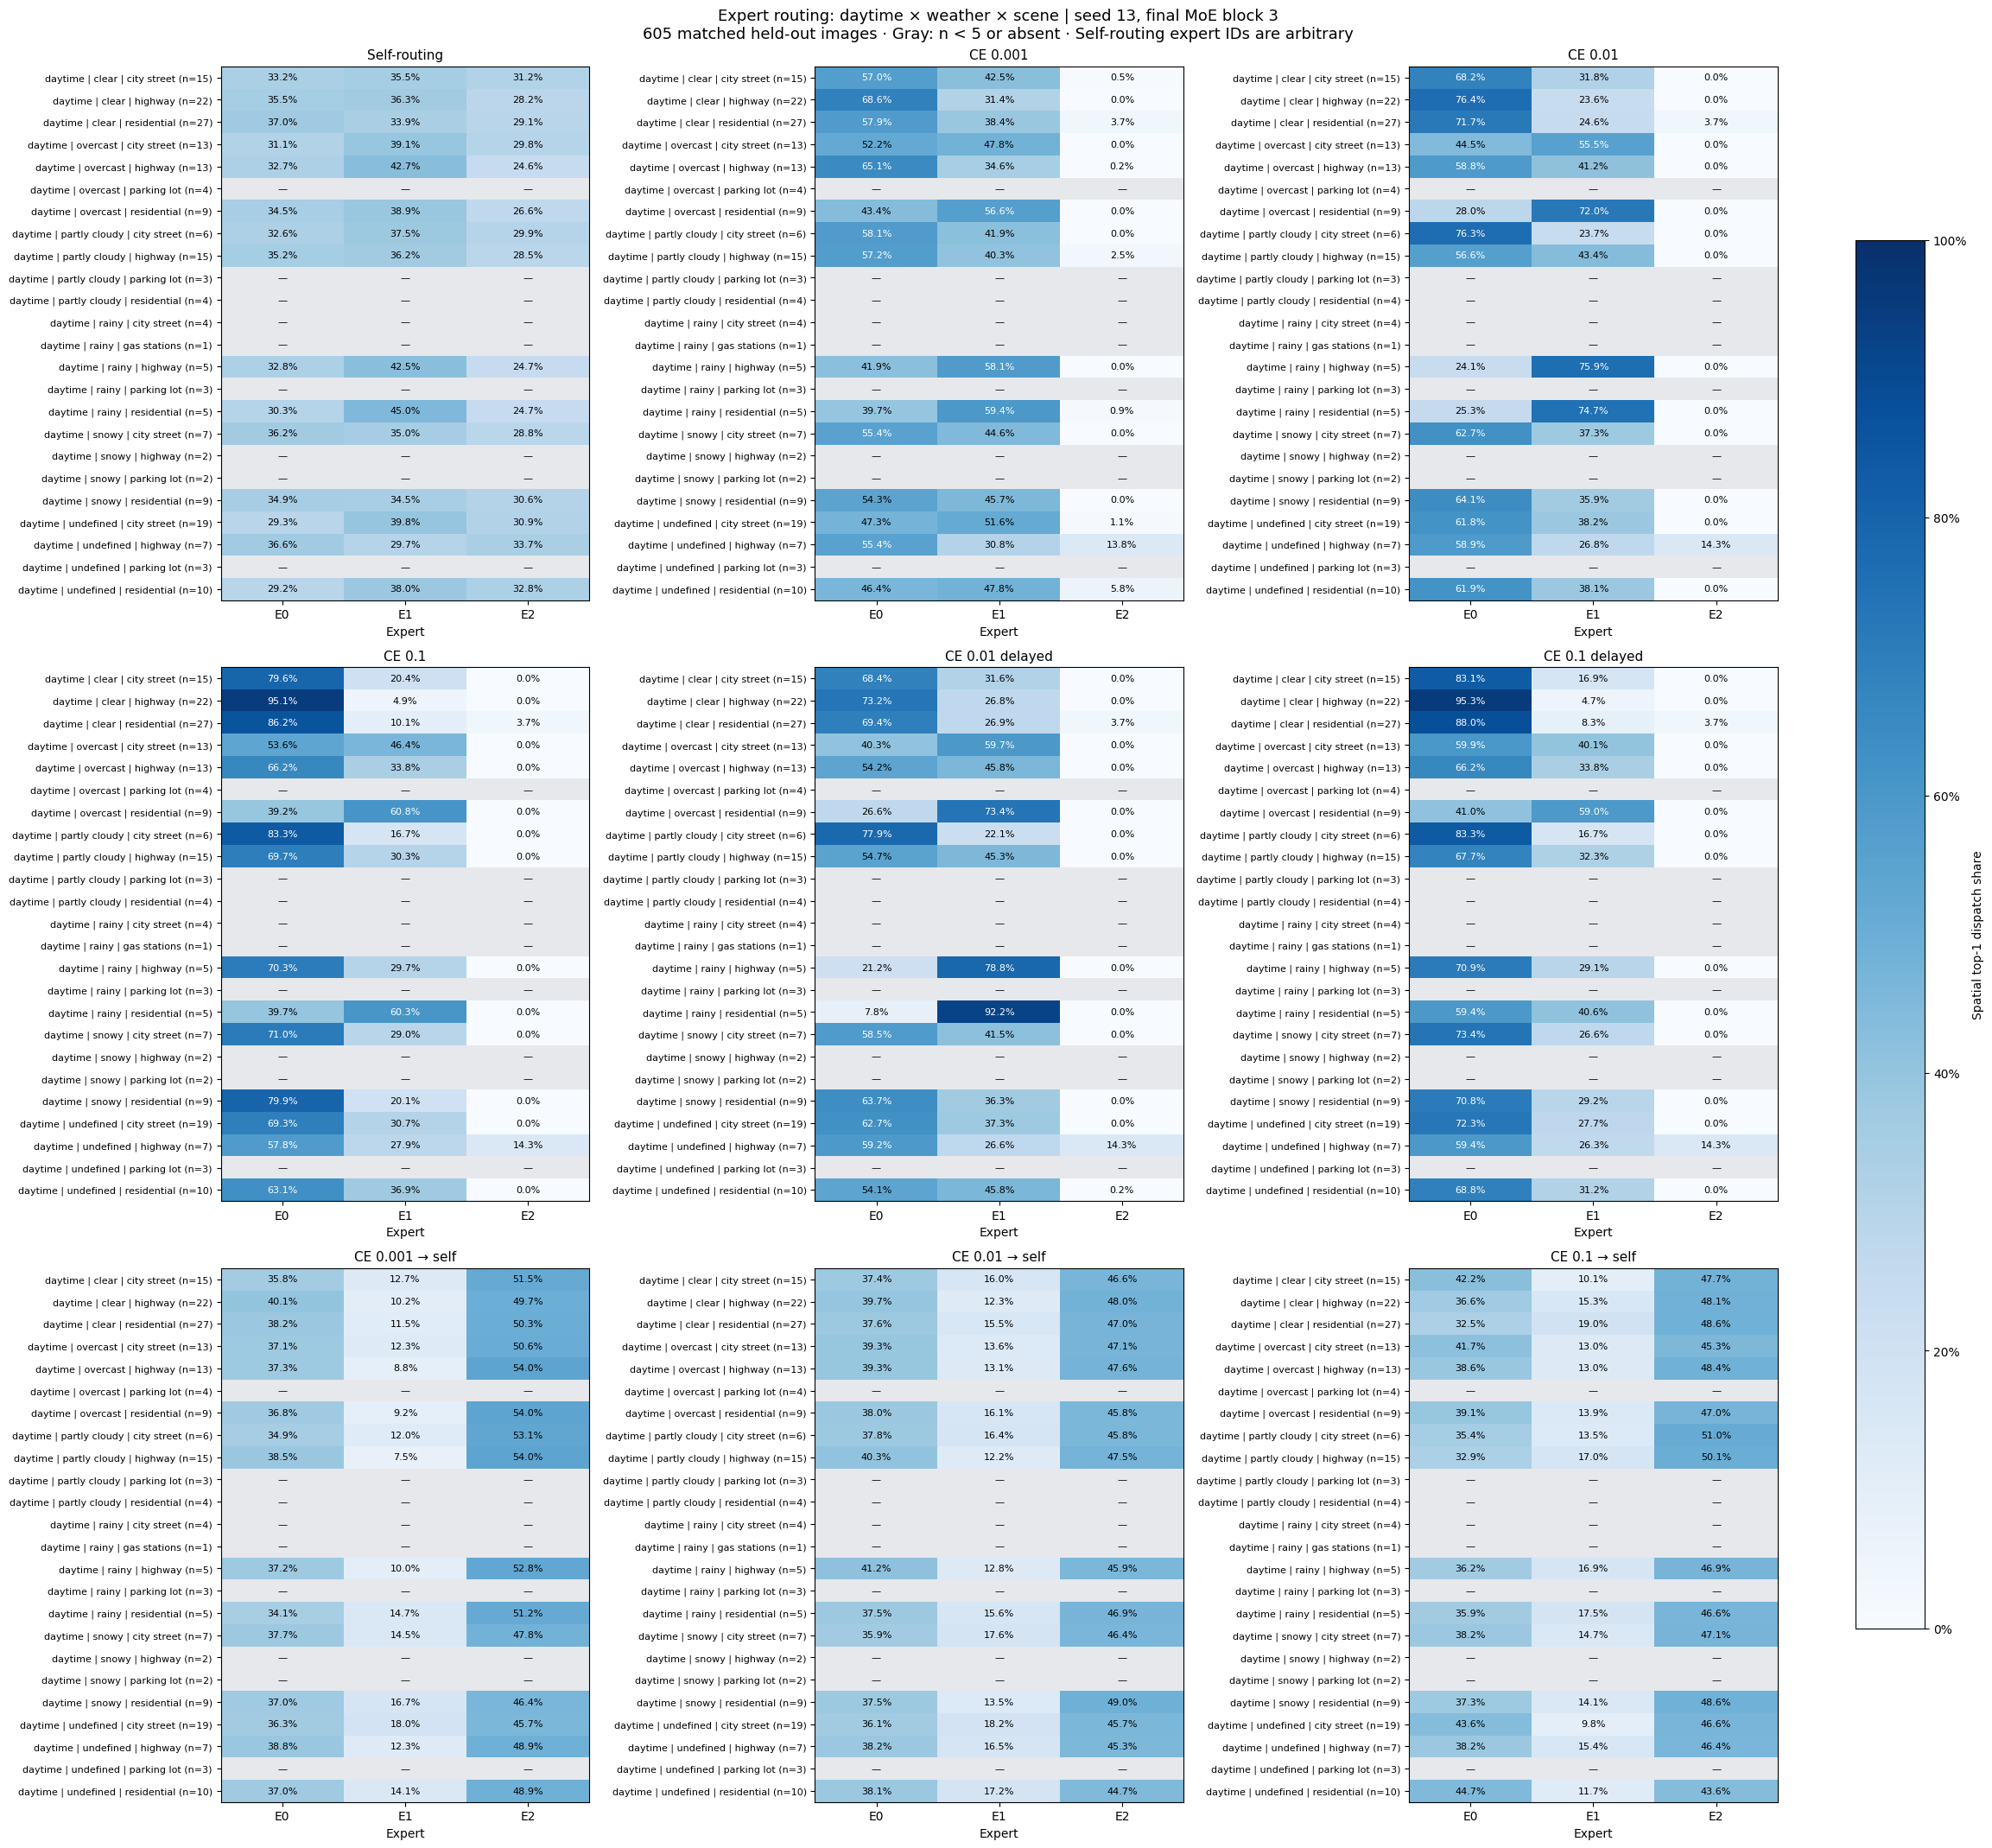

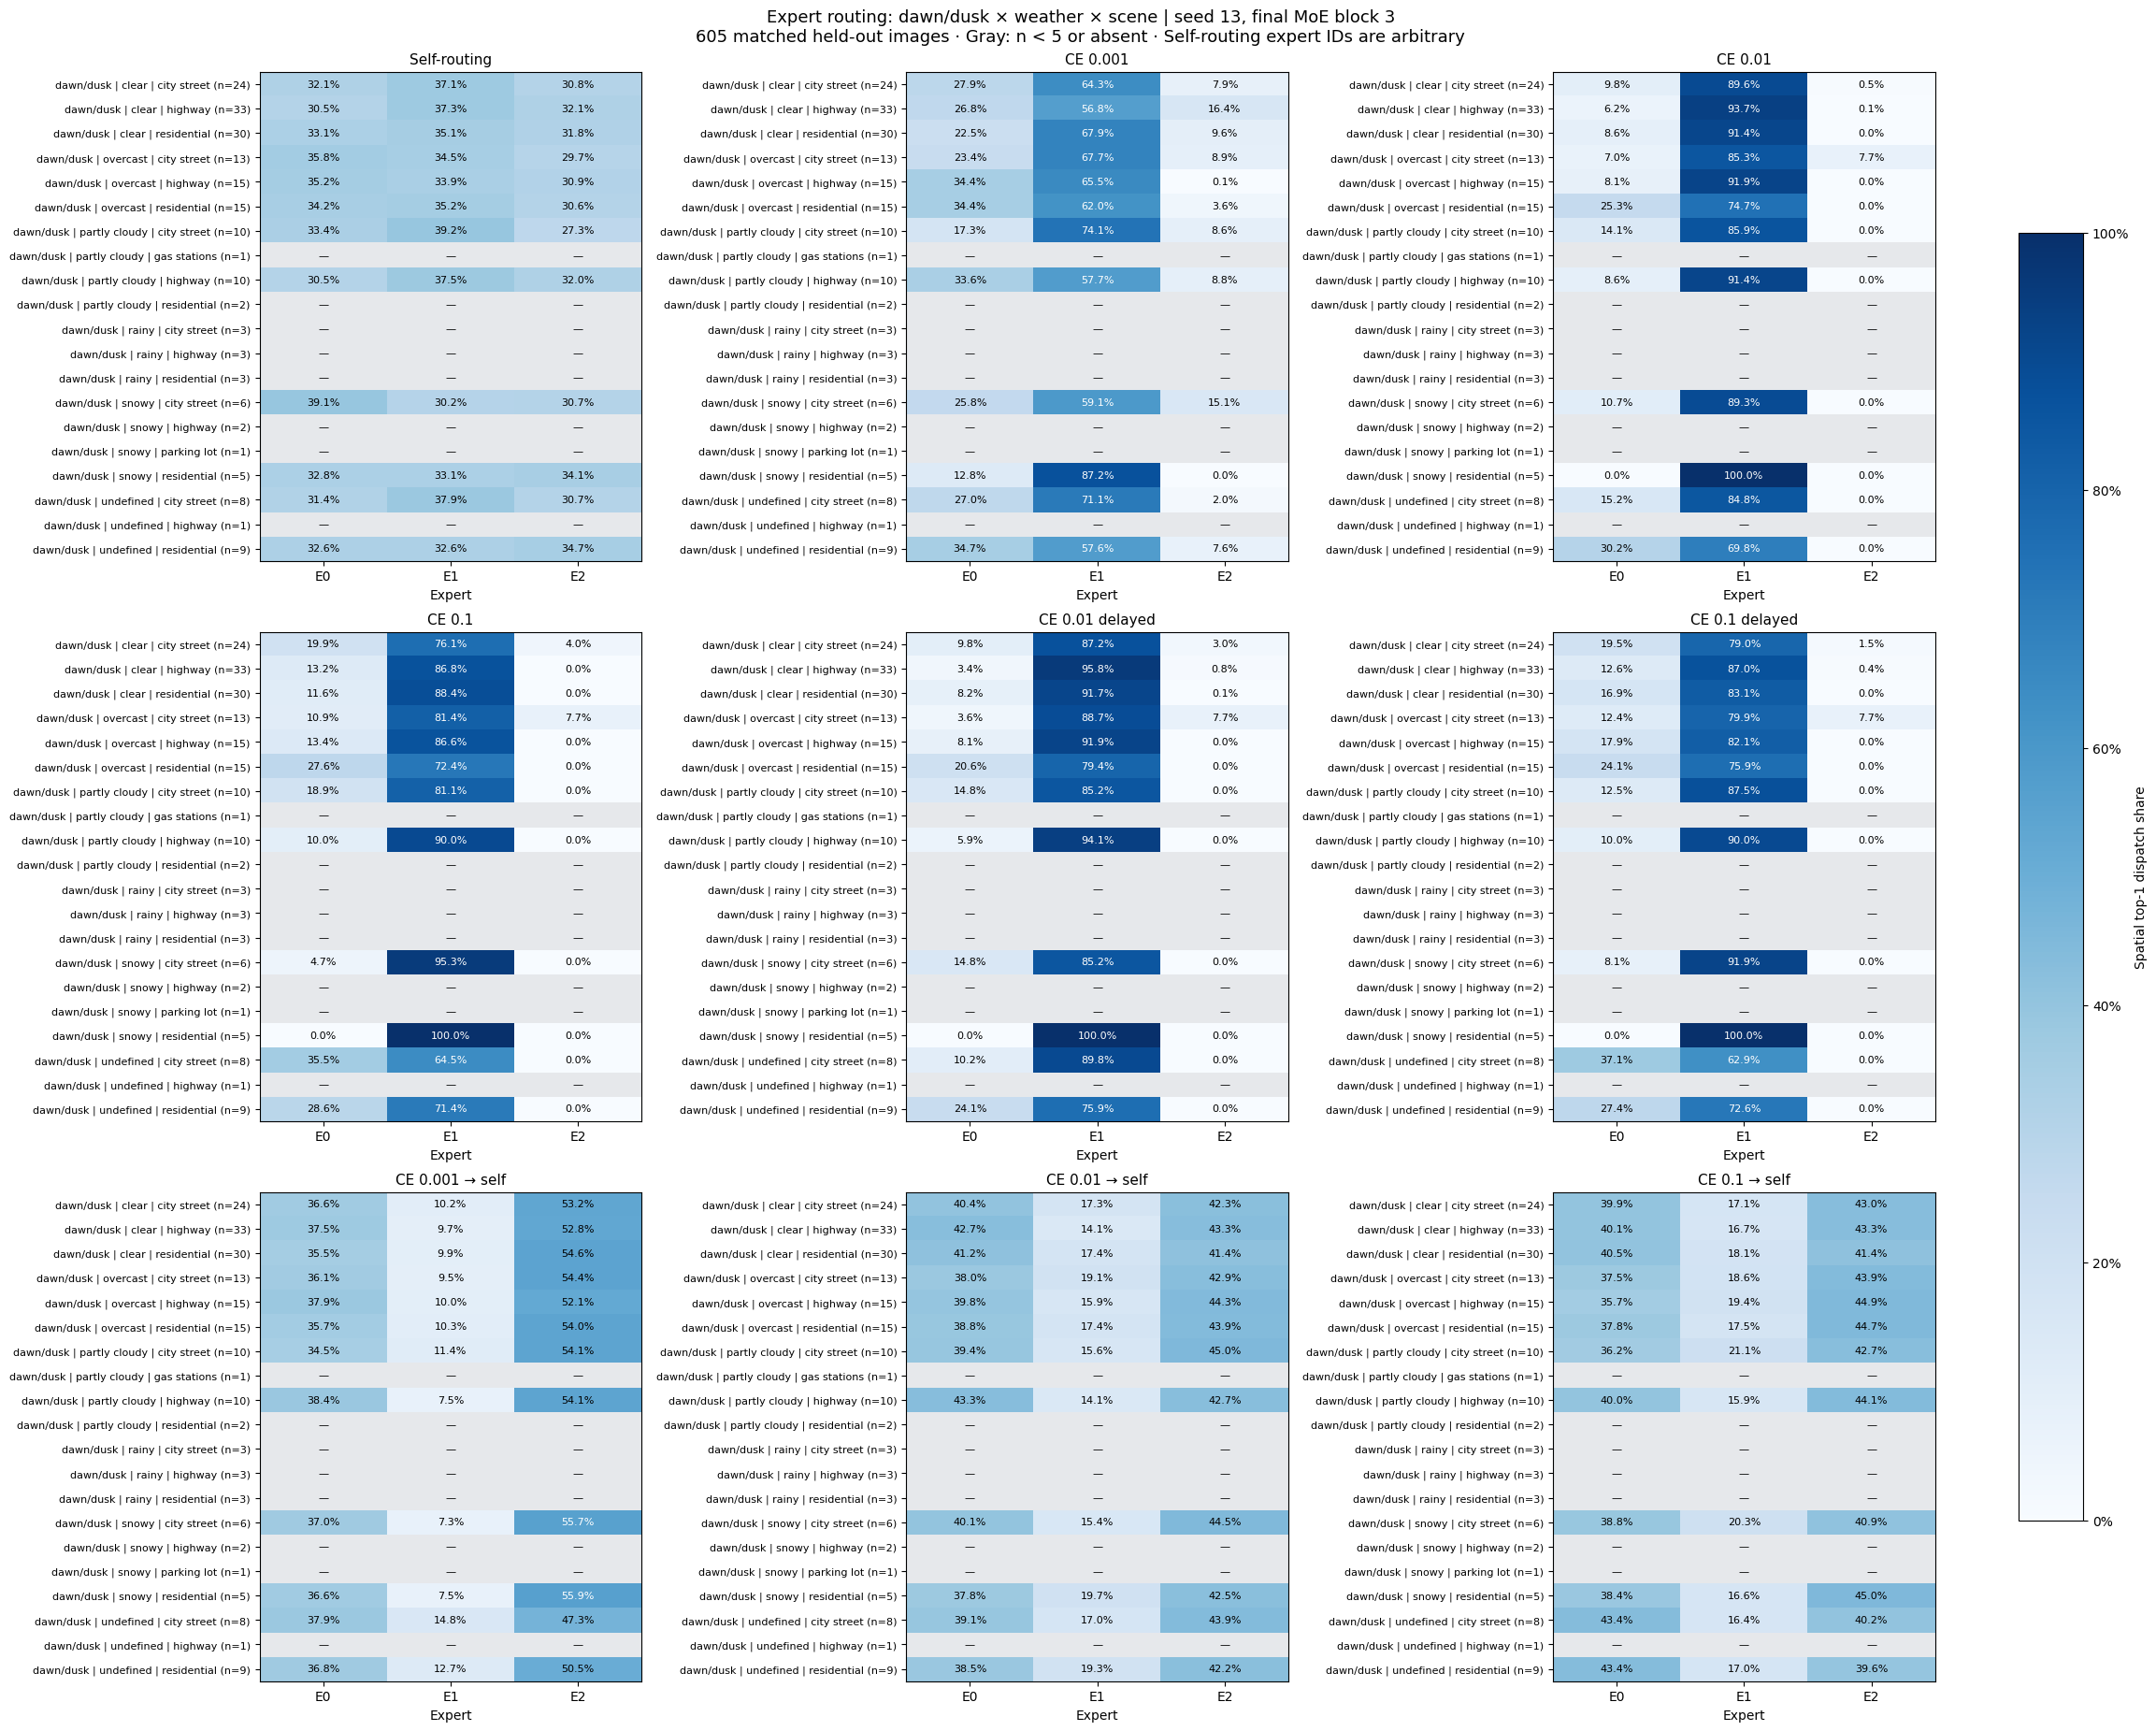

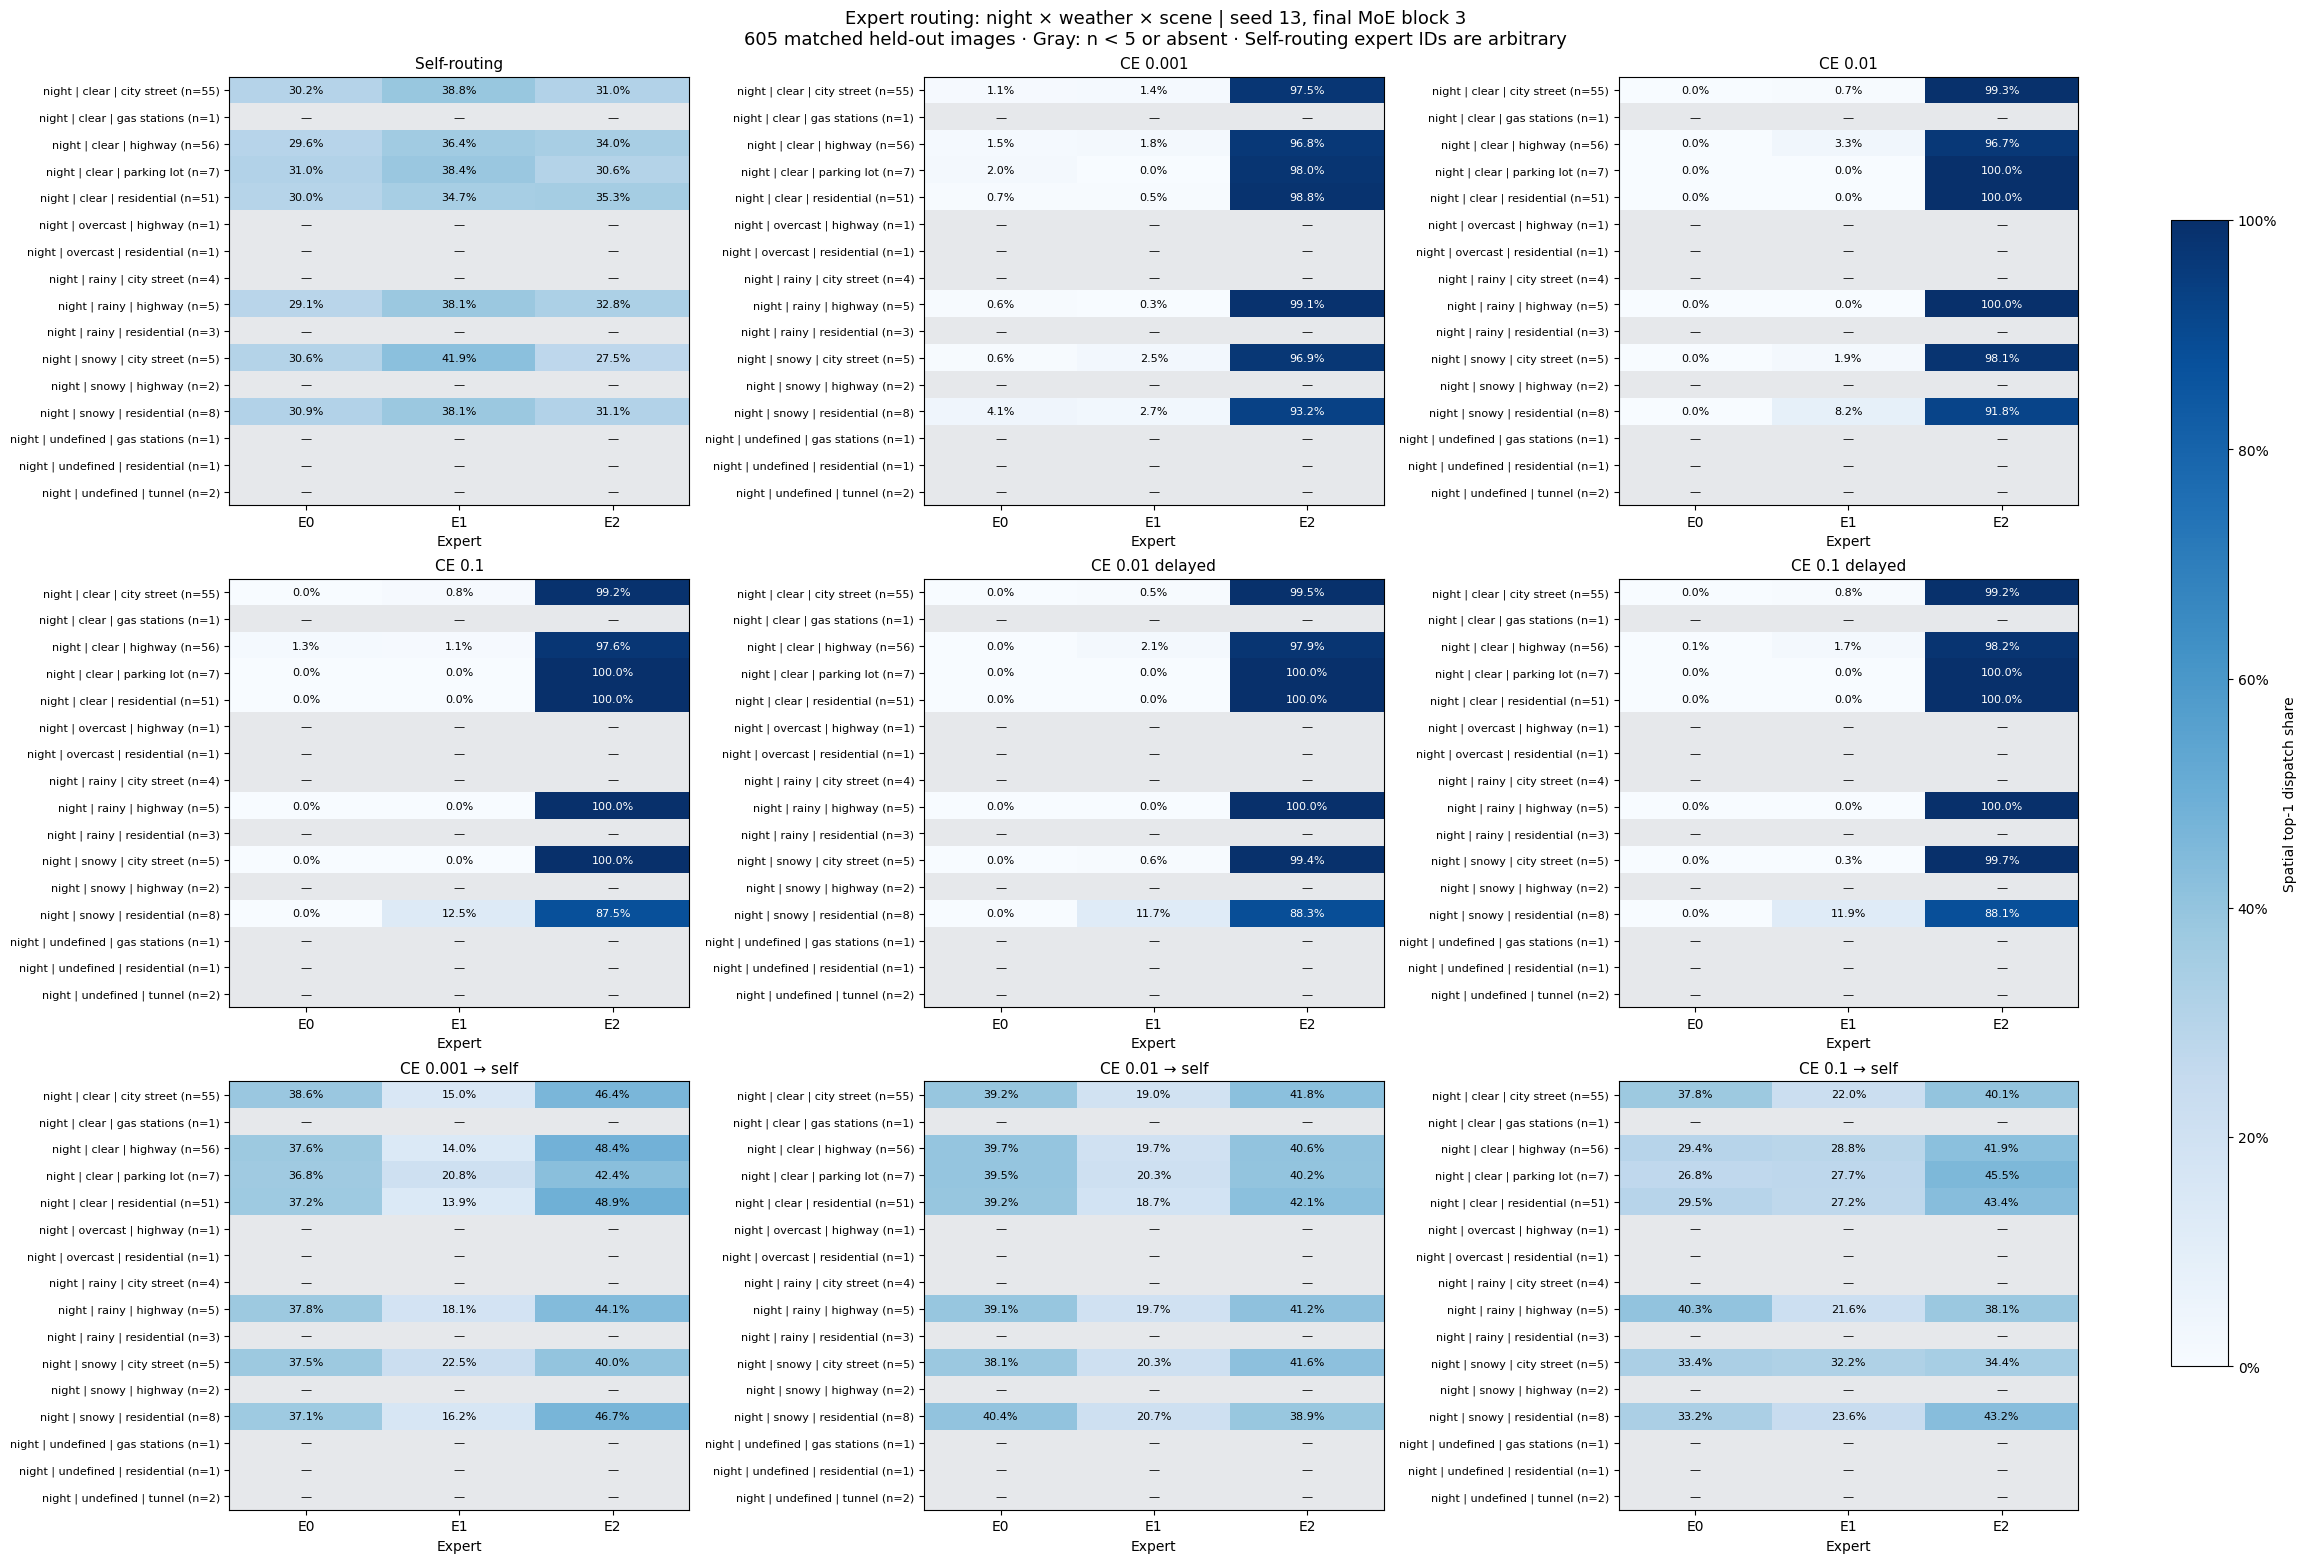

Detailed figures show seeds [13]; the frozen routing cache/CSV summaries include all seeds [13, 42, 101].
Inline figures and PNG/PDF exports are ready: C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-ce-ablation\20261029T075522835366Z\evaluation_visualizations


In [5]:
import itertools as condition_itertools

if (
    condition_min_images < 1
    or condition_metric not in {"dispatch_share", "mean_probability"}
    or not set(condition_plot_seeds).issubset(evaluation_seeds)
):
    raise ValueError("Choose supported routing metric, saved seeds and a positive count threshold.")


def condition_summary(dimensions: list[str]) -> pd.DataFrame:
    """Aggregate actual spatial-token counts and clean probability mass within BDD conditions."""
    measured = condition_routing.assign(active=condition_routing["selected_tokens"].gt(0).astype(int))
    grouped = (
        measured.groupby(["seed", "arm", *dimensions, "expert"], dropna=False)
        .agg(
            images=("clip_id", "nunique"),
            selected_tokens=("selected_tokens", "sum"),
            spatial_tokens=("spatial_tokens", "sum"),
            probability_mass=("probability_mass", "sum"),
            active_images=("active", "sum"),
        )
        .reset_index()
    )
    grouped["dispatch_share"] = grouped["selected_tokens"] / grouped["spatial_tokens"]
    grouped["mean_probability"] = grouped["probability_mass"] / grouped["spatial_tokens"]
    grouped["image_activation_frequency"] = grouped["active_images"] / grouped["images"]
    sums = grouped.groupby(["seed", "arm", *dimensions])[["dispatch_share", "mean_probability"]].sum()
    if not np.allclose(sums, 1, atol=1e-6):
        raise ValueError("Condition-level expert shares must sum to one.")
    return grouped


def condition_plot(
    summary: pd.DataFrame, dimensions: list[str], keys: list[tuple], seed: int, title: str, stem: str
) -> None:
    """Show all six MoEs on a fixed scale; gray cells explicitly mean too few observations."""
    index = pd.MultiIndex.from_tuples(keys, names=dimensions)
    selected = summary.loc[summary["seed"].eq(seed)]
    baseline_counts = (
        selected.loc[selected["arm"].eq("ce_0")].groupby(dimensions)["images"].first().reindex(index).fillna(0)
    )
    cmap = eval_plt.get_cmap("Blues").copy()
    cmap.set_bad("#e6e8eb")
    fig, axes = eval_plt.subplots(3, 3, figsize=(23, max(12, len(keys) * 0.72 + 4)), constrained_layout=True)
    for ax, arm in zip(axes.flat, evaluation_moes, strict=True):
        part = selected.loc[selected["arm"].eq(arm)]
        matrix = part.pivot(index=dimensions, columns="expert", values=condition_metric).reindex(
            index=index, columns=evaluation_experts
        )
        counts = part.groupby(dimensions)["images"].first().reindex(index).fillna(0)
        if not counts.equals(baseline_counts):
            raise ValueError("Condition sample counts differ across compared arms.")
        values = matrix.to_numpy(dtype=float, copy=True)
        values[counts.to_numpy() < condition_min_images] = np.nan
        image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(evaluation_experts)), [f"E{e}" for e in evaluation_experts])
        ax.set_yticks(
            range(len(keys)),
            [" | ".join(map(str, key)) + f" (n={int(n)})" for key, n in zip(keys, counts, strict=True)],
            fontsize=8,
        )
        ax.set_title(evaluation_labels[arm], fontsize=11)
        ax.set_xlabel("Expert")
        for i, j in np.ndindex(values.shape):
            v = values[i, j]
            ax.text(
                j,
                i,
                f"{v:.1%}" if np.isfinite(v) else "—",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if v > 0.55 else "black",
            )
        for i in range(1, len(keys)):
            if keys[i][0] != keys[i - 1][0]:
                ax.axhline(i - 0.5, c="#444444", lw=0.7)
    metric_label = (
        "Spatial top-1 dispatch share" if condition_metric == "dispatch_share" else "Mean continuous router probability"
    )
    fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8, label=metric_label, format="{x:.0%}")
    fig.suptitle(
        f"{title} | seed {seed}, final MoE block {evaluation_block}\n"
        f"{len(condition_panel)} matched held-out images · Gray: n < {condition_min_images} or absent · "
        "Self-routing expert IDs are arbitrary",
        fontsize=13,
    )
    for suffix in ["png", "pdf"]:
        fig.savefig(condition_output / f"{stem}_seed_{seed}_{condition_metric}.{suffix}", dpi=150)
    eval_show(fig)
    eval_plt.close(fig)


condition_regimes = evaluation_regimes[1:]
condition_weather_stats = condition_summary(["regime", "weather"])
condition_scene_stats = condition_summary(["regime", "scene"])
condition_joint_stats = condition_summary(["regime", "weather", "scene"])
for name, stats in [
    ("regime_weather", condition_weather_stats),
    ("regime_scene", condition_scene_stats),
    ("regime_weather_scene", condition_joint_stats),
]:
    stats.to_csv(condition_output / f"{name}_expert_distribution.csv", index=False)
for seed in condition_plot_seeds:
    condition_plot(
        condition_weather_stats,
        ["regime", "weather"],
        list(condition_itertools.product(condition_regimes, sorted(condition_panel["weather"].unique()))),
        seed,
        "Expert routing by regime × weather",
        "weather",
    )
    condition_plot(
        condition_scene_stats,
        ["regime", "scene"],
        list(condition_itertools.product(condition_regimes, sorted(condition_panel["scene"].unique()))),
        seed,
        "Expert routing by regime × scene",
        "scene",
    )
    for regime in condition_regimes:
        keys = sorted(
            set(
                condition_joint_stats.loc[
                    condition_joint_stats["regime"].eq(regime), ["regime", "weather", "scene"]
                ].itertuples(index=False, name=None)
            )
        )
        condition_plot(
            condition_joint_stats,
            ["regime", "weather", "scene"],
            keys,
            seed,
            f"Expert routing: {regime} × weather × scene",
            "joint_" + regime.replace("/", "-"),
        )
print(
    f"Detailed figures show seeds {condition_plot_seeds}; "
    f"the frozen routing cache/CSV summaries include all seeds {evaluation_seeds}."
)
print(f"Inline figures and PNG/PDF exports are ready: {evaluation_output}")

## Completed CE-first experiment: results and interpretation

Saved extension: `20261029T075522835366Z`. All **nine new models** used the complete 70,000-image training
panel, 3,282 updates and 210,000 image exposures per model, across seeds 13/42/101. The other
21 model results are the unchanged completed controls, copied with explicit checkpoint provenance.
The classification objective is an auxiliary term during the first phase, while reconstruction
and balancing remain active throughout. There is no optimizer, router or expert reset at release.

Means across the three paired seeds, on the same 605 query images:

| Arm | Linear (%) | Frozen kNN (%) | Masked RGB MSE ↓ | RankMe |
|---|---:|---:|---:|---:|
| Dense | 34.88 | 36.64 | 0.02177 | 20.31 |
| Self-routing throughout | 35.15 | 36.58 | 0.02192 | 20.55 |
| Constant CE 0.1 | 33.50 | 33.33 | 0.03004 | 15.22 |
| CE 0.001 → self | 35.15 | 35.98 | 0.02187 | 20.76 |
| CE 0.01 → self | 33.88 | 36.64 | 0.02197 | 21.26 |
| CE 0.1 → self | 33.11 | 35.54 | 0.02378 | 20.78 |

**Compared with constant strong CE, release recovers much of the reconstruction/rank penalty.**
At peak CE 0.1, final MSE is 20.8% lower, kNN changes by +2.20 percentage points,
and linear probing changes by -0.39 points. The paired 95% intervals for those two
accuracy differences include zero; these three seeds do not establish an accuracy improvement.
The MSE and RankMe paired intervals for CE-first versus constant CE 0.1 exclude zero in this run.

**CE first does not consistently outperform self-routing throughout.** At 0.001, its mean linear
accuracy equals self-routing, while kNN is lower. At 0.01, mean kNN is nearly unchanged but linear
accuracy is lower. Peak CE 0.1 still leaves higher MSE and lower scene accuracy than self-routing.
These results support testing CE strength and supervision duration separately, not assuming a
classification warm-up will improve downstream representations.

**The router is free to leave the original class mapping.** All post-release weighted CE gradients
are zero, while reconstruction gradients on router parameters remain nonzero. On seed 13's fixed
expert panel, E2 receives 96.5% of night-patch dispatches with constant CE 0.1, versus 41.5% with
CE-first 0.1. That is a routing statistic, not scene accuracy; early expert identities need not
retain their supervised meanings once CE is removed. Inspect each seed's heatmaps for the actual pattern.

Early CE has a smaller supervision dose: 624.5 × peak coefficient, versus 3,282 × peak for constant
CE and 2,657.5 × peak for delayed CE. The schedules therefore test different combinations of timing
and total supervision, not timing alone. The query panel was reused during this ablation; any
selected setting needs confirmation on an independent split and a longer training budget.

Reproducibility checks verify identical initialization and augmentation/mask fingerprints.
Pre-release RGB scores match their constant-CE controls within numerical tolerance. One
pre-release kNN prediction differs (seed 101, CE 0.1, update 250); GPU readouts are therefore
not claimed to be bitwise repeatable. The CPU checkpoint/resume check across the handoff
does reproduce every final weight tensor exactly.


**Historical findings for the original seven-arm run. CE-first extension results appear above.**

## Findings from the completed full-data run

Saved run: `20261029T064029914726Z`, seeds 13/42/101, all 70,000 training stills,
3,282 updates per model. Values below are means across three seeds on the same
605-image query panel; the scene-probe support set has 134 images.

| Arm | Linear (%) | Frozen kNN (%) | Masked RGB MSE (lower better) | RankMe |
|---|---:|---:|---:|---:|
| Dense | 34.88 | 36.64 | 0.02177 | 20.31 |
| Self-routing | 35.15 | 36.58 | 0.02192 | 20.55 |
| CE 0.001 | 34.33 | 37.02 | 0.02188 | 21.01 |
| CE 0.01 | 34.16 | 35.43 | 0.02266 | 22.39 |
| CE 0.01 delayed | 34.44 | 34.82 | 0.02245 | 21.88 |
| CE 0.1 | 33.50 | 33.33 | 0.03004 | 15.22 |
| CE 0.1 delayed | 33.61 | 32.12 | 0.02978 | 16.99 |

**CE strength matters in this setup.** Reducing CE from 0.1 to 0.001 largely removes
the reconstruction penalty and restores kNN performance. Compared with self-routing,
CE 0.001 has a small mean kNN gain (+0.44 percentage points) and lower linear accuracy
(-0.83 points); both paired 95% intervals include zero. These results do not establish
a downstream benefit from classification routing. Delaying CE does not consistently
improve performance, and the delayed arms also receive less cumulative CE supervision.

**The diagnostics refine the proposed explanation.** At CE 0.1, the weighted CE gradient
is substantially larger than the reconstruction gradient on router and shared encoder
parameters. Alignment varies across batches, so the evidence does not support a claim
of consistently opposing gradients. These are raw pre-clipping gradients, not the
effective AdamW update. Greater gate confidence and weighted expert-output amplitude
also accompany the degradation; this association does not isolate a causal mechanism.
Higher RankMe at CE 0.01 does not translate into better scene accuracy.

These findings apply to this architecture, short training budget and evaluation panel.
A coefficient chosen from this sweep needs confirmation on an independent split.
